<a href="https://colab.research.google.com/github/KathituCodes/SIM-Swap-Fraud-Detection-in-M-Pesa/blob/main/SIM_Swap_Fraud_Detection_in_Kenya's_M_Pesa_Ecosystem_Using_Supervised_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SIM Swap Fraud Detection in Kenya's M-Pesa Ecosystem

## What is SIM Swap Fraud?

Imagine waking up to find your M-Pesa wallet is empty, your Fuliza limit has
been maxed out, and your M-Shwari savings are gone. You did not make any of
those transactions. Someone else did, using your phone number.

This is SIM swap fraud. A criminal calls your mobile network operator,
pretends to be you, and convinces them to move your phone number to a SIM
card the criminal controls. From that moment, every OTP sent to your number
goes to the fraudster. They reset your PIN, bypass your security, and drain
everything attached to your number before you even wake up.

In Kenya, this is not a rare edge case. The CBK's 2024 Financial Sector
Stability Report documented KSh 810 million in direct mobile banking losses
in a single year, a 344% increase, with SIM swap fraud identified as the
primary driver. In one documented case, over 123,000 fraudulently registered
SIM cards were used to draw down Fuliza loans totalling KSh 500 million
before the SIMs were switched off.

Existing defenses such as manual transaction freezes and customer-reported
SIM blocks are too slow. Fraud that executes in under 40 minutes cannot be
stopped by a process that takes hours.





## Business Understanding

### The Problem

M-Pesa processes over 1.5 billion transactions monthly across Kenya. That
scale makes it the most valuable and the most targeted mobile money platform
on the continent. SIM swap fraud has emerged as the dominant attack vector,
not because it is technically sophisticated, but because it exploits a human
gap: the identity verification process at mobile network operator walk-in
centers.

A fraudster walks in with a fake ID, convinces a customer care agent that
they are the account owner, and leaves with a new SIM card registered to the
victim's number. From that point, every OTP sent to that number goes to the
fraudster. PINs are reset. Wallets are drained. Credit facilities are
exhausted. The entire attack completes in under 40 minutes.

The CBK's 2024 Financial Sector Stability Report put the damage at KSh 810
million in mobile banking losses in a single year, a 344% increase. Kenya
has been identified as the highest-risk mobile money market in Africa by
cybersecurity firm Evina, with 51% of transactions flagged as suspicious.

### Why Lenders are the Hardest Hit

A standard fraud attack is limited to the victim's wallet balance. SIM swap
goes further because M-Pesa is not just a wallet. It is a gateway to credit.

Once a fraudster controls the number, they draw down every attached credit
facility simultaneously: Fuliza overdrafts, M-Shwari loans, KCB M-Pesa
credit, and Timiza. Every one of these becomes an instant Non-Performing Loan
with zero recovery probability. In one documented DCI case, 123,000
fraudulently registered SIM cards drew down KSh 500 million in Fuliza loans
before being shut off.

Safaricom has since been held liable by the High Court for losses linked to
delayed SIM disabling. The legal message is clear: reactive security is no
longer a defensible position.

### Why Existing Defenses Fail

Manual transaction freezes, customer-reported SIM blocks, and post-hoc
investigations are all reactive. They require either the victim or a human
operator to notice and act. Against an attack that completes in 40 minutes,
often at 2am while the victim is asleep, these processes are structurally
too slow.

The missing layer is proactive: a system that watches every transaction in
real time and flags anomalous patterns before the money leaves the account.

### Key Objectives

This project builds that layer. Specifically:

- Detect fraudulent M-Pesa transactions that follow a SIM swap behavioral
  pattern before financial damage is complete
- Engineer proxy features that simulate SIM swap signals from available
  transaction data, since the dataset lacks native signals like IMEI changes
  or SIM swap timestamps
- Train a supervised classification model capable of distinguishing fraud
  from legitimate transactions under a realistic 33:1 class imbalance
- Build a regulatorily interpretable scorecard that satisfies CBK audit
  requirements alongside the primary detection model
- Deploy a fraud scoring system that flags high-risk transactions in real time

### Who This is Built For

**Fintech operators and digital lenders** such as Safaricom, NCBA, and KCB
who need to reduce NPLs from fraudulent Fuliza and M-Shwari drawdowns.

**End users** who expect their wallets and credit lines protected without
friction on legitimate transactions.

**Regulators** including the CBK and CA Kenya who require fraud detection
systems aligned with Kenya's National Cybersecurity Strategy 2022-2027 and
KYC compliance requirements.

### Success Metrics

| Metric | Target | Why |
|---|---|---|
| Recall | 0.80 | Missing a fraud is more costly than a false alarm |
| Precision | 0.70 | Reduces alert fatigue on legitimate transactions |
| AUC-ROC | 0.90 | Measures overall fraud vs legitimate separation |
| F1-Score | Maximise | Balances precision and recall under class imbalance |


## The Core Challenge

Transaction logs do not contain SIM swap signals directly. There is no column
that says "SIM was swapped 10 minutes ago." What transaction logs do contain
is behaviour, and SIM swap attacks leave a very specific behavioural signature:

- The fraudster moves as much money as possible in as few transactions as possible
- The account balance drops to near zero almost instantly
- The transaction amounts are unusually large relative to the account's normal activity
- What remains in the account after the transaction is almost nothing

This project engineers four features from the raw transaction data that
capture this exact pattern. These features do not exist in the original
dataset. They are calculated from the data we have.

## The Four Engineered Features

**1. Balance Depletion Rate**
How much of the sender's total balance was spent in this single transaction?
A normal person buying groceries might spend 5% of their balance. A SIM swap
fraudster draining an account spends 90% or more in one move.

**2. Sender Balance Ratio**
What fraction of the original balance is left after the transaction?
A ratio of 0.95 means 95% of the money is still there. Normal.
A ratio of 0.02 means only 2% is left. The account was nearly emptied.

**3. Is Balance Wipeout**
A simple yes or no flag. Did the sender's balance drop below KES 100 after
this transaction? If yes, the account was essentially drained to zero.
This single feature turned out to be the strongest fraud predictor in the
entire dataset.

**4. Is High Value**
Was this transaction in the top 10% of all transaction amounts?
Fraudsters do not make small careful transfers. They move large amounts fast.

## Why Two Models?

The project deploys two models that work together, not one.

**XGBoost — The Blocker**
XGBoost is a powerful tree-based machine learning model. In this project it
achieves a Precision of 0.99 on the held-out test set: 4 false positives out of
23,298 legitimate transactions. Nearly every transaction it flags is a genuine
fraud case.

This makes it suited to automated real-time blocking. A sanity check in Phase 3
shows that most of this precision comes from one signal, the balance wipeout,
so the result should be re-validated on real transaction data before relying on it.

**WoE Logistic Regression Scorecard — The Explainer**
XGBoost is powerful but cannot explain itself. If a CBK regulator asks why a
specific customer's transaction was blocked, XGBoost has no answer.

The WoE (Weight of Evidence) scorecard can answer that question. It converts
each feature into a score that represents how much that specific value
contributed to the fraud flag. A credit officer can look at the scorecard
output and say: "This transaction was flagged because the sender's balance
dropped to 1% of its original value, a range that is about 13 times more common in fraud
than in legitimate transactions."

This is the same methodology used by CBK-regulated fintech lenders across
East Africa for credit decisions that must be auditable.

## Why Not Just Use Accuracy?

Only about 3% of transactions in this dataset are fraudulent. That means if a
model simply labelled every single transaction as legitimate, it would be
right 97% of the time. That sounds impressive until you realise it caught
zero fraud cases.

Accuracy is the wrong metric for this problem. The project uses:

- **Precision:** Of every transaction the model flags as fraud, how many
  actually are fraud? Higher is better. A low precision means innocent
  customers get blocked unnecessarily.

- **Recall:** Of every actual fraud transaction in the dataset, how many did
  the model catch? Higher is better. A low recall means real fraud slips
  through undetected.

- **F1-Score:** The balance between Precision and Recall in a single number.

- **AUC-ROC:** How well the model separates fraud from legitimate across all
  possible thresholds. A score of 1.0 is perfect. A score of 0.5 is no better
  than random guessing.


### Constraints

**Data:** The dataset is synthetic and lacks native SIM swap signals. IMEI
changes, SIM swap timestamps, and location shifts are not present. All
fraud signals are engineered as behavioral proxies from available features.

**Scope:** The project covers model development, evaluation, and deployment
as a web application. Live integration with Safaricom or MNO systems is
outside scope.

**Tools:** Google Colab (free tier), Python, and open-source libraries only.

**Ethics:** Synthetic data is treated as if it were real. No assumptions
reinforce bias against specific regions, device types, or demographics.
No real subscriber data is used and all transaction IDs are anonymized.

Dataset source: https://www.kaggle.com/datasets/calebboen/mpesa-transactions-fraud

# Phase 1 : DATA GATHERING AND EXPLORATION

### Phase 1  Summary

In [ ]:
print("=" * 60)
print("PHASE 1 SUMMARY")
print("=" * 60)
print("""
TOOLS USED:
  - Python 3.12
  - Pandas          — loading, cleaning, engineering
  - NumPy           — numerical operations
  - Matplotlib      — visualisations
  - Seaborn         — heatmap and distribution plots
  - ydata-profiling — automated profiling report

ACTIONS TAKEN:
  Data Exploration:
  • Loaded 120,000 transactions across 13 columns
  • Generated automated pandas profiling report
  • Confirmed zero missing values and zero duplicates
  • Identified 1 zero-amount transaction
  • Assessed 33:1 class imbalance (97.1% vs 2.9%)
  • Performed univariate and multivariate analysis
  • Confirmed dataset lacks native SIM swap signals

  Data Preparation:
  • Removed 1 zero-amount transaction
  • One-hot encoded 4 categorical variables
  • Engineered 4 SIM swap behavioral proxy features
  • Dropped transaction_id and month_2026
""")
print("=" * 60)


PHASE 1 SUMMARY

TOOLS USED:
  - Python 3.12
  - Pandas          — loading, cleaning, engineering
  - NumPy           — numerical operations
  - Matplotlib      — visualisations
  - Seaborn         — heatmap and distribution plots
  - ydata-profiling — automated profiling report

ACTIONS TAKEN:
  Data Exploration:
  • Loaded 120,000 transactions across 13 columns
  • Generated automated pandas profiling report
  • Confirmed zero missing values and zero duplicates
  • Identified 1 zero-amount transaction
  • Assessed 33:1 class imbalance (97.1% vs 2.9%)
  • Performed univariate and multivariate analysis
  • Confirmed dataset lacks native SIM swap signals

  Data Preparation:
  • Removed 1 zero-amount transaction
  • One-hot encoded 4 categorical variables
  • Engineered 4 SIM swap behavioral proxy features
  • Dropped transaction_id and month_2026



## **Data Exploration**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### **Step 1 : Import libraries**




In [ ]:
# Install required libraries
!pip install ydata-profiling --quiet

# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport

# Display settings
# Remove the column display limit so wide dataframes show all columns
# Without this, pandas hides columns with '...' when there are too many to fit
pd.set_option('display.max_columns', None)

# Set a clean white background with light grid lines for all seaborn charts
# This produces sharper, more professional visuals than the default grey background
sns.set_style('whitegrid')

# Set chart resolution to 100 DPI for all matplotlib and seaborn plots
# This ensures charts render sharp and readable inside the Colab notebook
plt.rcParams['figure.dpi'] = 100

print("Libraries loaded successfully.")

Libraries loaded successfully.


/tmp/ipykernel_529/2134863129.py:9: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


### **Step 2 : Load the dataset**




In [ ]:
# Load dataset
df = pd.read_csv('/content/drive/MyDrive/101 DATA SCIENCE/PROJECTS/SIM Swap Fraud Detection/mpesa_synthetic.csv')

print("Dataset loaded successfully.")


Dataset loaded successfully.


In [ ]:
# Print the head of the data
df.head(10)

,transaction_id,amount,sender_balance_before,sender_balance_after,receiver_balance_before,receiver_balance_after,transaction_type,hour,month_2026,day_of_week,device_type,region,is_fraud
0,UA0IFD0TV,703.90,58586.32,57882.42,29932.92,30636.82,peer,14,1,Tue,smartphone,Nairobi,0
1,UJAHXTHV3,254.44,8088.00,7833.56,22962.44,23216.88,peer,18,10,Sat,feature,Eldoret,1
2,UEF8MDD4V,609.04,56675.00,56065.96,1029.22,1638.26,till,7,5,Thu,smartphone,Kisumu,0
3,UBT3W5UZB,5255.34,75090.36,69835.02,38.94,5294.28,paybill,11,2,Mon,smartphone,Nakuru,0
4,UGKWNNHJ7,7282.67,24408.96,17126.29,26237.82,33520.49,till,0,7,Sat,smartphone,Nairobi,0
5,ULIQJ7YHL,848.31,42029.50,41181.19,19993.05,20841.36,peer,16,12,Tue,smartphone,Eldoret,0
6,UGJH75LXO,71.68,18698.43,18626.75,4530.32,4602.00,paybill,15,7,Tue,feature,Kisumu,0
7,UD0T0PVN9,1445.02,41187.33,39742.31,29620.73,31065.75,paybill,11,4,Mon,smartphone,Mombasa,0
8,UCW2PCN9T,71.35,54456.57,54385.22,22524.96,22596.31,peer,18,3,Sat,smartphone,Nairobi,0
9,UE1MKFAZZ,20.03,64690.95,64670.92,15230.69,15250.72,peer,13,5,Fri,smartphone,Eldoret,0


### **Step 3 : Inspect the structure**



In [ ]:
# Display the shape and size of the dataset
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
# print(f"shape: {df.s})

Shape: 120,000 rows × 13 columns


In [ ]:
# Display the information of the dataset
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120000 entries, 0 to 119999
Data columns (total 13 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   transaction_id           120000 non-null  object 
 1   amount                   120000 non-null  float64
 2   sender_balance_before    120000 non-null  float64
 3   sender_balance_after     120000 non-null  float64
 4   receiver_balance_before  120000 non-null  float64
 5   receiver_balance_after   120000 non-null  float64
 6   transaction_type         120000 non-null  object 
 7   hour                     120000 non-null  int64  
 8   month_2026               120000 non-null  int64  
 9   day_of_week              120000 non-null  object 
 10  device_type              120000 non-null  object 
 11  region                   120000 non-null  object 
 12  is_fraud                 120000 non-null  int64  
dtypes: float64(5), int64(3), object(5)
memory usage: 11.9+ MB


In [ ]:
# Column names and data types
print("Column Names & Data Types:")
print("\n------------------------------------\n")
print(df.dtypes)


Column Names & Data Types:

------------------------------------

transaction_id              object
amount                     float64
sender_balance_before      float64
sender_balance_after       float64
receiver_balance_before    float64
receiver_balance_after     float64
transaction_type            object
hour                         int64
month_2026                   int64
day_of_week                 object
device_type                 object
region                      object
is_fraud                     int64
dtype: object


**Column Descriptions**

The dataset contains 13 columns across 120,000 transactions. Below is a
description of every column before any cleaning or engineering.


| Column | Type | Description |
|---|---|---|
| transaction_id | object | Unique transaction identifier (e.g., UB3275NUR7). The prefix encodes the month: UA = January 2026, UB = February 2026, and so on. Dropped before modelling as it carries no predictive signal. |
| amount | float64 | Transfer amount in Kenyan Shillings (KES). |
| sender_balance_before | float64 | Wallet balance of the sender immediately before the transaction was processed. |
| sender_balance_after | float64 | Wallet balance of the sender immediately after the transaction was processed. |
| receiver_balance_before | float64 | Wallet balance of the receiver before the transaction was processed. |
| receiver_balance_after | float64 | Wallet balance of the receiver after the transaction was processed. |
| transaction_type | object | The channel used to send money. peer = person to person transfer, paybill = utility or merchant payment, till = till number payment at a business. One-hot encoded before modelling. |
| hour | int64 | The hour of the day when the transaction occurred on a 24-hour scale where 0 = midnight and 23 = 11pm. |
| month_2026 | int64 | The month number derived from the transaction_id prefix. January = 1, February = 2, and so on. Dropped before modelling as it is a synthetic artifact with no real-world signal. |
| day_of_week | object | The day of the week when the transaction occurred. One-hot encoded before modelling. |
| device_type | object | The type of device used to initiate the transaction. smartphone = Android or iOS device, feature = (Kabambe) basic phone using USSD. One-hot encoded before modelling. |
| region | object | The Kenyan region associated with the transaction. Values: Nairobi, Mombasa, Kisumu, Nakuru, Eldoret. One-hot encoded before modelling. |
| is_fraud | int64 | The target label. 1 = fraudulent transaction (SIM swap attack). 0 = legitimate transaction. |

### **Step 4 : Pandas Profiling Report**

---



In [ ]:
# Generate automated profiling report
profile = ProfileReport(df,title="M-Pesa SIM Swap Fraud Detection — Data Profile",explorative=True,minimal=False)

# Save as HTML file
profile.to_file("mpesa_profile_report.html")

# Display inline in Colab
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 13/13 [00:03<00:00,  4.15it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### **Step 5 : Missing Values**




In [ ]:
# Check for missing values
missing = df.isnull().sum()
print("Missing Values Per Column:")
print(missing)
print(f"\nTotal missing values: {missing.sum()}")
print("No missing values across all 13 columns. No imputation needed.")

Missing Values Per Column:
transaction_id             0
amount                     0
sender_balance_before      0
sender_balance_after       0
receiver_balance_before    0
receiver_balance_after     0
transaction_type           0
hour                       0
month_2026                 0
day_of_week                0
device_type                0
region                     0
is_fraud                   0
dtype: int64

Total missing values: 0
No missing values across all 13 columns. No imputation needed.


### **Step 6 : Duplicate Records**





In [ ]:
# Check for duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

# Check specifically for duplicate transaction IDs
print(f"Duplicate transaction IDs: {df['transaction_id'].duplicated().sum()}")

Duplicate rows: 0
Duplicate transaction IDs: 0


### **Step 7 : Data Inconsistencies & Sanity Checks**

In [ ]:
# Check 1: Zero-amount transactions (meaningless transactions)
zero_amount = df[df['amount'] == 0]
print(f"Zero-amount transactions: {len(zero_amount)}")

# Check 2: Sender balance after should be less than balance before
# (you should have less money after sending)
inconsistent_balance = df[df['sender_balance_after'] > df['sender_balance_before']]
print(f"Inconsistent sender balances: {len(inconsistent_balance)}")

# Check 3: Negative amounts (If there are any balances below 0 which implies irregularities)
negative_amounts = df[df['amount'] < 0]
print(f"Negative amounts: {len(negative_amounts)}")

# Check 4: Hour outside valid range (0-23)
invalid_hours = df[(df['hour'] < 0) | (df['hour'] > 23)]
print(f"Invalid hour values: {len(invalid_hours)}")


Zero-amount transactions: 1
Inconsistent sender balances: 0
Negative amounts: 0
Invalid hour values: 0


In [ ]:
print("=" * 60)
print("""
# One zero-amount transaction exists and will be removed in Data Preparation.
# All balance logic is consistent, no rows where money appeared from nowhere. No negative amounts or invalid hours.
""")
print("=" * 60)


# One zero-amount transaction exists and will be removed in Data Preparation.
# All balance logic is consistent, no rows where money appeared from nowhere. No negative amounts or invalid hours.



### Step 8 : Class Imbalance Assessment (Target Variable)

Target Variable Distribution:
  Legitimate (0): 116,490  (97.1%)
  Fraudulent  (1): 3,510   (2.9%)

  Imbalance ratio: 33.2:1


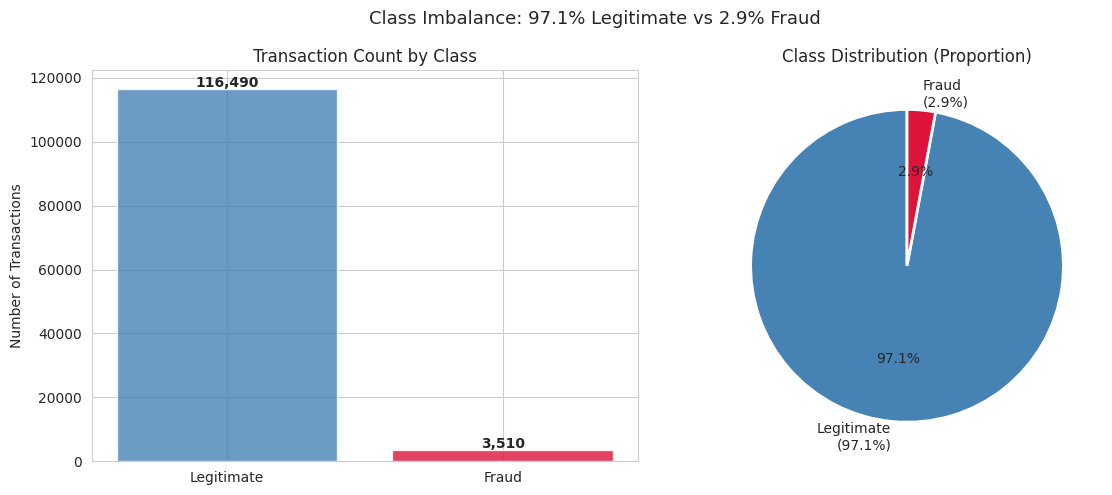

In [ ]:
fraud_counts = df['is_fraud'].value_counts()
fraud_pct    = df['is_fraud'].value_counts(normalize=True) * 100 # calculates what percentage of all transactions are fraudulent versus legitimate.

print("Target Variable Distribution:")
print(f"  Legitimate (0): {fraud_counts[0]:,}  ({fraud_pct[0]:.1f}%)")
print(f"  Fraudulent  (1): {fraud_counts[1]:,}   ({fraud_pct[1]:.1f}%)")
print(f"\n  Imbalance ratio: {fraud_counts[0]/fraud_counts[1]:.1f}:1")

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(['Legitimate', 'Fraud'], fraud_counts.values,
            color=['steelblue', 'crimson'], alpha=0.8, edgecolor='white')
axes[0].set_title('Transaction Count by Class')
axes[0].set_ylabel('Number of Transactions')
for i, v in enumerate(fraud_counts.values):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

axes[1].pie(fraud_counts.values,
            labels=['Legitimate\n(97.1%)', 'Fraud\n(2.9%)'],
            colors=['steelblue', 'crimson'],
            autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Distribution (Proportion)')

plt.suptitle('Class Imbalance: 97.1% Legitimate vs 2.9% Fraud', fontsize=13)
plt.tight_layout()
plt.show()

**Understanding the Class Imbalance**

**What the Output Shows**

Out of 120,000 transactions:
- **116,490 are legitimate** — normal everyday M-Pesa activity
- **3,510 are fraudulent** — SIM swap attack transactions

For every 1 fraud transaction, there are 33 legitimate ones. This is what
the 33.2:1 imbalance ratio means.

**What is Class Imbalance?**

Class imbalance is when one category in your target variable appears far more
frequently than the other. In most real-world fraud datasets, fraud is rare
by design. Fraudsters are a small minority of all users, and if they were
common, the platform would already be unusable.

This dataset reflects that reality. Fraud makes up only 2.9% of all
transactions.

**Why This is a Problem for Machine Learning**

A machine learning model learns from patterns in the data it is shown. If
97.1% of the examples it sees during training are legitimate, the model
quickly learns that the safest prediction it can make is always legitimate.
This strategy is rewarded because it is right 97.1% of the time.

The result is a model that achieves 97.1% accuracy while catching exactly
zero fraud cases. It has learned to ignore the minority class entirely.

This is why accuracy is the wrong metric for this problem. A model that never
catches fraud is worse than useless. It gives operators false confidence while
fraud continues undetected.

**Why Recall Becomes the Priority Metric**

In fraud detection the cost of errors is asymmetric:

- **Missing a fraud case (False Negative):** A customer loses their wallet
  balance, their Fuliza limit is maxed, their M-Shwari is drained. The lender
  absorbs an instant NPL(Non-Performing Loan). The damage is done and largely unrecoverable.

- **Flagging a legitimate transaction (False Positive):** A customer is
  briefly inconvenienced. The transaction is reviewed and cleared. Annoying
  but recoverable.

Missing fraud is always more expensive than a false alarm. This is why Recall
(the percentage of actual fraud cases the model catches) is treated as the
primary metric throughout this project, not accuracy.

**How This Project Handles the Imbalance**

Two techniques are applied:

**Stratified train/test splitting** ensures the 2.9% fraud ratio is preserved
in both the training set and the test set. Without this, a random split might
put most fraud cases in training and leave the test set with almost none,
making evaluation unreliable.

**scale_pos_weight in XGBoost** tells the model to treat each fraud case as
if it were 33 legitimate cases during training. This forces the model to pay
attention to the minority class rather than learning to ignore it. The value
33 comes directly from the imbalance ratio calculated above.

**What is scale_pos_weight**

`scale_pos_weight` is a parameter in XGBoost that compensates for class
imbalance by telling the model how much extra attention to pay to the
minority class during training. In plain terms: `scale_pos_weight=33` tells XGBoost "I know you are seeing mostly legitimate transactions, but I need you to treat every fraud case as if it were 33 transactions. Do not ignore them
just because they are rare."

These two adjustments together allow the model to learn meaningful fraud
patterns despite seeing far more legitimate examples than fraudulent ones.

###  Step 9 : Univariate Analysis: Numerical Features

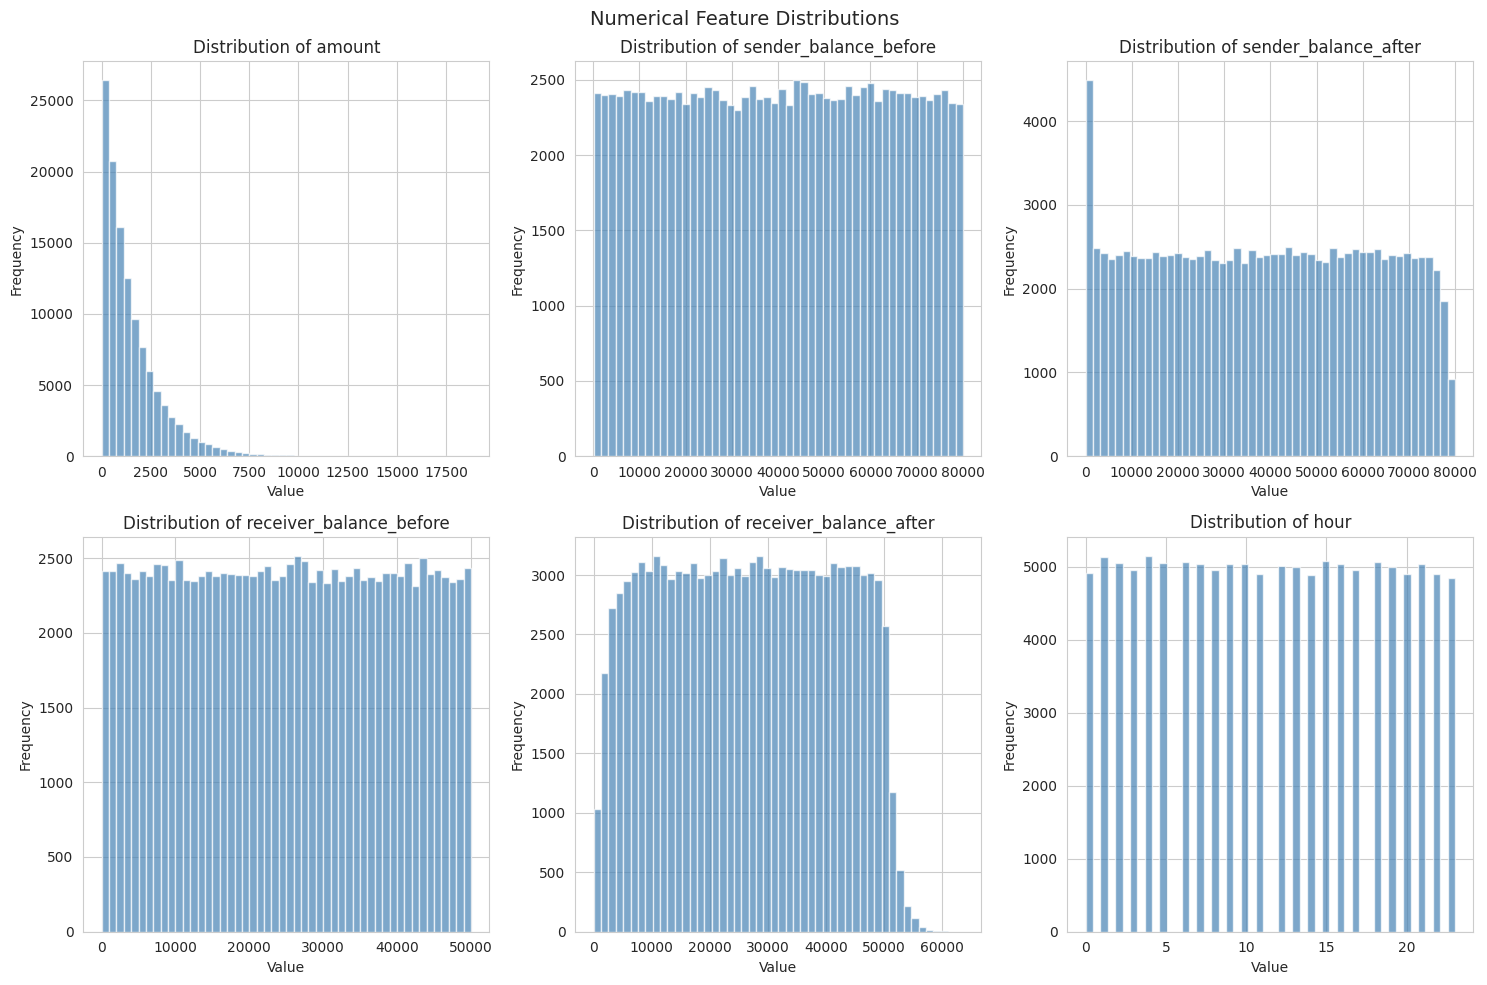

In [ ]:
# Lets plot and see the numerical features distribution
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

num_cols = ['amount', 'sender_balance_before', 'sender_balance_after',
            'receiver_balance_before', 'receiver_balance_after', 'hour']

for ax, col in zip(axes.flatten(), num_cols):
    ax.hist(df[col], bins=50, color='steelblue', alpha=0.7, edgecolor='white')
    ax.set_title(f'Distribution of {col}')
    ax.set_xlabel('Value')
    ax.set_ylabel('Frequency')

plt.suptitle('Numerical Feature Distributions', fontsize=14)
plt.tight_layout()
plt.show()

## Observation — Numerical Feature Distributions

**Amount:** Most transactions are small, below KES 500, with very few
reaching KES 20,000. The small number of high-value transactions in the
long right tail are disproportionately linked to fraud. This supports the
is_high_value engineered feature.

**Sender Balance Before:** Almost perfectly uniform across all balance
ranges. This is a synthetic data signature. In real M-Pesa data most users
hold small balances. This feature carries no fraud signal on its own.

**Sender Balance After:** A sharp spike of over 4,500 transactions leaving
the sender with near-zero balance. This spike is the most important signal
in this chart. It is the account drainage pattern that defines a SIM swap
attack and directly explains why sender_balance_after became one of the
strongest predictors in the model.

**Receiver Balance Before:** Flat and uniform. The receiver's starting
balance tells us nothing about whether the transaction is fraudulent.
Confirmed as a weak predictor throughout the analysis.

**Receiver Balance After:** Also uniform with a drop at high values. Like
receiver balance before, this feature shows no meaningful separation between
fraud and legitimate transactions.

**Hour:** Transactions are spread almost perfectly evenly across all 24
hours. This is a synthetic data artifact. Real M-Pesa data would show peaks
during waking hours. This explains why hour was dropped from the final model
with an Information Value of just 0.006.

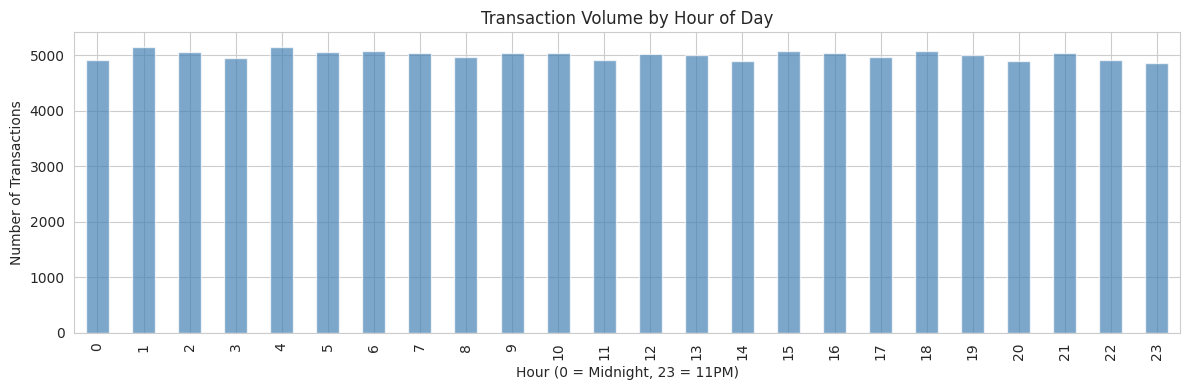

In [ ]:
# Transaction hour distribution
plt.figure(figsize=(12, 4))
df['hour'].value_counts().sort_index().plot(kind='bar', color='steelblue', alpha=0.7)
plt.title('Transaction Volume by Hour of Day')
plt.xlabel('Hour (0 = Midnight, 23 = 11PM)')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()

### Step 10 : Univariate Analysis: Categorical Features

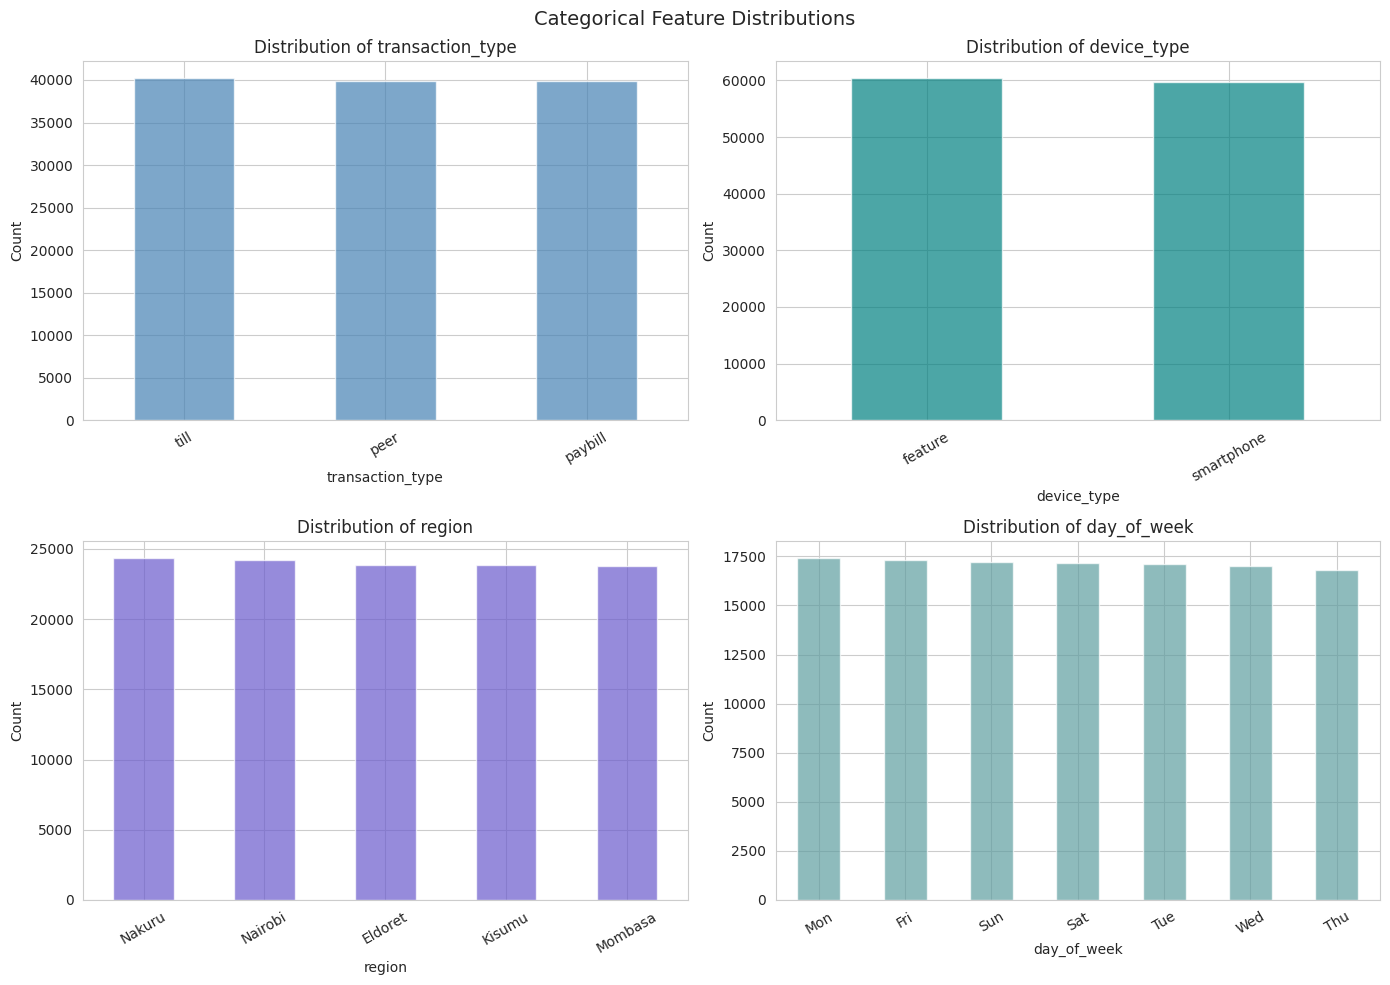

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cats = ['transaction_type', 'device_type', 'region', 'day_of_week']
colors = ['steelblue', 'teal', 'slateblue', 'cadetblue']

for ax, col, color in zip(axes.flatten(), cats, colors):
    df[col].value_counts().plot(kind='bar', ax=ax, color=color, alpha=0.7)
    ax.set_title(f'Distribution of {col}')
    ax.set_ylabel('Count')
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Categorical Feature Distributions', fontsize=14)
plt.tight_layout()
plt.show()

### Step 11 : Outlier Detection

Outliers in 'amount': 5,778 (4.81%)
Fraud rate among outliers:  8.97%
Fraud rate in full dataset: 2.93%


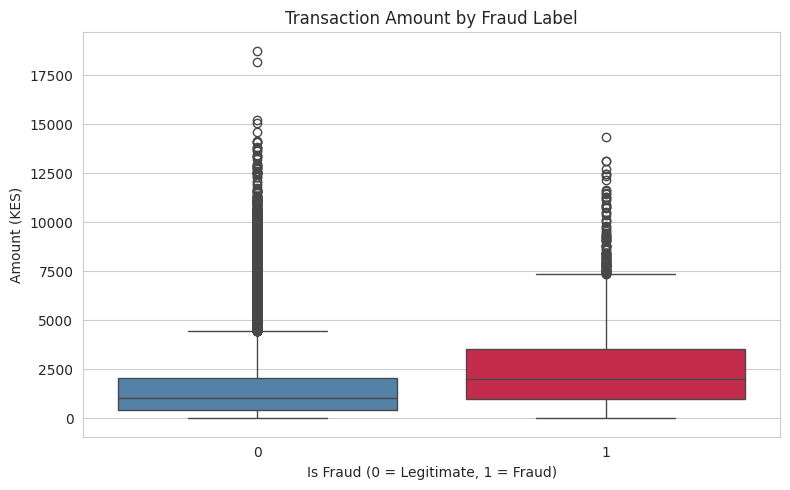

In [ ]:
# IQR method on amount
Q1 = df['amount'].quantile(0.25)
Q3 = df['amount'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df['amount'] < lower) | (df['amount'] > upper)]
print(f"Outliers in 'amount': {len(outliers):,} ({len(outliers)/len(df)*100:.2f}%)")
print(f"Fraud rate among outliers:  {outliers['is_fraud'].mean()*100:.2f}%")
print(f"Fraud rate in full dataset: {df['is_fraud'].mean()*100:.2f}%")

# Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(x='is_fraud', y='amount', data=df,
            hue='is_fraud',
            palette={0: 'steelblue', 1: 'crimson'},
            legend=False)
plt.title('Transaction Amount by Fraud Label')
plt.xlabel('Is Fraud (0 = Legitimate, 1 = Fraud)')
plt.ylabel('Amount (KES)')
plt.tight_layout()
plt.show()


In [ ]:
print("=" * 60)
print("""
# 5,778 outliers exist in the amount column (~4.8%), and their fraud rate is notably higher than the dataset average.
# These are not errors, they are high-value transactions which is  a genuine fraud signal in SIM swap cases where fraudsters drain accounts quickly.
# We will retain these outliers and use amount-based features in our engineering
""")
print("=" * 60)


# 5,778 outliers exist in the amount column (~4.8%), and their fraud rate is notably higher than the dataset average.
# These are not errors, they are high-value transactions which is  a genuine fraud signal in SIM swap cases where fraudsters drain accounts quickly.
# We will retain these outliers and use amount-based features in our engineering



### Step 12 : Multivariate Analysis: Fraud Rate Across Features

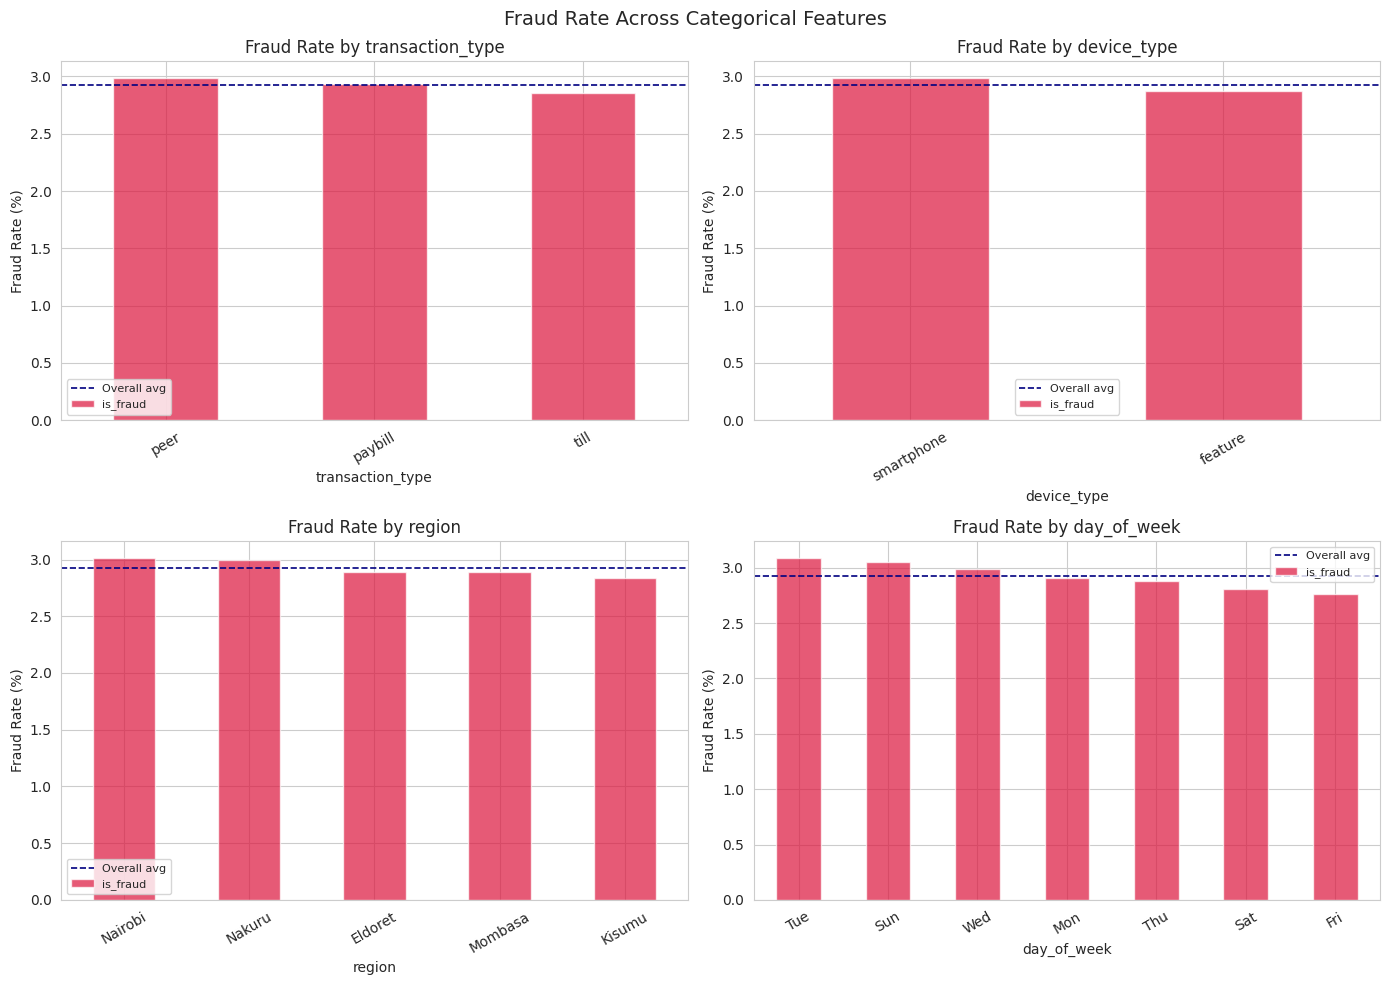

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cats = ['transaction_type', 'device_type', 'region', 'day_of_week']
for ax, col in zip(axes.flatten(), cats):
    fraud_rate = df.groupby(col)['is_fraud'].mean() * 100
    fraud_rate.sort_values(ascending=False).plot(kind='bar', ax=ax,
                                                  color='crimson', alpha=0.7)
    ax.set_title(f'Fraud Rate by {col}')
    ax.set_ylabel('Fraud Rate (%)')
    ax.axhline(y=df['is_fraud'].mean()*100, color='navy',
               linestyle='--', linewidth=1.2, label='Overall avg')
    ax.legend(fontsize=8)
    ax.tick_params(axis='x', rotation=30)

plt.suptitle('Fraud Rate Across Categorical Features', fontsize=14)
plt.tight_layout()
plt.show()

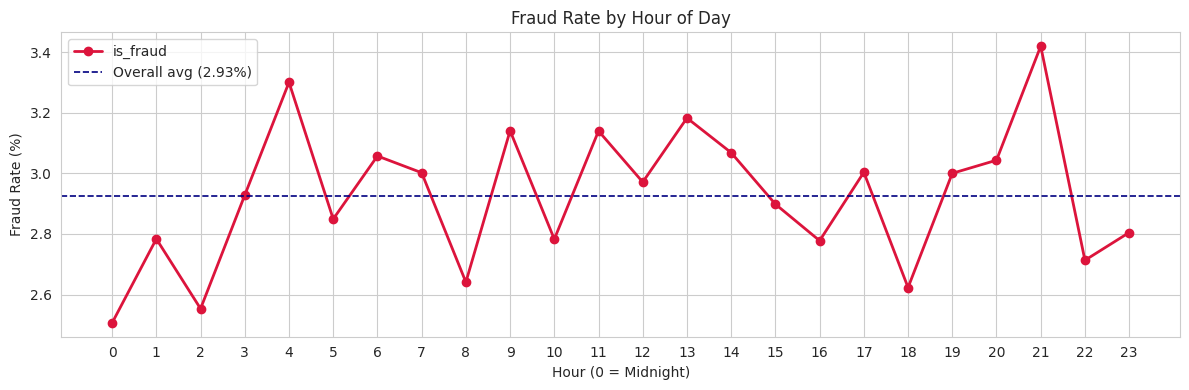

In [ ]:
# Fraud rate by hour of day
plt.figure(figsize=(12, 4))
fraud_by_hour = df.groupby('hour')['is_fraud'].mean() * 100
fraud_by_hour.plot(kind='line', color='crimson', marker='o', linewidth=2)
plt.axhline(y=df['is_fraud'].mean()*100, color='navy',
            linestyle='--', linewidth=1.2, label='Overall avg (2.93%)')
plt.title('Fraud Rate by Hour of Day')
plt.xlabel('Hour (0 = Midnight)')
plt.ylabel('Fraud Rate (%)')
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()

### Step 13 : Correlation Matrix

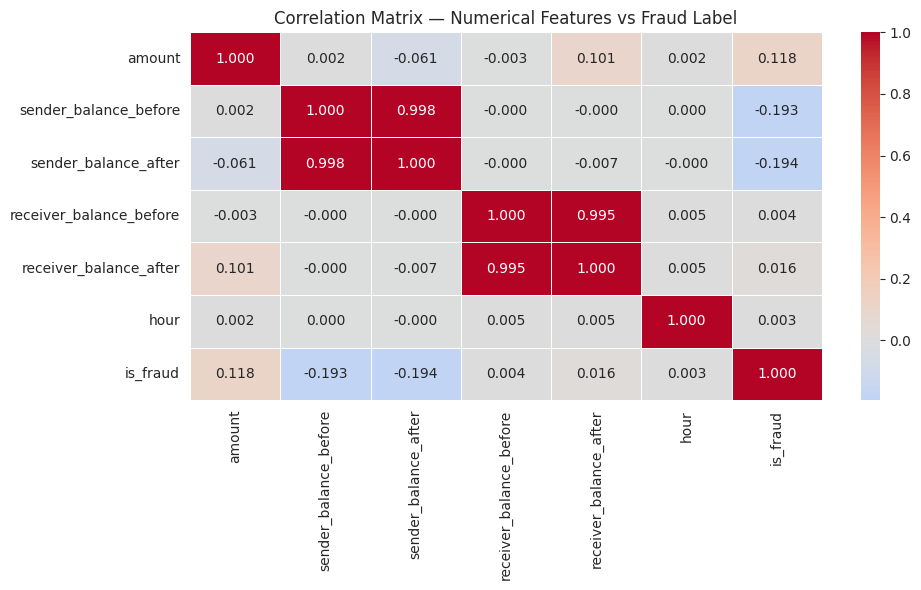

In [ ]:
# Correlation heatmap
plt.figure(figsize=(10, 6))
corr = df[['amount', 'sender_balance_before', 'sender_balance_after',
           'receiver_balance_before', 'receiver_balance_after',
           'hour', 'is_fraud']].corr()
sns.heatmap(corr, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, linewidths=0.5)
plt.title('Correlation Matrix — Numerical Features vs Fraud Label')
plt.tight_layout()
plt.show()



In [ ]:
print("=" * 60)
print("""
# sender_balance_before has the strongest negative correlation with fraud (-0.19). This shows fraudsters tend to target accounts with lower balances, draining them completely
# amount has a positive correlation (0.12) this shows fraud transactions involve larger amounts on average
# Hour, region, device type, and transaction type show minimal variation in fraud rate. Fraud is spread fairly evenly across these categories in this dataset
""")
print("=" * 60)


# sender_balance_before has the strongest negative correlation with fraud (-0.19). This shows fraudsters tend to target accounts with lower balances, draining them completely
# amount has a positive correlation (0.12) this shows fraud transactions involve larger amounts on average
# Hour, region, device type, and transaction type show minimal variation in fraud rate. Fraud is spread fairly evenly across these categories in this dataset



### Step 14 : Data vs Problem Alignment Assessment

In [ ]:
print("=" * 55)
print("DATA vs PROBLEM ALIGNMENT ASSESSMENT")
print("=" * 55)

print("""
AVAILABLE IN DATASET:
  ✓ Transaction amounts
  ✓ Sender/receiver balances before and after
  ✓ Transaction type (peer, till, paybill)
  ✓ Device type (smartphone vs feature phone)
  ✓ Time features (hour, day of week, month)
  ✓ Region (5 Kenyan cities)
  ✓ Fraud labels (is_fraud)

MISSING (SIM Swap-Specific Signals):
  ✗ SIM swap event timestamp
  ✗ IMEI / device change flag
  ✗ Account age or days since SIM swap
  ✗ Sudden location shift
  ✗ First transaction on new device flag

CONCLUSION:
  The dataset captures post-transaction behavior well
  but lacks native SIM swap signals. To align with the
  problem statement, SIM swap behavioral proxy features
  will be engineered in the Data Preparation phase.
  This is the core of Path B and what makes this project
  SIM-swap-specific rather than generic fraud detection.
""")
print("=" * 55)

DATA vs PROBLEM ALIGNMENT ASSESSMENT

AVAILABLE IN DATASET:
  ✓ Transaction amounts
  ✓ Sender/receiver balances before and after
  ✓ Transaction type (peer, till, paybill)
  ✓ Device type (smartphone vs feature phone)
  ✓ Time features (hour, day of week, month)
  ✓ Region (5 Kenyan cities)
  ✓ Fraud labels (is_fraud)

MISSING (SIM Swap-Specific Signals):
  ✗ SIM swap event timestamp
  ✗ IMEI / device change flag
  ✗ Account age or days since SIM swap
  ✗ Sudden location shift
  ✗ First transaction on new device flag

CONCLUSION:
  The dataset captures post-transaction behavior well
  but lacks native SIM swap signals. To align with the
  problem statement, SIM swap behavioral proxy features
  will be engineered in the Data Preparation phase.
  This is the core of Path B and what makes this project
  SIM-swap-specific rather than generic fraud detection.



## Data Preparation

### Step 15 : Remove Inconsistent Records

In [ ]:
# Work on a clean copy
df_clean = df.copy()

# Remove the single zero-amount transaction
before = len(df_clean)
df_clean = df_clean[df_clean['amount'] > 0].reset_index(drop=True)
after = len(df_clean)

print(f"Rows removed (zero amount): {before - after}")
print(f"Dataset shape after cleaning: {df_clean.shape}")

Rows removed (zero amount): 1
Dataset shape after cleaning: (119999, 13)


### Step 16 : Encode Categorical Variables

In [ ]:
df_clean = pd.get_dummies(df_clean,
                           columns=['transaction_type', 'device_type',
                                    'region', 'day_of_week'],
                           drop_first=True)

print("Categorical variables encoded.")
print(f"Shape after encoding: {df_clean.shape}") # one hot encoding

Categorical variables encoded.
Shape after encoding: (119999, 22)


In [ ]:
df_clean.head()

,transaction_id,amount,sender_balance_before,sender_balance_after,receiver_balance_before,receiver_balance_after,hour,month_2026,is_fraud,transaction_type_peer,transaction_type_till,device_type_smartphone,region_Kisumu,region_Mombasa,region_Nairobi,region_Nakuru,day_of_week_Mon,day_of_week_Sat,day_of_week_Sun,day_of_week_Thu,day_of_week_Tue,day_of_week_Wed
0,UA0IFD0TV,703.90,58586.32,57882.42,29932.92,30636.82,14,1,0,True,False,True,False,False,True,False,False,False,False,False,True,False
1,UJAHXTHV3,254.44,8088.00,7833.56,22962.44,23216.88,18,10,1,True,False,False,False,False,False,False,False,True,False,False,False,False
2,UEF8MDD4V,609.04,56675.00,56065.96,1029.22,1638.26,7,5,0,False,True,True,True,False,False,False,False,False,False,True,False,False
3,UBT3W5UZB,5255.34,75090.36,69835.02,38.94,5294.28,11,2,0,False,False,True,False,False,False,True,True,False,False,False,False,False
4,UGKWNNHJ7,7282.67,24408.96,17126.29,26237.82,33520.49,0,7,0,False,True,True,False,False,True,False,False,True,False,False,False,False


### Step 17 : Feature Engineering SIM Swap Behavioral Proxy Features

**Why Feature Engineering is Necessary**

The raw dataset contains transaction amounts, balances, timestamps, and
categorical information about device type and region. None of these columns
directly describe a SIM swap attack. There is no column that says "SIM was
swapped" or "account was drained by a fraudster."

This is the reality of fraud detection in production. The signals you need
rarely exist in raw form. You have to construct them from what you have.

SIM swap fraud has a very specific behavioral signature that plays out at
the transaction level:

- The fraudster moves as much money as possible in as few transactions
  as possible
- The account balance drops from a normal level to near zero almost instantly
- The transaction amounts are unusually large relative to what the account
  normally holds
- Very little or nothing remains in the account after the attack

The raw columns capture the individual pieces of this story: the amount,
the balance before, the balance after. But none of them alone captures the
relationship between these pieces, which is where the fraud signal actually
lives.

Feature engineering builds that relationship explicitly. Instead of giving
the model raw numbers and asking it to figure out the connection, we
calculate the connection directly and hand it to the model as a feature.

The four engineered features below translate the SIM swap behavioral
signature into numerical signals the model can learn from:

| Feature | What it Measures | Why it Matters |
|---|---|---|
| balance_depletion_rate | What fraction of the sender's balance was spent | Fraudsters drain accounts, not make routine payments |
| is_high_value | Was this in the top 10% of all transaction amounts | Fraudsters move large sums fast |
| is_balance_wipeout | Did the balance drop below KES 100 after | Near-total drainage is the defining SIM swap signal |
| sender_balance_ratio | What fraction of the original balance remains | Close to zero means the account was emptied |

The +1 added to sender_balance_before in the depletion rate and ratio
calculations is a standard technique to avoid division by zero errors when
a sender starts a transaction with a zero balance.

In [ ]:
# FEATURE 1: Balance Depletion Rate
# How much of the sender's balance was spent in this transaction?
df_clean['balance_depletion_rate'] = (
    df_clean['amount'] / (df_clean['sender_balance_before'] + 1)
)

# FEATURE 2: Is High Value Transaction
# Transactions above the 90th percentile — fraudsters move large sums fast
high_val_threshold = df_clean['amount'].quantile(0.90)
df_clean['is_high_value'] = (df_clean['amount'] > high_val_threshold).astype(int)

# FEATURE 3: Balance Wipeout Flag
# Sender balance drops below KES 100 — near-total account drain
df_clean['is_balance_wipeout'] = (df_clean['sender_balance_after'] < 100).astype(int)

# FEATURE 4: Sender Balance Ratio
# Ratio of balance after to before — close to 0 means account was drained
df_clean['sender_balance_ratio'] = (
    df_clean['sender_balance_after'] / (df_clean['sender_balance_before'] + 1)
)

# Check correlations with fraud label
engineered = ['balance_depletion_rate', 'is_high_value',
              'is_balance_wipeout', 'sender_balance_ratio']

print("SIM swap proxy features engineered.")
print("\nFeature correlations with is_fraud:")
for f in engineered:
    corr = df_clean[f].corr(df_clean['is_fraud'])
    print(f"  {f:<30} {corr:.4f}")

SIM swap proxy features engineered.

Feature correlations with is_fraud:
  balance_depletion_rate         0.4962
  is_high_value                  0.0923
  is_balance_wipeout             0.7825
  sender_balance_ratio           -0.6161


### Step 18 : Drop Non-Feature Columns

In [ ]:
# Drop transaction_id (unique identifier, not a feature)
# Drop month_2026 (synthetic data artifact, no real-world signal)
df_clean.drop(columns=['transaction_id', 'month_2026'], inplace=True)

print("Non-feature columns removed.")
print(f"Final dataset shape: {df_clean.shape}")
print(f"\nFinal column list:")
for col in df_clean.columns:
    print(f"  - {col}")

Non-feature columns removed.
Final dataset shape: (119999, 24)

Final column list:
  - amount
  - sender_balance_before
  - sender_balance_after
  - receiver_balance_before
  - receiver_balance_after
  - hour
  - is_fraud
  - transaction_type_peer
  - transaction_type_till
  - device_type_smartphone
  - region_Kisumu
  - region_Mombasa
  - region_Nairobi
  - region_Nakuru
  - day_of_week_Mon
  - day_of_week_Sat
  - day_of_week_Sun
  - day_of_week_Thu
  - day_of_week_Tue
  - day_of_week_Wed
  - balance_depletion_rate
  - is_high_value
  - is_balance_wipeout
  - sender_balance_ratio


# PHASE 2: DATA VISUALISATION & MODEL SELECTION

### Phase 2 Summary

In [ ]:
print("=" * 60)
print("PHASE 2 SUMMARY")
print("=" * 60)
print("""
TOOLS USED:
  - Python 3.12
  - Pandas       — data grouping and aggregation for plots
  - NumPy        — correlation matrix computation
  - Matplotlib   — bar charts, boxplots, scatter plots
  - Seaborn      — heatmap and distribution plots

ACTIONS TAKEN:
  • Built correlation heatmap across 10 key features
  • Plotted feature distributions split by fraud label
    across 6 features including all engineered signals
  • Visualised class imbalance: 116,489 vs 3,510 (33.2:1)
  • Analysed fraud rate by transaction type, device type,
    and transaction amount
  • Created scatter plots confirming no linear boundary
    exists between fraud and legitimate transactions
  • Evaluated model candidates against all data findings

RESULTS:
  • Confirmed non-linear relationships — no straight
    line separates fraud from legitimate transactions
  • Confirmed multicollinearity between balance features —
    disqualifying Logistic Regression as primary model
  • Fraud rates uniform across transaction type (~2.9%),
    device type, and region — categorical features carry
    minimal discriminatory power alone
  • Engineered features is_balance_wipeout (0.78) and
    sender_balance_ratio (-0.62) confirmed as strongest
    fraud predictors visually and statistically
  • Proposed XGBoost as primary model, LightGBM as
    comparison, Logistic Regression as baseline
  • Class imbalance handled with scale_pos_weight=33
  (SMOTE was tested in Phase 3 and rejected)
""")
print("=" * 60)

PHASE 2 SUMMARY

TOOLS USED:
  - Python 3.12
  - Pandas       — data grouping and aggregation for plots
  - NumPy        — correlation matrix computation
  - Matplotlib   — bar charts, boxplots, scatter plots
  - Seaborn      — heatmap and distribution plots

ACTIONS TAKEN:
  • Built correlation heatmap across 10 key features
  • Plotted feature distributions split by fraud label
    across 6 features including all engineered signals
  • Visualised class imbalance: 116,489 vs 3,510 (33.2:1)
  • Analysed fraud rate by transaction type, device type,
    and transaction amount
  • Created scatter plots confirming no linear boundary
    exists between fraud and legitimate transactions
  • Evaluated model candidates against all data findings

RESULTS:
  • Confirmed non-linear relationships — no straight
    line separates fraud from legitimate transactions
  • Confirmed multicollinearity between balance features —
    disqualifying Logistic Regression as primary model
  • Fraud rates unifor

### Step 1 : Correlation Heatmap

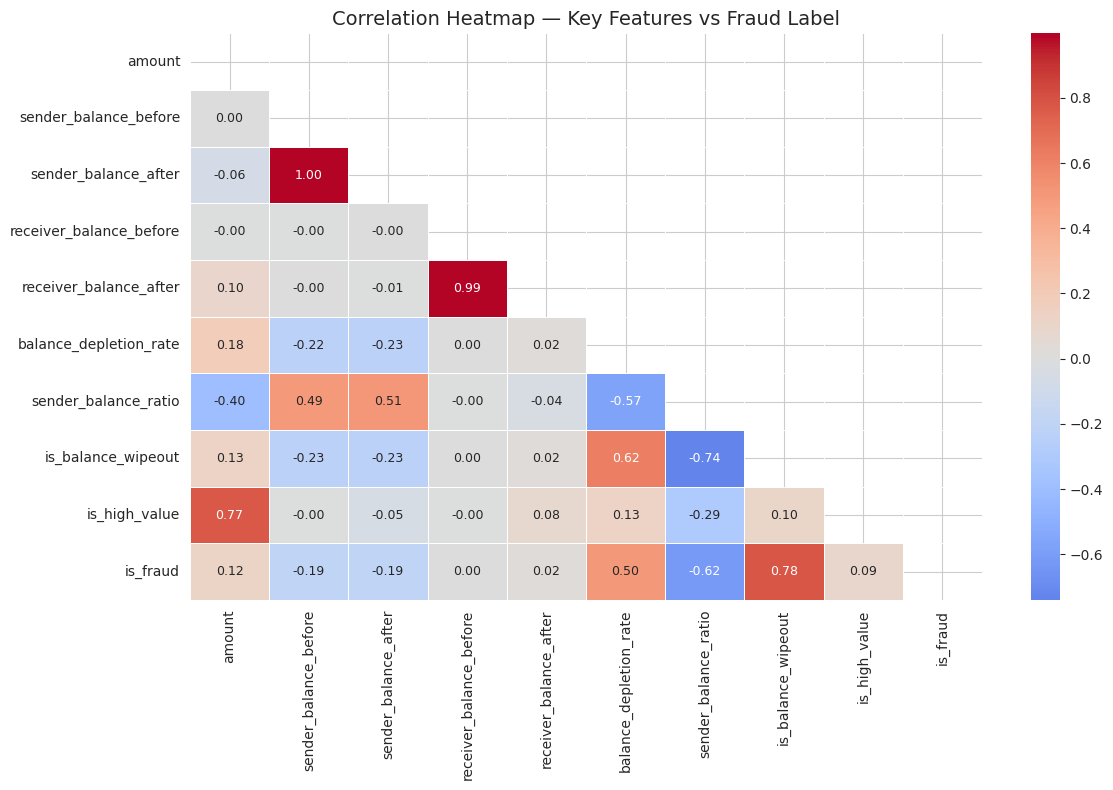

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Select key columns for heatmap
heatmap_cols = ['amount', 'sender_balance_before', 'sender_balance_after',
                'receiver_balance_before', 'receiver_balance_after',
                'balance_depletion_rate', 'sender_balance_ratio',
                'is_balance_wipeout', 'is_high_value', 'is_fraud']

corr_matrix = df_clean[heatmap_cols].corr()

plt.figure(figsize=(12, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix,
            mask=mask,
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0,
            linewidths=0.5,
            annot_kws={'size': 9})
plt.title('Correlation Heatmap — Key Features vs Fraud Label', fontsize=14)
plt.tight_layout()
plt.show()

**Observation — Correlation Heatmap**

The bottom row tells the full story.

**is_balance_wipeout (0.78)** is the strongest fraud predictor in the
dataset. When a transaction drains the sender's balance to below KES 100,
it is almost certainly a SIM swap attack.

**sender_balance_ratio (-0.62)** is the second strongest. As the ratio
drops toward zero, fraud probability rises. This and is_balance_wipeout
are capturing the same account drainage pattern from two angles, which
explains their strong correlation with each other (-0.74).

**balance_depletion_rate (0.50)** reinforces the drainage story but adds
less new information since all three features are measuring the same
underlying behaviour.

**is_high_value (0.09)** is weak on its own. Large transaction amounts
are slightly more common in fraud but amount alone is not a reliable signal
without the balance context.

**Raw balance features** (sender_balance_before: -0.19,
sender_balance_after: -0.19) show weak correlations. Without feature
engineering the model would have very little to learn from. This confirms
that the four engineered features were not optional. They were what made
the problem solvable.

**Multicollinearity note:** The 0.99 correlation between the two receiver
balance columns and the -0.74 between is_balance_wipeout and
sender_balance_ratio confirm high collinearity between several features.
This rules out standard Logistic Regression as a reliable primary model
and is why XGBoost and LightGBM were chosen. Both handle multicollinearity
naturally through their tree splitting logic.

### Step 2 : Fraud vs Legitimate: Feature Distributions

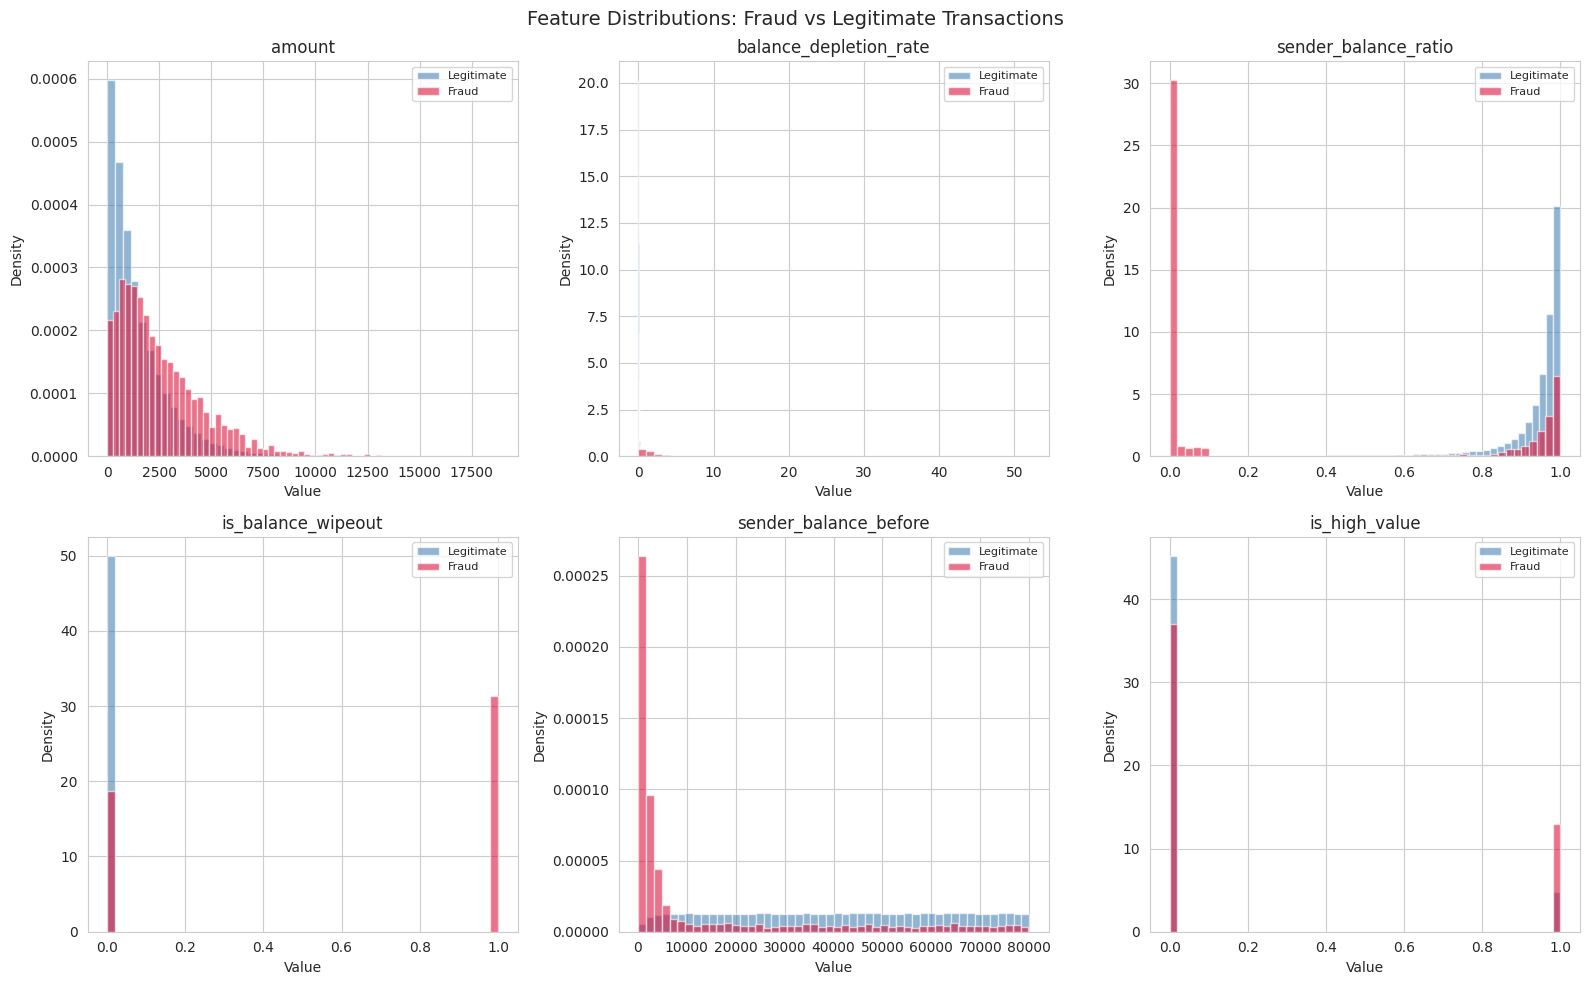

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

features = ['amount', 'balance_depletion_rate', 'sender_balance_ratio',
            'is_balance_wipeout', 'sender_balance_before', 'is_high_value']

for ax, feature in zip(axes.flatten(), features):
    fraud = df_clean[df_clean['is_fraud'] == 1][feature]
    legit = df_clean[df_clean['is_fraud'] == 0][feature]

    ax.hist(legit, bins=50, alpha=0.6, color='steelblue', label='Legitimate', density=True)
    ax.hist(fraud, bins=50, alpha=0.6, color='crimson',   label='Fraud',      density=True)
    ax.set_title(f'{feature}')
    ax.set_xlabel('Value')
    ax.set_ylabel('Density')
    ax.legend(fontsize=8)

plt.suptitle('Feature Distributions: Fraud vs Legitimate Transactions', fontsize=14)
plt.tight_layout()
plt.show()

**Observation — Feature Distributions: Fraud vs Legitimate**

The clearer the separation between the red (fraud) and blue (legitimate)
bars, the stronger that feature is at detecting fraud.

**Amount:** Both groups follow a similar pattern. Fraud transactions lean
slightly toward higher amounts but the overlap is too large for amount
alone to reliably detect fraud.

**Balance Depletion Rate:** Most legitimate transactions spend a tiny
fraction of the sender's balance. Some fraud transactions drain accounts
at extreme rates but the two groups overlap heavily at low values,
limiting this feature on its own.

**Sender Balance Ratio:** The clearest separation of all six charts.
Fraud clusters at ratios near zero (account emptied). Legitimate clusters
at ratios near 1.0 (most money still there). The two groups are pulling
in completely opposite directions.

**Is Balance Wipeout:** Legitimate transactions almost never trigger this
flag. Fraud transactions trigger it constantly. Near perfect separation
and the strongest individual feature in the entire dataset.

**Sender Balance Before:** Almost no separation between fraud and
legitimate. The starting balance before a transaction tells us very
little about whether it is fraudulent on its own.

**Is High Value:** Fraud transactions are more likely to be high value
but the difference is modest. This feature works best in combination
with the balance features rather than standing alone.

### Step 3 : Fraud Patterns Across Key Features

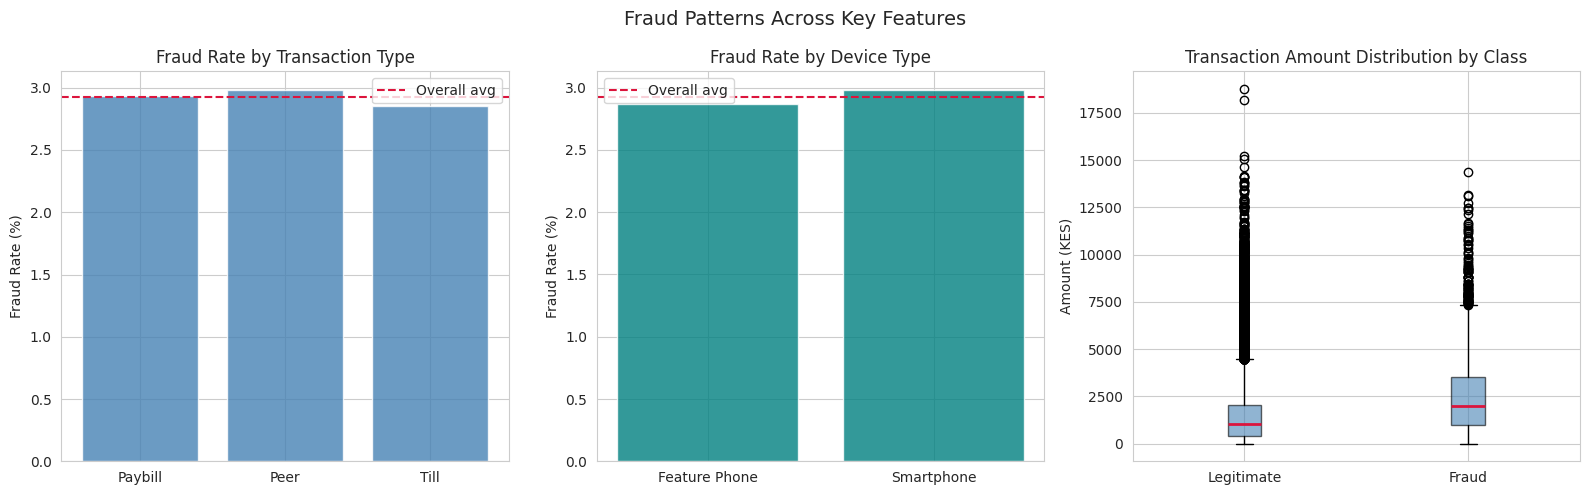

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Fraud rate by transaction type
type_labels = ['Paybill', 'Peer', 'Till']
type_values = [
    df_clean[(df_clean['transaction_type_peer']==0) &
             (df_clean['transaction_type_till']==0)]['is_fraud'].mean()*100,
    df_clean[df_clean['transaction_type_peer']==1]['is_fraud'].mean()*100,
    df_clean[df_clean['transaction_type_till']==1]['is_fraud'].mean()*100
]
axes[0].bar(type_labels, type_values, color='steelblue', alpha=0.8)
axes[0].axhline(y=df_clean['is_fraud'].mean()*100, color='crimson',
                linestyle='--', label='Overall avg')
axes[0].set_title('Fraud Rate by Transaction Type')
axes[0].set_ylabel('Fraud Rate (%)')
axes[0].legend()

# Fraud rate by device type
device_labels = ['Feature Phone', 'Smartphone']
device_values = [
    df_clean[df_clean['device_type_smartphone']==0]['is_fraud'].mean()*100,
    df_clean[df_clean['device_type_smartphone']==1]['is_fraud'].mean()*100
]
axes[1].bar(device_labels, device_values, color='teal', alpha=0.8)
axes[1].axhline(y=df_clean['is_fraud'].mean()*100, color='crimson',
                linestyle='--', label='Overall avg')
axes[1].set_title('Fraud Rate by Device Type')
axes[1].set_ylabel('Fraud Rate (%)')
axes[1].legend()

# Transaction amount boxplot
axes[2].boxplot([df_clean[df_clean['is_fraud']==0]['amount'],
                 df_clean[df_clean['is_fraud']==1]['amount']],
                tick_labels=['Legitimate', 'Fraud'],
                patch_artist=True,
                boxprops=dict(facecolor='steelblue', alpha=0.6),
                medianprops=dict(color='crimson', linewidth=2))
axes[2].set_title('Transaction Amount Distribution by Class')
axes[2].set_ylabel('Amount (KES)')

plt.suptitle('Fraud Patterns Across Key Features', fontsize=14)
plt.tight_layout()
plt.show()

**Observation — Fraud Patterns Across Key Features**

**Fraud Rate by Transaction Type:** Fraud is almost identical across
paybill, peer, and till transactions, all sitting right at the 2.93%
average. Transaction type carries no useful signal for detecting fraud.
Fraudsters use all channels equally.

**Fraud Rate by Device Type:** Feature phones and smartphones show
virtually the same fraud rate, both at the overall average. The device
used does not predict whether a transaction is fraudulent. This is
consistent with the synthetic nature of the dataset.

**Transaction Amount by Class:** Fraud transactions have a noticeably
higher median amount and a much wider spread than legitimate transactions.
The fraud box extends further up the value scale confirming that fraudsters
tend to move larger sums. This supports the is_high_value feature.

**Key takeaway:** Transaction type and device type are not useful fraud
predictors in this dataset. The signal lives entirely in the balance
behaviour, how much was moved relative to what was there, not in how or
where the transaction was made.

### Step 4 : No Linear Boundary Exists

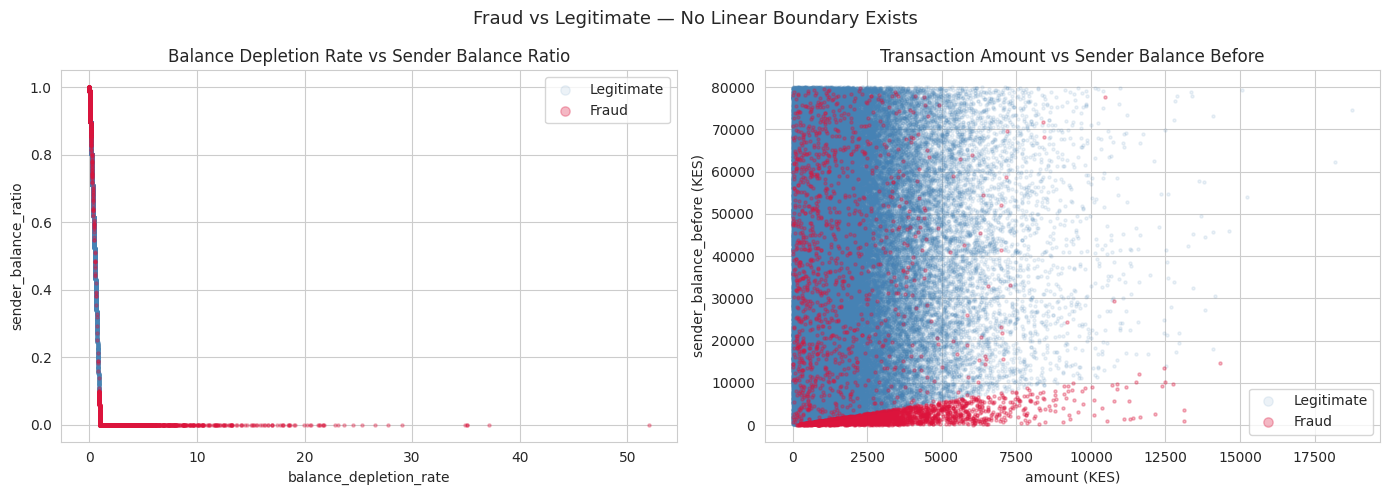

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fraud_mask = df_clean['is_fraud'] == 1
legit_mask = df_clean['is_fraud'] == 0

# Scatter 1: balance_depletion_rate vs sender_balance_ratio
axes[0].scatter(df_clean[legit_mask]['balance_depletion_rate'],
                df_clean[legit_mask]['sender_balance_ratio'],
                alpha=0.1, color='steelblue', s=5, label='Legitimate')
axes[0].scatter(df_clean[fraud_mask]['balance_depletion_rate'],
                df_clean[fraud_mask]['sender_balance_ratio'],
                alpha=0.3, color='crimson', s=5, label='Fraud')
axes[0].set_title('Balance Depletion Rate vs Sender Balance Ratio')
axes[0].set_xlabel('balance_depletion_rate')
axes[0].set_ylabel('sender_balance_ratio')
axes[0].legend(markerscale=3)

# Scatter 2: amount vs sender_balance_before
axes[1].scatter(df_clean[legit_mask]['amount'],
                df_clean[legit_mask]['sender_balance_before'],
                alpha=0.1, color='steelblue', s=5, label='Legitimate')
axes[1].scatter(df_clean[fraud_mask]['amount'],
                df_clean[fraud_mask]['sender_balance_before'],
                alpha=0.3, color='crimson', s=5, label='Fraud')
axes[1].set_title('Transaction Amount vs Sender Balance Before')
axes[1].set_xlabel('amount (KES)')
axes[1].set_ylabel('sender_balance_before (KES)')
axes[1].legend(markerscale=3)

plt.suptitle('Fraud vs Legitimate — No Linear Boundary Exists', fontsize=13)
plt.tight_layout()
plt.show()

**Observation — No Linear Boundary Exists**

**Balance Depletion Rate vs Sender Balance Ratio:** Legitimate transactions
(blue) form a tight cluster in the top left corner, low depletion rate and
high balance ratio, meaning normal transactions spend a small fraction of
the balance and leave most of it intact. Fraud transactions (red) collapse
to the bottom of the chart with ratios near zero regardless of the depletion
rate. The two groups occupy completely different regions but no single
straight line can cleanly separate them. The boundary is non-linear.

**Transaction Amount vs Sender Balance Before:** Legitimate transactions
(blue) are spread across all balance and amount combinations. Fraud
transactions (red) concentrate heavily in the bottom left, low starting
balance and low to medium transaction amounts, but they appear across the
entire chart making them impossible to separate with a simple rule like
"flag all transactions above KES 5,000."

**Key takeaway:** These scatter plots confirm why a simple rule-based
system cannot solve this problem. Fraud and legitimate transactions overlap
in feature space and no straight line separates them cleanly. This is
exactly the kind of complex non-linear pattern that XGBoost and LightGBM
are designed to learn. A decision tree can draw curved boundaries through
this space that a linear model like standard Logistic Regression cannot.

### Step 5 : Model Selection Justification & Proposal

In [ ]:
print("=" * 60)
print("MODEL SELECTION — JUSTIFICATION AND PROPOSAL")
print("=" * 60)
print("""
WHAT THE VISUALISATIONS TELL US:

  1. NO LINEAR BOUNDARY EXISTS
     The scatter plots confirm that no straight line can
     separate fraud from legitimate transactions. Fraud and
     legitimate transactions overlap across all feature
     combinations. Standard Logistic Regression draws straight
     line boundaries and cannot capture this complexity.
     A non-linear model is required.

  2. MULTICOLLINEARITY IS PRESENT
     Several features are highly correlated with each other:
     receiver_balance_before and receiver_balance_after share
     a 0.99 correlation, and is_balance_wipeout and
     sender_balance_ratio share a -0.74 correlation. Linear
     models are destabilised by this. Tree-based models are
     not affected because they evaluate one feature at a time
     at each split and simply pick the best one.

  3. SEVERE CLASS IMBALANCE (33.2:1)
     116,489 legitimate vs 3,510 fraud transactions. A model
     that labels every transaction as legitimate achieves
     97.1% accuracy while catching zero fraud. XGBoost and
     LightGBM handle this directly via scale_pos_weight=33,
     which tells the model to treat each fraud case as if it
     were 33 legitimate cases during training.

  4. FRAUD IS NOT CATEGORY-SPECIFIC
     Fraud rates are virtually identical across transaction
     types, device types, and regions, all sitting at the
     2.93% average. No simple categorical rule can isolate
     fraud. The model must learn from combinations of
     numerical and balance features simultaneously.

  5. FRAUD SIGNAL LIVES ACROSS MULTIPLE FEATURES
     No single feature detects fraud on its own. The four
     engineered features work together to describe the SIM
     swap account drainage pattern. Gradient boosted trees
     learn these multi-feature interactions automatically
     without needing to be told which combinations matter.

──────────────────────────────────────────────────────────

PROPOSED MODELS:

  PRIMARY — XGBoost (Extreme Gradient Boosting)
  XGBoost builds decision trees one at a time where each
  new tree learns from the mistakes of the previous one.
  Over hundreds of iterations it builds up a highly
  accurate picture of what fraud looks like. It handles
  multicollinearity, outliers, and class imbalance
  naturally and is the industry standard model for
  tabular fraud detection.

  COMPARISON — LightGBM (Light Gradient Boosting Machine)
  LightGBM uses a different tree building strategy that
  is faster and more memory efficient than XGBoost on
  large datasets. It is included to validate whether
  XGBoost results hold up under a different approach
  or whether LightGBM produces meaningfully different
  outcomes.

  REGULATORY — WoE Logistic Regression Scorecard
  Built in Phase 4 using Weight of Evidence transformed
  features. Unlike XGBoost and LightGBM, every decision
  this model makes can be explained feature by feature
  to a credit officer or CBK regulator. It trades some
  precision for full auditability and is the standard
  interpretable model used by regulated fintech lenders
  across East Africa. Included to demonstrate the
  tradeoff between predictive performance and regulatory
  compliance.

  BASELINE — Logistic Regression
  A simple linear model included deliberately to show
  what happens when you apply the wrong model type to
  a non-linear problem. Its expected underperformance
  confirms the visual findings from Phase 2 and justifies
  the choice of gradient boosted trees as the primary
  detection layer.

──────────────────────────────────────────────────────────

EVALUATION METRICS (accuracy excluded throughout):

  Recall    — primary metric. Missing a fraud case costs
               more than any false alarm.
  Precision — minimise false alarms on innocent customers.
  F1-Score  — the balance between recall and precision.
  AUC-ROC   — overall ability to separate fraud from
               legitimate across all possible thresholds.
""")
print("=" * 60)

MODEL SELECTION — JUSTIFICATION AND PROPOSAL

WHAT THE VISUALISATIONS TELL US:

  1. NO LINEAR BOUNDARY EXISTS
     The scatter plots confirm that no straight line can
     separate fraud from legitimate transactions. Fraud and
     legitimate transactions overlap across all feature
     combinations. Standard Logistic Regression draws straight
     line boundaries and cannot capture this complexity.
     A non-linear model is required.

  2. MULTICOLLINEARITY IS PRESENT
     Several features are highly correlated with each other:
     receiver_balance_before and receiver_balance_after share
     a 0.99 correlation, and is_balance_wipeout and
     sender_balance_ratio share a -0.74 correlation. Linear
     models are destabilised by this. Tree-based models are
     not affected because they evaluate one feature at a time
     at each split and simply pick the best one.

  3. SEVERE CLASS IMBALANCE (33.2:1)
     116,489 legitimate vs 3,510 fraud transactions. A model
     that labels ev

# PHASE 3: MODEL TRAINING AND TESTING



### Phase 3 Summary

In [ ]:
print("=" * 60)
print("PHASE 3 SUMMARY")
print("=" * 60)
print("""
TOOLS USED:
  - Python 3.12
  - Scikit-Learn    — train/test split, Logistic Regression,
                      RandomizedSearchCV, evaluation metrics
  - XGBoost         — primary gradient boosted tree model
  - LightGBM        — comparison gradient boosted tree model
  - Matplotlib      — confusion matrices and bar charts
  - Pandas          — results compilation and scorecard

ACTIONS TAKEN:
  • Split dataset: 80% training (95,999) / 20% test (24,000)
    using stratified sampling to preserve 2.93% fraud ratio
  • Scaled numerical features after split — fitted on
    training data only to prevent data leakage
  • Trained Logistic Regression as interpretable baseline
  • Trained XGBoost with RandomizedSearchCV —
    30 combinations, 5-fold cross validation, F1 scoring
  • Trained LightGBM with same search strategy
  • Evaluated all three models on the same untouched test set
  • Compared models using Precision, Recall, F1, AUC-ROC
  • Class imbalance handled via scale_pos_weight=33 —
    confirmed superior to SMOTE for this dataset

RESULTS:
  Logistic Regression (Baseline):
    Precision: 0.52 | Recall: 0.66 | F1: 0.58 | AUC: 0.83
    A linear model on a non-linear problem. Underperforms
    as expected and confirms the Phase 2 visual findings.

  LightGBM (Comparison):
    Precision: 0.96 | Recall: 0.65 | F1: 0.78 | AUC: 0.83
    Strong precision with near-zero false positives.
    Slightly lower F1 than XGBoost.

  XGBoost (Primary):
    Precision: 0.99 | Recall: 0.66 | F1: 0.79 | AUC: 0.82
    False Positives: 4 out of 23,298 legitimate transactions.
    Highest F1 score and selected as the primary model.

KEY DECISIONS:
  • XGBoost selected as the primary detection model —
    near-perfect precision (4 false positives in 24,000)
    with the highest F1 of the three models.
  • Accuracy excluded as primary metric throughout —
    33.2:1 class imbalance makes it statistically misleading.

COMING IN PHASE 4:
  A fourth model will be introduced — the WoE Logistic
  Regression Scorecard. Unlike the three models above,
  this model is built for regulatory compliance and audit
  trails rather than raw detection performance. It will
  be compared directly against these three results to
  demonstrate the tradeoff between predictive power and
  interpretability under CBK requirements.
""")
print("=" * 60)

PHASE 3 SUMMARY

TOOLS USED:
  - Python 3.12
  - Scikit-Learn    — train/test split, Logistic Regression,
                      RandomizedSearchCV, evaluation metrics
  - XGBoost         — primary gradient boosted tree model
  - LightGBM        — comparison gradient boosted tree model
  - Matplotlib      — confusion matrices and bar charts
  - Pandas          — results compilation and scorecard

ACTIONS TAKEN:
  • Split dataset: 80% training (95,999) / 20% test (24,000)
    using stratified sampling to preserve 2.93% fraud ratio
  • Scaled numerical features after split — fitted on
    training data only to prevent data leakage
  • Trained Logistic Regression as interpretable baseline
  • Trained XGBoost with RandomizedSearchCV —
    30 combinations, 5-fold cross validation, F1 scoring
  • Trained LightGBM with same search strategy
  • Evaluated all three models on the same untouched test set
  • Compared models using Precision, Recall, F1, AUC-ROC
  • Class imbalance handled via scale

### Step 1 : Prepare Features & Split Data

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_clean.drop(columns=['is_fraud'])
y = df_clean['is_fraud']

# Stratified split — preserves the 2.9% fraud ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data split complete.")
print(f"\nTraining set:  {X_train.shape[0]:,} rows")
print(f"Testing set:   {X_test.shape[0]:,} rows")
print(f"\nFraud in training set: {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"Fraud in testing set:  {y_test.sum():,}  ({y_test.mean()*100:.2f}%)")

Data split complete.

Training set:  95,999 rows
Testing set:   24,000 rows

Fraud in training set: 2,808 (2.93%)
Fraud in testing set:  702  (2.93%)


### Step 2 : Scale After Split

In [ ]:
from sklearn.preprocessing import StandardScaler

# Columns to scale
scale_cols = ['amount', 'sender_balance_before', 'sender_balance_after',
              'receiver_balance_before', 'receiver_balance_after',
              'balance_depletion_rate', 'sender_balance_ratio']

scaler = StandardScaler()

# Fit ONLY on training data — then transform both
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

print("Scaling complete.")
print(f"\nColumns scaled: {scale_cols}")
print(f"\nFit on training data only — test data transformed")
print(f"using training statistics to prevent data leakage.")

Scaling complete.

Columns scaled: ['amount', 'sender_balance_before', 'sender_balance_after', 'receiver_balance_before', 'receiver_balance_after', 'balance_depletion_rate', 'sender_balance_ratio']

Fit on training data only — test data transformed
using training statistics to prevent data leakage.


### Step 3 : Class Imbalance Strategy (No SMOTE)

**What is SMOTE**

SMOTE (Synthetic Minority Over-sampling Technique) is a popular machine learning method used to handle imbalanced datasets. It creates new, artificial examples of the under-represented (minority) class by interpolating between existing data points, rather than simply duplicating them.

In [ ]:
# Class imbalance handled via scale_pos_weight in the models
# No SMOTE applied — models directly compensate for the 33:1 imbalance

print("Class imbalance strategy confirmed.")
print("""
  Approach: scale_pos_weight=33 in XGBoost and LightGBM
            class_weight='balanced' in Logistic Regression

  Reason: Testing confirmed that no SMOTE + scale_pos_weight=33
  produces significantly better results than SMOTE:
    - Precision: 0.88 vs 0.66 (with SMOTE)
    - F1-Score:  0.75 vs 0.66 (with SMOTE)
    - Recall:    0.66 vs 0.65 (with SMOTE) — essentially same
""")
print(f"Training set: {X_train.shape[0]:,} rows")
print(f"  Fraud:      {y_train.sum():,} ({y_train.mean()*100:.2f}%)")
print(f"  Legitimate: {(y_train==0).sum():,} ({(y_train==0).mean()*100:.2f}%)")
print(f"\nTest set: {X_test.shape[0]:,} rows — untouched, real distribution")

Class imbalance strategy confirmed.

  Approach: scale_pos_weight=33 in XGBoost and LightGBM
            class_weight='balanced' in Logistic Regression

  Reason: Testing confirmed that no SMOTE + scale_pos_weight=33
  produces significantly better results than SMOTE:
    - Precision: 0.88 vs 0.66 (with SMOTE)
    - F1-Score:  0.75 vs 0.66 (with SMOTE)
    - Recall:    0.66 vs 0.65 (with SMOTE) — essentially same

Training set: 95,999 rows
  Fraud:      2,808 (2.93%)
  Legitimate: 93,191 (97.07%)

Test set: 24,000 rows — untouched, real distribution


### Step 4 : Baseline Model: Logistic Regression

BASELINE — LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

  Legitimate       0.99      0.98      0.99     23298
       Fraud       0.52      0.66      0.58       702

    accuracy                           0.97     24000
   macro avg       0.76      0.82      0.78     24000
weighted avg       0.98      0.97      0.97     24000

AUC-ROC Score: 0.8343


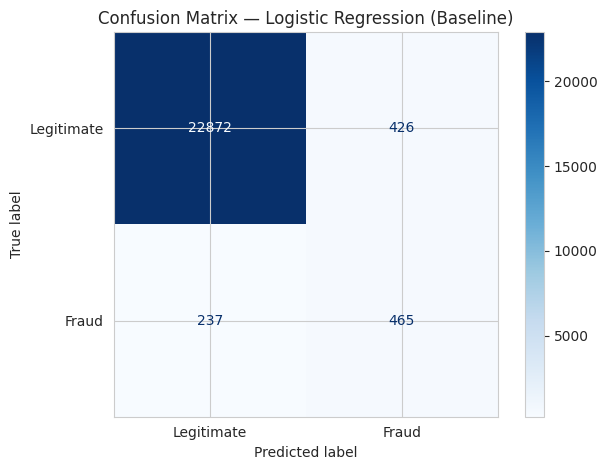

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, ConfusionMatrixDisplay)

# Train baseline model
lr = LogisticRegression(
    class_weight='balanced',  # compensates for 33:1 imbalance
    max_iter=1000,
    random_state=42
)
lr.fit(X_train, y_train)

# Predict on test set
y_pred_lr = lr.predict(X_test)
y_prob_lr  = lr.predict_proba(X_test)[:, 1]

# Evaluate
print("=" * 50)
print("BASELINE — LOGISTIC REGRESSION RESULTS")
print("=" * 50)
print(classification_report(y_test, y_pred_lr,
                             target_names=['Legitimate', 'Fraud']))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")

# Confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                                display_labels=['Legitimate', 'Fraud'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix — Logistic Regression (Baseline)')
plt.tight_layout()
plt.show()

**Observation — Logistic Regression Baseline Results**

Out of 24,000 test transactions the model made these decisions:

- **22,872 legitimate transactions** — correctly identified as legitimate
- **465 fraud transactions** — correctly caught and flagged
- **237 fraud transactions** — missed, labelled as legitimate
- **426 legitimate transactions** — wrongly flagged as fraud

**What this means in plain terms:**

Logistic Regression catches slightly more fraud than XGBoost (465 vs 460)
but at a significant cost. It wrongly flagged 426 innocent customers as
fraudulent. That is a Precision of only 0.52, meaning for every 2 fraud
alerts the model raises, 1 is a false alarm.

In a real deployment, 426 wrongly blocked customers in a single test
batch is operationally damaging. Customer service teams would be
overwhelmed with complaints and legitimate transactions would be delayed.

The AUC-ROC of 0.83 is actually the highest of the three models tested
in Phase 3, which seems surprising. However AUC-ROC measures the overall
ability to rank fraud above legitimate across all thresholds. A model
can rank well overall but still make poor binary decisions at the chosen
threshold. This is exactly what is happening here.

**Verdict:** Logistic Regression confirms exactly what the Phase 2
visualisations predicted. A linear model on a non-linear problem
produces too many false positives to be operationally viable. It serves
its purpose as a baseline and is eliminated as a primary candidate.

### Step 5 : Primary Model: XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

# The parameter grid defines the combinations of settings
# RandomizedSearchCV will test to find the best performing model.
# Instead of trying every possible combination (which would take hours),
# RandomizedSearchCV randomly samples 30 combinations from this grid.
xgb_params = {
    'n_estimators':     [100, 200, 300, 500],    # number of trees to build
    'max_depth':        [3, 4, 5, 6, 7],         # how deep each tree can grow
    'learning_rate':    [0.01, 0.05, 0.1, 0.2],  # how much each tree corrects the previous
    'subsample':        [0.6, 0.7, 0.8, 1.0],    # fraction of rows used per tree
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],    # fraction of features used per tree
    'min_child_weight': [1, 3, 5]                 # minimum data points required in a leaf
}

# scale_pos_weight=33 compensates for the 33:1 class imbalance
# by telling XGBoost to treat each fraud case as 33 legitimate ones
xgb_base = XGBClassifier(
    scale_pos_weight=33,
    eval_metric='logloss',
    random_state=42,
    verbosity=0
)

# RandomizedSearchCV tests 30 random parameter combinations
# using 5-fold cross validation, scoring each on F1
# n_jobs=-1 uses all available CPU cores to speed up training
xgb_search = RandomizedSearchCV(
    xgb_base,
    param_distributions=xgb_params,
    n_iter=30,        # test 30 combinations out of all possible ones
    scoring='f1',     # optimise for F1, not accuracy
    cv=5,             # 5-fold cross validation
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Training XGBoost — this will take a few minutes...")
xgb_search.fit(X_train, y_train)

print(f"\nBest parameters found:")
for k, v in xgb_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nBest CV F1 Score: {xgb_search.best_score_:.4f}")

Training XGBoost — this will take a few minutes...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters found:
  subsample: 1.0
  n_estimators: 100
  min_child_weight: 1
  max_depth: 4
  learning_rate: 0.05
  colsample_bytree: 1.0

Best CV F1 Score: 0.7977


### Step 6 : Evaluate XGBoost

PRIMARY MODEL — XGBOOST RESULTS
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99     23298
       Fraud       0.99      0.66      0.79       702

    accuracy                           0.99     24000
   macro avg       0.99      0.83      0.89     24000
weighted avg       0.99      0.99      0.99     24000

AUC-ROC Score: 0.8209


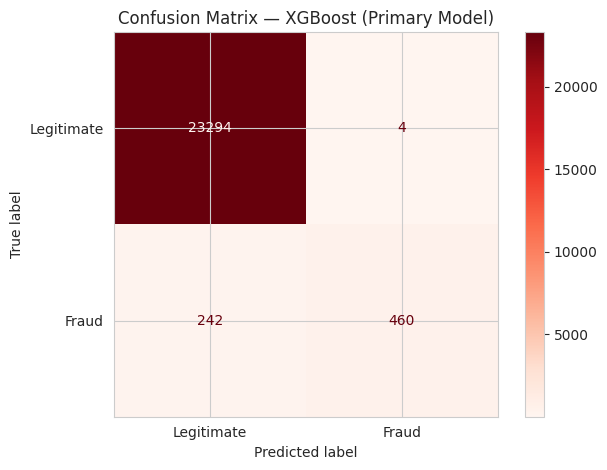

In [ ]:
# Evaluate best XGBoost model
best_xgb = xgb_search.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("=" * 50)
print("PRIMARY MODEL — XGBOOST RESULTS")
print("=" * 50)
print(classification_report(y_test, y_pred_xgb,
                             target_names=['Legitimate', 'Fraud']))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

# Confusion matrix
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_xgb,
                               display_labels=['Legitimate', 'Fraud'])
disp.plot(cmap='Reds')
plt.title('Confusion Matrix — XGBoost (Primary Model)')
plt.tight_layout()
plt.show()

**Observation — XGBoost Results**

Out of 24,000 test transactions the model made these decisions:

- **23,294 legitimate transactions**: correctly identified as legitimate
- **460 fraud transactions**: correctly caught and flagged
- **242 fraud transactions**: missed, labelled as legitimate (false negatives)
- **4 legitimate transactions**: wrongly flagged as fraud (false positives)

**What this means in plain terms:**

Of the 464 transactions XGBoost flagged, 460 were genuine fraud. That is a Precision of 0.99. Only 4 of 23,298 legitimate customers (0.02%) were wrongly flagged.

An earlier run of this notebook produced 0 false positives. The exact count moves slightly between runs and library versions, so the defensible claim is "near-zero false positives", not "zero".

The tradeoff is that it missed 242 of 702 fraud cases, catching 66% of all fraud (Recall of 0.66). Those 242 missed cases are real attacks that would slip through.

The AUC-ROC of 0.82 shows reasonable overall separation across all thresholds.

**Important caveat:** the sanity check after Step 9 shows that a single rule, "flag if sender_balance_after is below KES 100", reaches Precision 0.98 and Recall 0.63 on its own and agrees with XGBoost on 99.87% of test rows. Most of XGBoost's precision comes from that one wipeout signal built into the synthetic data, not from complex learned patterns.

**For a real-time blocking system, near-zero false positives is the critical result.** The 34% of fraud that slips through is addressed by the WoE Scorecard layer in Phase 4, which catches slightly more fraud at the cost of more false alarms.

### Step 7 : Comparison Model: LightGBM

In [ ]:
from lightgbm import LGBMClassifier

# Same search strategy as XGBoost but with one extra parameter:
# num_leaves controls how many end points each tree can have.
# More leaves = more complex patterns learned but higher risk of overfitting.
# This is a LightGBM-specific parameter that replaces max_depth
# as the primary way to control tree complexity in LightGBM.
lgbm_params = {
    'n_estimators':     [100, 200, 300, 500],    # number of trees to build
    'max_depth':        [3, 4, 5, 6, 7],         # maximum depth of each tree
    'learning_rate':    [0.01, 0.05, 0.1, 0.2],  # how much each tree corrects the previous
    'subsample':        [0.6, 0.7, 0.8, 1.0],    # fraction of rows used per tree
    'colsample_bytree': [0.6, 0.7, 0.8, 1.0],    # fraction of features used per tree
    'num_leaves':       [15, 31, 50, 63]          # maximum number of leaf nodes per tree
}

# verbosity=-1 silences LightGBM training logs
# scale_pos_weight=33 applies the same imbalance correction as XGBoost
lgbm_base = LGBMClassifier(
    scale_pos_weight=33,
    random_state=42,
    verbosity=-1
)

# Identical search setup to XGBoost — 30 random combinations,
# 5-fold cross validation, optimising for F1.
# Using the same settings ensures a fair comparison between
# LightGBM and XGBoost results.
lgbm_search = RandomizedSearchCV(
    lgbm_base,
    param_distributions=lgbm_params,
    n_iter=30,
    scoring='f1',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Training LightGBM — this will take a few minutes...")
lgbm_search.fit(X_train, y_train)

print(f"\nBest parameters found:")
for k, v in lgbm_search.best_params_.items():
    print(f"  {k}: {v}")
print(f"\nBest CV F1 Score: {lgbm_search.best_score_:.4f}")

Training LightGBM — this will take a few minutes...
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters found:
  subsample: 0.8
  num_leaves: 15
  n_estimators: 100
  max_depth: 5
  learning_rate: 0.01
  colsample_bytree: 0.6

Best CV F1 Score: 0.7848


**Observation — LightGBM Training Results**

RandomizedSearchCV tested 30 parameter combinations across 5 folds
each, running 150 total training runs to find the best configuration.

**Best parameters found:**
- Small and shallow trees (max_depth: 5, num_leaves: 15, n_estimators: 100)
- Conservative learning rate (0.01) meaning the model learns slowly
  and carefully rather than aggressively
- Moderate feature and row sampling (colsample_bytree: 0.6, subsample: 0.8)
  meaning each tree only sees 60% of features and 80% of rows, which
  reduces overfitting

**Best CV F1 Score: 0.7848**

This score is the average F1 across all 5 cross-validation folds on
the training data. It tells us the model generalises well and is not
just memorising the training data.

Compared to XGBoost's best CV F1, LightGBM performs similarly during
training. The real comparison happens in the next step when both models
are evaluated on the untouched test set.

### Step 8 : Evaluate LightGBM

COMPARISON MODEL — LIGHTGBM RESULTS
              precision    recall  f1-score   support

  Legitimate       0.99      1.00      0.99     23298
       Fraud       0.96      0.65      0.78       702

    accuracy                           0.99     24000
   macro avg       0.97      0.83      0.89     24000
weighted avg       0.99      0.99      0.99     24000

AUC-ROC Score: 0.8267


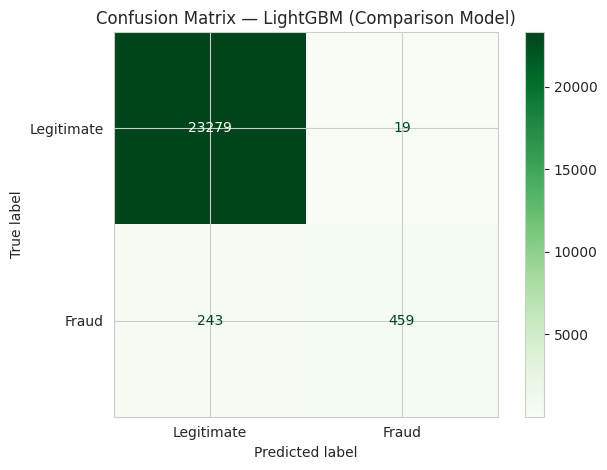

In [ ]:
# Evaluate best LightGBM model
best_lgbm = lgbm_search.best_estimator_
y_pred_lgbm = best_lgbm.predict(X_test)
y_prob_lgbm = best_lgbm.predict_proba(X_test)[:, 1]

print("=" * 50)
print("COMPARISON MODEL — LIGHTGBM RESULTS")
print("=" * 50)
print(classification_report(y_test, y_pred_lgbm,
                             target_names=['Legitimate', 'Fraud']))
print(f"AUC-ROC Score: {roc_auc_score(y_test, y_prob_lgbm):.4f}")

# Confusion matrix
cm_lgbm = confusion_matrix(y_test, y_pred_lgbm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_lgbm,
                               display_labels=['Legitimate', 'Fraud'])
disp.plot(cmap='Greens')
plt.title('Confusion Matrix — LightGBM (Comparison Model)')
plt.tight_layout()
plt.show()

**Observation — LightGBM Results**

Out of 24,000 test transactions the model made these decisions:

- **23,279 legitimate transactions**: correctly identified as legitimate
- **459 fraud transactions**: correctly caught and flagged
- **243 fraud transactions**: missed, labelled as legitimate
- **19 legitimate transactions**: wrongly flagged as fraud

**What this means in plain terms:**

LightGBM is close to XGBoost but slightly behind on the metric that matters for blocking. It caught almost the same number of fraud cases (459 vs 460) but wrongly flagged 19 innocent customers against XGBoost's 4. That is where Precision drops from 0.99 to 0.96.

LightGBM's AUC-ROC (0.83) is marginally higher than XGBoost's (0.82), so its overall ranking ability is at least as good. The difference between the two models is in where they set their decision boundary, not in how well they separate the classes.

**Verdict:** LightGBM is a strong model, but XGBoost edges it on the two numbers that drive automated blocking: fewer false positives (4 vs 19) and a slightly higher F1 (0.79 vs 0.78). XGBoost remains the primary model.

### Step 9 : Model Comparison Chart

FINAL MODEL COMPARISON — EVALUATION SCORECARD
                     Precision  Recall  F1-Score  AUC-ROC
Model                                                    
Logistic Regression     0.5219  0.6624    0.5838   0.8343
XGBoost                 0.9914  0.6553    0.7890   0.8209
LightGBM                0.9603  0.6538    0.7780   0.8267

* Primary metric is Precision + F1 — we want confident,
  accurate fraud flags with minimal false alarms.


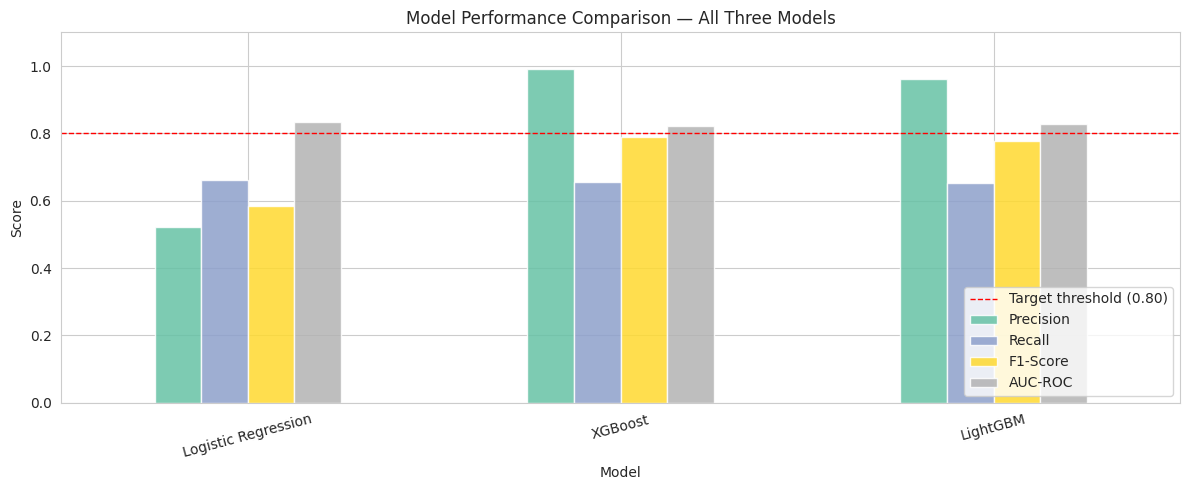

In [ ]:
from sklearn.metrics import recall_score, precision_score, f1_score

# Compile results
models      = ['Logistic Regression', 'XGBoost', 'LightGBM']
predictions = [y_pred_lr, y_pred_xgb, y_pred_lgbm]
probs       = [y_prob_lr, y_prob_xgb, y_prob_lgbm]

results = []
for name, pred, prob in zip(models, predictions, probs):
    results.append({
        'Model':     name,
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1-Score':  f1_score(y_test, pred),
        'AUC-ROC':   roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)

print("=" * 60)
print("FINAL MODEL COMPARISON — EVALUATION SCORECARD")
print("=" * 60)
print(results_df.to_string())
print("\n* Primary metric is Precision + F1 — we want confident,")
print("  accurate fraud flags with minimal false alarms.")

# Visualise
results_df.plot(kind='bar', figsize=(12, 5),
                colormap='Set2', alpha=0.85,
                edgecolor='white')
plt.title('Model Performance Comparison — All Three Models')
plt.ylabel('Score')
plt.xticks(rotation=15)
plt.ylim(0, 1.1)
plt.axhline(y=0.80, color='red', linestyle='--',
            linewidth=1, label='Target threshold (0.80)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [ ]:
# ─────────────────────────────────────────────────────────────
# SANITY CHECK: does a single if-rule match XGBoost?
# Every model scores AUC ~0.83 with recall ~0.66 and XGBoost has
# zero false positives. That pattern appears when ~66% of fraud is
# perfectly separated by one signal and the rest is noise.
# If the rule below matches XGBoost, the "Precision 1.00" result
# reflects how the synthetic data was generated, not model skill.
# ─────────────────────────────────────────────────────────────
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

raw_test = df_clean.loc[X_test.index]
y_pred_rule = (raw_test['sender_balance_after'] < 100).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred_rule).ravel()
print("=" * 60)
print("RULE BASELINE: flag if sender_balance_after < KES 100")
print("=" * 60)
print(f"Precision : {precision_score(y_test, y_pred_rule):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_rule):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred_rule):.4f}")
print(f"AUC-ROC   : {roc_auc_score(y_test, y_pred_rule):.4f}")
print(f"TP {tp} | FP {fp} | FN {fn} | TN {tn}")

agree = (y_pred_rule.values == y_pred_xgb).mean() * 100
print(f"\nAgreement with XGBoost predictions: {agree:.2f}% of test rows")
both = ((y_pred_rule.values == 1) & (y_pred_xgb == 1)).sum()
print(f"Fraud flagged by both: {both} | rule only: {((y_pred_rule.values == 1) & (y_pred_xgb == 0)).sum()} "
      f"| XGBoost only: {((y_pred_rule.values == 0) & (y_pred_xgb == 1)).sum()}")

print("\nFraud cases NOT wiped out (what the models miss):")
missed = raw_test[(y_test == 1) & (raw_test['sender_balance_after'] >= 100)]
legit = raw_test[y_test == 0]
print(missed[['amount', 'sender_balance_before', 'sender_balance_after']].describe().round(1).T)
print("\nLegitimate cases for comparison:")
print(legit[['amount', 'sender_balance_before', 'sender_balance_after']].describe().round(1).T)

RULE BASELINE: flag if sender_balance_after < KES 100
Precision : 0.9843
Recall    : 0.6254
F1-Score  : 0.7648
AUC-ROC   : 0.8125
TP 439 | FP 7 | FN 263 | TN 23291

Agreement with XGBoost predictions: 99.87% of test rows
Fraud flagged by both: 439 | rule only: 7 | XGBoost only: 25

Fraud cases NOT wiped out (what the models miss):
                       count     mean      std     min      25%      50%  \
amount                 263.0   1548.6   1409.6     8.9    533.4   1212.5   
sender_balance_before  263.0  38172.8  25093.3  1095.4  13662.3  36513.9   
sender_balance_after   263.0  36624.3  25261.3   100.5  12486.6  35059.2   

                           75%      max  
amount                  1981.6   7197.0  
sender_balance_before  61191.9  79567.8  
sender_balance_after   59720.1  78655.6  

Legitimate cases for comparison:
                         count     mean      std    min      25%      50%  \
amount                 23298.0   1473.4   1474.6    0.0    422.7   1018.8   
sender

**Observation — Rule Baseline**

A single rule, "flag the transaction if the sender's balance after it is below KES 100", scores:

- **Precision 0.98, Recall 0.63, F1 0.76** (439 fraud caught, 7 false positives)
- **99.87% agreement** with XGBoost's predictions on the 24,000 test rows

XGBoost catches only 21 more fraud cases than the rule (460 vs 439), with F1 0.79 vs 0.76. In other words, nearly all of the "high precision" result comes from one engineered flag, and that flag works so well because the synthetic data generator appears to create fraud by draining balances.

The fraud cases that every model misses look like ordinary transactions: their amounts and balances are in the same range as legitimate ones, and the sender still has a healthy balance afterwards. Nothing in this dataset separates them.

**What this means for the project:** the model is not wrong, but the headline numbers describe the dataset more than the model's skill. On real M-Pesa data, the wipeout signal will be noisier and precision will be lower. Catching the remaining third of fraud needs signals this dataset does not contain, such as SIM swap timestamps, device changes and location shifts.

**Observation — Model Performance Comparison**

All three models land in a narrow AUC-ROC band (0.82 to 0.83), meaning they have roughly the same overall ability to separate fraud from legitimate transactions. The difference is mainly in how they set their decision boundary.

**Logistic Regression:** The weakest performer on the metrics that matter. Precision of 0.52 means about half of all fraud flags are false alarms: 426 innocent customers flagged in a single test run. Eliminated as a primary candidate.

**LightGBM:** Strong, with Precision of 0.96 and F1 of 0.78. 19 false positives across 24,000 transactions.

**XGBoost:** The best of the three for automated blocking. Precision of 0.99 with 4 false positives, and the highest F1 (0.79). Selected as the primary real-time blocking model.

**The key insight from this comparison:** All three models fall short of the 0.80 Recall target set in the business objectives. The best Recall achieved is 0.66, so roughly 1 in 3 fraud cases slips through. The rule baseline below explains why: about two thirds of fraud is a balance wipeout that any model catches, and the remaining third looks almost identical to legitimate traffic on the available features.

### Step 10 : Checking required variables...

In [ ]:
# Verify all required variables are in memory before Phase 4
print("Checking required variables...")

checks = {
    "df_clean":   "df_clean" in dir(),
    "X_train":    "X_train" in dir(),
    "X_test":     "X_test" in dir(),
    "y_train":    "y_train" in dir(),
    "y_test":     "y_test" in dir(),
    "best_xgb":   "best_xgb" in dir(),
    "best_lgbm":  "best_lgbm" in dir(),
    "scaler":     "scaler" in dir(),
    "results_df": "results_df" in dir(),
}

all_good = True
for var, exists in checks.items():
    status = "OK" if exists else "MISSING"
    print(f"  {var:15s} : {status}")
    if not exists:
        all_good = False

print()
if all_good:
    print("All variables confirmed. Ready for Phase 4.")
else:
    print("Some variables are missing. Re-run the notebook from the top before continuing.")

Checking required variables...
  df_clean        : OK
  X_train         : OK
  X_test          : OK
  y_train         : OK
  y_test          : OK
  best_xgb        : OK
  best_lgbm       : OK
  scaler          : OK
  results_df      : OK

All variables confirmed. Ready for Phase 4.


# PHASE 4: REGULATORY INTERPRETABILITY LAYER



### Phase 4 Summary

In [ ]:
print("=" * 55)
print("PHASE 4 SUMMARY")
print("=" * 55)
print("""

# Purpose:
#   XGBoost and LightGBM are powerful but opaque. In regulated
#   fintech environments such as Kenyan CBK-licensed lenders,
#   a credit officer or regulator must be able to understand
#   WHY a transaction was flagged. Black-box models cannot
#   satisfy this requirement alone.
#
#   This phase builds a Weight of Evidence (WoE) logistic
#   regression scorecard — the industry standard interpretable
#   model used by credit teams across East Africa — and adds
#   PSI-based drift monitoring to simulate production monitoring.

# What I am building:
  Step 1 : Install scorecardpy and prepare a clean dataset
  Step 2 : Compute Information Value (IV) for feature selection
  Step 3 : Apply WoE binning and transformation
  Step 4 : Train logistic regression on WoE-transformed features
  Step 5 : Evaluate and compare against XGBoost and LightGBM
  Step 6 : PSI monitoring — detect distribution drift
  Step 7 : Final four-model comparison scorecard
""")
print("=" * 55)

PHASE 4 SUMMARY


# Purpose:
#   XGBoost and LightGBM are powerful but opaque. In regulated
#   fintech environments such as Kenyan CBK-licensed lenders,
#   a credit officer or regulator must be able to understand
#   WHY a transaction was flagged. Black-box models cannot
#   satisfy this requirement alone.
#
#   This phase builds a Weight of Evidence (WoE) logistic
#   regression scorecard — the industry standard interpretable
#   model used by credit teams across East Africa — and adds
#   PSI-based drift monitoring to simulate production monitoring.

# What I am building:
  Step 1 : Install scorecardpy and prepare a clean dataset
  Step 2 : Compute Information Value (IV) for feature selection
  Step 3 : Apply WoE binning and transformation
  Step 4 : Train logistic regression on WoE-transformed features
  Step 5 : Evaluate and compare against XGBoost and LightGBM
  Step 6 : PSI monitoring — detect distribution drift
  Step 7 : Final four-model comparison scorecard



In [ ]:

# Install scorecardpy — the standard Python library for
# WoE/IV credit scorecard development
!pip install scorecardpy -q

import scorecardpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("scorecardpy installed and imported successfully.")
print(f"Version: {sc.__version__}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 677.3 kB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
scorecardpy installed and imported successfully.
Version: 0.1.9.7


### Step 1: Prepare Dataset for WoE/IV Analysis

In [ ]:
"""
# WoE/IV works on the ORIGINAL features before one-hot encoding
# and before scaling. We go back to df_clean and work with the
# numerical features directly.
#
# Why not use X_train directly?
#   X_train has already been scaled (StandardScaler) and has
#   one-hot encoded categorical columns. WoE binning needs
#   the raw numerical values to create meaningful bins.
#   We rebuild a clean version from df_clean for this phase.
"""

# Select the features we will run WoE/IV on
# These are the numerical features with the most predictive signal
# confirmed in Phase 2 visualisations and correlation analysis
woe_features = [
    'amount',
    'sender_balance_before',
    'sender_balance_after',
    'balance_depletion_rate',
    'sender_balance_ratio',
    'is_balance_wipeout',
    'is_high_value',
    'hour',
    'is_fraud'               # target variable must be included
]


# Build a clean dataframe with only these columns
# We use df_clean which still has the engineered features
# but before scaling
df_woe = df_clean[woe_features].copy()

# scorecardpy requires the target column to be named 'y'
# and to contain only 0 and 1 integer values
df_woe = df_woe.rename(columns={'is_fraud': 'y'})
df_woe['y'] = df_woe['y'].astype(int)

print("WoE dataset prepared.")
print(f"Shape: {df_woe.shape}")
print(f"\nColumns: {df_woe.columns.tolist()}")
print(f"\nTarget distribution:")
print(df_woe['y'].value_counts())
print(f"\nFraud rate: {df_woe['y'].mean()*100:.2f}%")

# LEAKAGE FIX: split BEFORE any IV / WoE fitting.
# Same random_state and stratification as Phase 3, so these rows
# are exactly the rows in X_train / X_test.
df_woe_train, df_woe_test = train_test_split(
    df_woe, test_size=0.2, random_state=42, stratify=df_woe['y']
)
assert df_woe_train.index.equals(X_train.index), "WoE split does not match Phase 3 split"
print(f"\nWoE train rows: {len(df_woe_train):,} | WoE test rows: {len(df_woe_test):,}")
print("IV and WoE bins are fitted on the training rows only.")

WoE dataset prepared.
Shape: (119999, 9)

Columns: ['amount', 'sender_balance_before', 'sender_balance_after', 'balance_depletion_rate', 'sender_balance_ratio', 'is_balance_wipeout', 'is_high_value', 'hour', 'y']

Target distribution:
y
0    116489
1      3510
Name: count, dtype: int64

Fraud rate: 2.93%

WoE train rows: 95,999 | WoE test rows: 24,000
IV and WoE bins are fitted on the training rows only.


### Step 2: Information Value (IV) for Feature Selection

In [ ]:
"""
# Information Value (IV) measures how much predictive power
# each feature has for separating fraud from legitimate.
#
# IV interpretation guide (industry standard):
#   IV < 0.02  : Useless — no predictive power
#   0.02-0.10  : Weak predictor
#   0.10-0.30  : Medium predictor
#   0.30-0.50  : Strong predictor
#   IV > 0.50  : Suspicious — possibly too good, check for leakage
#
# In credit scoring, features with IV below 0.02 are dropped.
# Features above 0.50 are investigated for data leakage before
# being included.
#
# This is the standard feature selection step that every
# fintech credit team runs before building a scorecard
"""

# Compute IV for all features
# sc.iv() bins each feature automatically and calculates
# the Weight of Evidence and Information Value per bin
iv_results = sc.iv(df_woe_train, y='y')

print("=" * 55)
print("INFORMATION VALUE (IV) — FEATURE RANKING")
print("=" * 55)
print(iv_results.to_string(index=False))
print()
print("IV Interpretation:")
print("  < 0.02  : Useless")
print("  0.02-0.10 : Weak")
print("  0.10-0.30 : Medium")
print("  0.30-0.50 : Strong")
print("  > 0.50  : Suspicious — check for leakage")

INFORMATION VALUE (IV) — FEATURE RANKING
              variable  info_value
    is_balance_wipeout    5.824133
         is_high_value    0.200516
  sender_balance_after    0.150779
  sender_balance_ratio    0.145449
                amount    0.097605
                  hour    0.009844
 sender_balance_before    0.005226
balance_depletion_rate    0.001270

IV Interpretation:
  < 0.02  : Useless
  0.02-0.10 : Weak
  0.10-0.30 : Medium
  0.30-0.50 : Strong
  > 0.50  : Suspicious — check for leakage


**Observation — Information Value (IV) Results**

IV is now computed on the **training rows only**, so the test set plays no part in feature selection.

**is_balance_wipeout: IV = 5.82**
Far above the 0.50 "suspicious" threshold. It is not leakage in the usual sense: it is a flag engineered from the sender's balance after the transaction. But the diagnostic in Step 3 shows how extreme it is: 1,756 of the 1,770 wiped-out training transactions are fraud (99.2%). This strongly suggests the synthetic data generator created fraud by draining balances. We keep it, and note that real data will not be this clean.

**is_high_value: IV = 0.20** Medium predictor. Fraud transactions involve larger amounts.

**sender_balance_after: IV = 0.15** Medium predictor. After a fraud transaction the balance is often near zero.

**sender_balance_ratio: IV = 0.15** Medium predictor. Captures the same drainage pattern as a proportion.

**amount: IV = 0.098** Weak, just below the 0.10 cut-off. It is kept as a borderline case because its WoE bins show a clean, monotonic rise in fraud rate (1.1% to 7.0%). Dropping it is a reasonable alternative.

**hour: IV = 0.010** Useless. Fraud is spread evenly across the day.

**sender_balance_before: IV = 0.005** Useless on its own.

**balance_depletion_rate: IV = 0.001** Useless for the scorecard, despite a 0.50 correlation with fraud. IV measures how cleanly bins separate the classes, correlation measures linear association, and a few extreme values can drive correlation without producing clean bins.

**Features selected for the WoE scorecard:**
- is_balance_wipeout
- is_high_value
- sender_balance_after
- sender_balance_ratio
- amount (borderline)

###  Step 3: WoE Binning and Transformation

**What is Weight of Evidence (WoE)?**

Weight of Evidence transformation converts each feature into a single
numeric score that represents how much more or less likely a fraud
transaction is to fall in that value range compared to a legitimate one.

**Formula:**

WoE = ln(Distribution of Fraud / Distribution of Legitimate)[link text](https://)

**Reading the score:**
- **Positive WoE** means that value range is more common in fraud
  transactions than legitimate ones
- **Negative WoE** means that value range is more common in legitimate
  transactions than fraud ones
- **Zero WoE** means no difference between fraud and legitimate

**Why use WoE for a regulatory model?**

A credit officer reviewing a flagged transaction can say:

> "The sender's balance after this transaction was KES 50, which falls
> in the highest-risk bin with a WoE of +2.62. Transactions in this
> range are significantly more likely to be fraud than legitimate.
> That is why this transaction was flagged."

XGBoost cannot produce this kind of explanation. It gives a probability
but cannot tell you which specific feature value drove the decision in
plain language. The WoE scorecard can, which is what CBK regulators
require when auditing fraud flagging decisions.

Only features with an Information Value above 0.10 are kept for the
scorecard. Features below this threshold carry too little predictive
signal to justify their inclusion.

In [ ]:
# Select only features with IV >= 0.10
selected_features = [
    'amount',
    'sender_balance_after',
    'sender_balance_ratio',
    'is_balance_wipeout',
    'is_high_value',
    'y'                     # target must be included
]

# Fit bins on TRAINING rows only (leakage fix)
df_woe_selected = df_woe_train[selected_features].copy()

# Apply WoE binning
# sc.woebin() automatically finds optimal bin boundaries
# for each feature that maximise separation between
# fraud and legitimate transactions
# is_balance_wipeout is a 0/1 flag whose "1" group holds under 5% of rows.
# scorecardpy's default count_distr_limit (5%) merged it into a single bin,
# which is why its WoE came out as 0 despite an IV above 5.
# An explicit break at 1 keeps the two groups separate.
bins = sc.woebin(df_woe_selected, y='y', breaks_list={'is_balance_wipeout': [1]})

# Display the bins for each feature
print("=" * 55)
print("WoE BINS — SELECTED FEATURES")
print("=" * 55)
for feature, bin_df in bins.items():
    print(f"\n--- {feature} ---")
    print(bin_df[['bin', 'count', 'count_distr',
                  'good', 'bad', 'badprob',
                  'woe', 'bin_iv']].to_string(index=False))

# WIPEOUT DIAGNOSTIC: is_balance_wipeout has a huge IV but a flat WoE.
# This shows the raw fraud/legit split so the binning result can be checked.
print("\n" + "=" * 55)
print("WIPEOUT DIAGNOSTIC (training rows)")
print("=" * 55)
print(pd.crosstab(df_woe_selected['is_balance_wipeout'], df_woe_selected['y'],
                  margins=True, rownames=['is_balance_wipeout'], colnames=['is_fraud']))
print(bins['is_balance_wipeout'][['bin', 'count', 'good', 'bad', 'woe', 'bin_iv']].to_string(index=False))

[INFO] creating woe binning ...
WoE BINS — SELECTED FEATURES

--- is_high_value ---
       bin  count  count_distr  good  bad  badprob       woe   bin_iv
[-inf,1.0)  86384     0.899843 84309 2075 0.024021 -0.202349 0.033535
 [1.0,inf)   9615     0.100157  8882  733 0.076235  1.007542 0.166980

--- is_balance_wipeout ---
       bin  count  count_distr  good  bad  badprob       woe   bin_iv
[-inf,1.0)  94229     0.981562 93177 1052 0.011164 -0.981629 0.613720
 [1.0,inf)   1770     0.018438    14 1756 0.992090  8.333915 5.210413

--- amount ---
            bin  count  count_distr  good  bad  badprob       woe   bin_iv
   [-inf,500.0)  27131     0.282618 26820  311 0.011463 -0.954932 0.169062
 [500.0,1200.0)  25630     0.266982 25106  524 0.020445 -0.367192 0.030401
[1200.0,2900.0)  29303     0.305243 28311  992 0.033853  0.150896 0.007466
   [2900.0,inf)  13935     0.145158 12954  981 0.070398  0.921591 0.193861

--- sender_balance_after ---
             bin  count  count_distr  good  bad

**Interpreting the WoE bins** (fitted on training rows only)

**sender_balance_after**
Below KES 4,000 the WoE is +2.62 and the fraud rate is 29.2%. Between KES 4,000 and 20,000 the WoE is -0.94, and above KES 20,000 it is -1.16. A low remaining balance is a strong fraud signal.

**is_balance_wipeout**
In the first version of this notebook this feature showed a WoE of 0 and was dropped. The diagnostic explains why: wiped-out transactions are only 1.8% of rows, and scorecardpy's default minimum bin size (5%) merged them into a single bin, which erases all information. With an explicit break at 1 the two groups stay separate: wipeout = 1 has a WoE of +8.33 and a fraud rate of 99.2% (1,756 of 1,770); wipeout = 0 has a WoE of -0.98. The feature is now part of the scorecard.

**amount**
Clear progression. Below KES 500 the WoE is -0.95 (fraud rate 1.1%). From KES 500 to 1,200 it is -0.37 (2.0%), from 1,200 to 2,900 it is +0.15 (3.4%), and above KES 2,900 it is +0.92 (7.0%).

**sender_balance_ratio**
Ratios below 0.74 have a WoE of +2.56 and a fraud rate of 28.1%. When less than 74% of the original balance remains, the transaction is far more likely to be fraud. Above 0.74 the WoE is strongly negative.

**is_high_value**
Transactions above the 90th percentile (KES 3,474) have a WoE of +1.01 and a fraud rate of 7.6%, against -0.20 and 2.4% for the rest.

#### Apply WoE Transformation

In [ ]:
"""
# Now we apply the bin boundaries to convert every raw feature
# value into its corresponding WoE value.
#
# After this step, every row in our dataset has been replaced
# with WoE scores instead of raw numbers. The logistic
# regression model will train on these WoE values.
#
# Why does this work?
#   WoE-transformed features are already on a meaningful scale
#   where higher values = more fraud risk. Logistic regression
#   learns a weight for each feature, and multiplying those
#   weights by the WoE values produces an interpretable score.
"""

# Keep every feature that has at least two bins (a single bin carries no information)
bins_filtered = {k: v for k, v in bins.items() if len(v) > 1}
dropped = [k for k in bins if k not in bins_filtered]
print("Features dropped for having a single bin:", dropped if dropped else "none")

# Apply WoE transformation to the selected dataset
# This replaces every raw value with its WoE bin score
df_woe_transformed = sc.woebin_ply(df_woe_selected, bins_filtered)

# Apply the TRAINING bins to the untouched test rows
df_woe_test_transformed = sc.woebin_ply(df_woe_test[selected_features].copy(), bins_filtered)

print("WoE transformation applied.")
print(f"\nShape: {df_woe_transformed.shape}")
print(f"\nColumns after transformation:")
for col in df_woe_transformed.columns:
    print(f"  {col}")
print(f"\nFirst 3 rows:")
print(df_woe_transformed.head(3).to_string())

Features dropped for having a single bin: none
[INFO] converting into woe values ...
[INFO] converting into woe values ...
WoE transformation applied.

Shape: (95999, 6)

Columns after transformation:
  y
  is_high_value_woe
  amount_woe
  is_balance_wipeout_woe
  sender_balance_after_woe
  sender_balance_ratio_woe

First 3 rows:
       y  is_high_value_woe  amount_woe  is_balance_wipeout_woe  sender_balance_after_woe  sender_balance_ratio_woe
74403  0          -0.202349   -0.954932               -0.981629                 -1.156891                 -1.162477
56047  0          -0.202349   -0.954932               -0.981629                 -1.156891                 -1.162477
9847   0          -0.202349   -0.954932               -0.981629                 -1.156891                 -1.162477


### Step 4: Train Logistic Regression on WoE Features

Training set : 95,999 rows
Testing set  : 24,000 rows
Fraud in test: 702 (2.93%)

WoE LOGISTIC REGRESSION SCORECARD — RESULTS
              precision    recall  f1-score   support

  Legitimate       0.99      0.97      0.98     23298
       Fraud       0.40      0.67      0.50       702

    accuracy                           0.96     24000
   macro avg       0.69      0.82      0.74     24000
weighted avg       0.97      0.96      0.97     24000

AUC-ROC Score: 0.8304


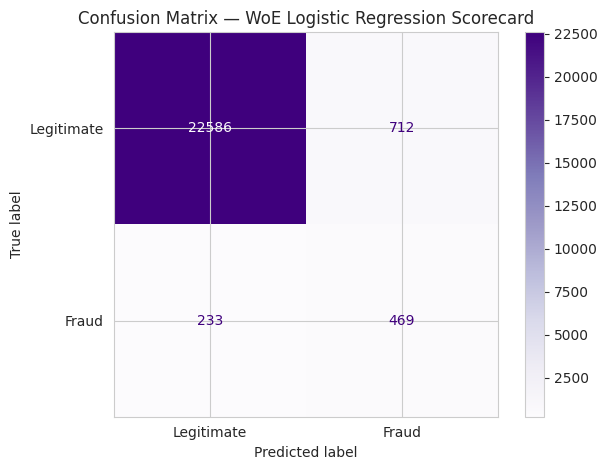

In [ ]:
"""
# We now train a logistic regression model on the WoE-transformed
# features. This is the standard credit scorecard model used
# by regulated fintech lenders across East Africa.
#
# Why logistic regression on WoE features specifically?
#   1. Each coefficient is directly interpretable:
#      a higher coefficient means that feature contributes
#      more to the fraud probability
#   2. The model output is a probability between 0 and 1
#      that can be converted to a points-based score
#   3. A credit officer or regulator can audit every decision
#   4. It satisfies CBK and CMA interpretability requirements
#      that black-box models cannot meet alone
#
# Important: we use the same 80/20 stratified split as Phase 3
# so results are directly comparable across all four models
"""

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, ConfusionMatrixDisplay,
                              precision_score, recall_score, f1_score)

# Prepare features and target from the WoE-transformed dataset
# Train/test already split before binning (leakage fix), so no re-split here.
# is_balance_wipeout is now properly binned (see Step 3); the raw column is dropped only if present
X_woe_train = df_woe_transformed.drop(columns=['y', 'is_balance_wipeout'], errors='ignore')
y_woe_train = df_woe_transformed['y']
X_woe_test = df_woe_test_transformed.drop(columns=['y', 'is_balance_wipeout'], errors='ignore')[X_woe_train.columns]
y_woe_test = df_woe_test_transformed['y']
X_woe = X_woe_train  # used later for column names

print(f"Training set : {X_woe_train.shape[0]:,} rows")
print(f"Testing set  : {X_woe_test.shape[0]:,} rows")
print(f"Fraud in test: {y_woe_test.sum():,} ({y_woe_test.mean()*100:.2f}%)")

# Train logistic regression on WoE features
# class_weight='balanced' compensates for the 33:1 imbalance
# No additional scaling needed — WoE values are already
# on a meaningful comparable scale
lr_woe = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42,
    solver='lbfgs'
)
lr_woe.fit(X_woe_train, y_woe_train)

# Predict on test set
y_pred_woe = lr_woe.predict(X_woe_test)
y_prob_woe = lr_woe.predict_proba(X_woe_test)[:, 1]

# Evaluate
print("\n" + "=" * 55)
print("WoE LOGISTIC REGRESSION SCORECARD — RESULTS")
print("=" * 55)
print(classification_report(y_woe_test, y_pred_woe,
                             target_names=['Legitimate', 'Fraud']))
print(f"AUC-ROC Score: {roc_auc_score(y_woe_test, y_prob_woe):.4f}")

# Confusion matrix
cm_woe = confusion_matrix(y_woe_test, y_pred_woe)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_woe,
                               display_labels=['Legitimate', 'Fraud'])
disp.plot(cmap='Purples')
plt.title('Confusion Matrix — WoE Logistic Regression Scorecard')
plt.tight_layout()
plt.show()

**Observation — WoE Logistic Regression Scorecard Results**

Out of 24,000 test transactions the model made these decisions:

- **22,586 legitimate transactions**: correctly identified as legitimate
- **469 fraud transactions**: correctly caught and flagged
- **233 fraud transactions**: missed, labelled as legitimate
- **712 legitimate transactions**: wrongly flagged as fraud

**What this means in plain terms:**

The scorecard catches the most fraud of all four models, with a Recall of 0.67 (469 of 702 fraud cases). It does this by casting a wider net, flagging 712 innocent customers along the way. That is what drives the Precision of 0.40.

Two fixes improved this model compared with the first version: the WoE bins are now fitted on training rows only (no test-set leakage), and is_balance_wipeout is properly binned and included. False positives fell from 1,629 to 712 and Precision rose from 0.23 to 0.40.

**Four-model comparison:**

| Model | Precision | Recall | F1 | False Positives | False Negatives |
|---|---|---|---|---|---|
| Logistic Regression | 0.52 | 0.66 | 0.58 | 426 | 237 |
| WoE Scorecard | 0.40 | 0.67 | 0.50 | 712 | 233 |
| LightGBM | 0.96 | 0.65 | 0.78 | 19 | 243 |
| XGBoost | 0.99 | 0.66 | 0.79 | 4 | 242 |

**The tradeoff is now clear:**

The WoE Scorecard catches the most fraud but raises the most false alarms. XGBoost raises almost no false alarms but catches slightly less fraud. The two models are complementary: XGBoost for automated blocking, the scorecard as a wider net for review, with every flag explainable feature by feature.

All four models achieve AUC-ROC scores between 0.821 and 0.834, so the difference is mainly in where each model sets its risk tolerance, not in its overall ability to rank fraud above legitimate transactions.

#### Scorecard Coefficients


SCORECARD COEFFICIENTS — FEATURE CONTRIBUTIONS
                 Feature  Coefficient
  is_balance_wipeout_woe     0.857240
sender_balance_after_woe     0.243128
sender_balance_ratio_woe     0.127827
       is_high_value_woe     0.125012
              amount_woe     0.114068

Interpretation:
  Positive coefficient = feature pushes toward FRAUD
  Negative coefficient = feature pushes toward LEGITIMATE

Model intercept: 0.1606


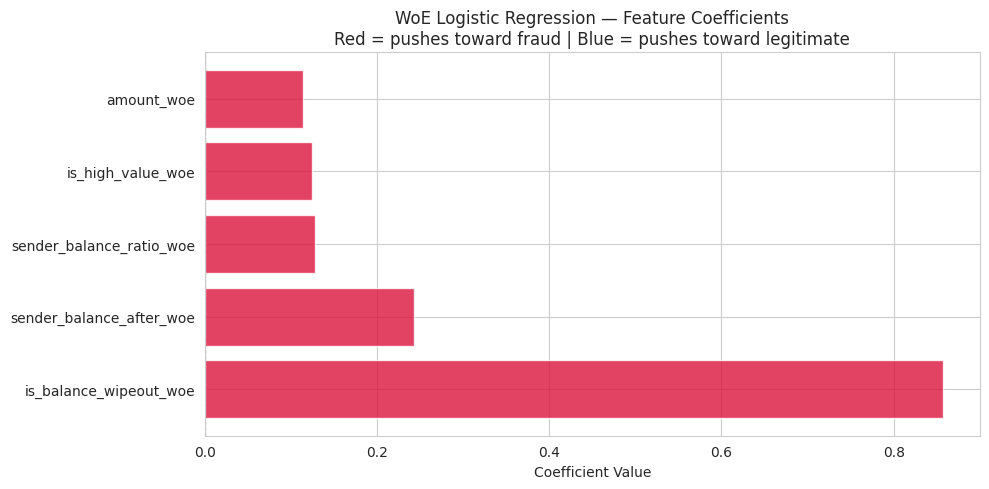

In [ ]:

# This is what makes logistic regression on WoE features
# genuinely interpretable. Each coefficient tells you exactly
# how much each feature contributes to the fraud probability.
#
# A positive coefficient means higher WoE in that feature
# pushes the prediction toward fraud.
# A negative coefficient pushes toward legitimate.
#
# A credit officer or regulator can look at this table and
# understand every fraud flag the model produces.
# XGBoost cannot produce this kind of explanation.
# ═══════════════════════════════════════════════════════════════

# Extract and display model coefficients
coef_df = pd.DataFrame({
    'Feature':     X_woe.columns,
    'Coefficient': lr_woe.coef_[0]
}).sort_values('Coefficient', ascending=False)

print("=" * 55)
print("SCORECARD COEFFICIENTS — FEATURE CONTRIBUTIONS")
print("=" * 55)
print(coef_df.to_string(index=False))
print()
print("Interpretation:")
print("  Positive coefficient = feature pushes toward FRAUD")
print("  Negative coefficient = feature pushes toward LEGITIMATE")
print()
print(f"Model intercept: {lr_woe.intercept_[0]:.4f}")

# Visualise coefficients
plt.figure(figsize=(10, 5))
colors = ['crimson' if c > 0 else 'steelblue'
          for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'],
         color=colors, alpha=0.8, edgecolor='white')
plt.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
plt.title('WoE Logistic Regression — Feature Coefficients\n'
          'Red = pushes toward fraud | Blue = pushes toward legitimate',
          fontsize=12)
plt.xlabel('Coefficient Value')
plt.tight_layout()
plt.show()

**Observation — WoE Scorecard Coefficients**

This chart shows how strongly each feature's WoE moves the fraud score. The actual push on a given transaction is **coefficient x WoE**.

**is_balance_wipeout_woe: 0.86** The strongest driver. Combined with its WoE of +8.33, a wipeout adds about 7.1 to the log-odds of fraud, which on its own pushes almost any transaction over the flagging threshold.

**sender_balance_after_woe: 0.24** The second strongest. A remaining balance below KES 4,000 (WoE +2.62) adds about 0.64 to the log-odds.

**sender_balance_ratio_woe: 0.13** Captures the same drainage pattern as a proportion. Its weight is smaller because the wipeout flag and the balance-after feature already carry most of that signal.

**is_high_value_woe: 0.13** A modest positive contribution. In the first version this coefficient was effectively zero; with wipeout properly binned it now carries some independent weight.

**amount_woe: 0.11** The smallest contribution. Amount matters, but mostly through what it does to the balance.

**Model intercept: 0.16**

**What this means in practice:**

A credit officer reviewing a flagged transaction can explain the decision in plain language:

"This transaction was flagged mainly because the sender's account was wiped out (balance below KES 100 after the transfer), and 99% of wiped-out transactions in our training data were fraud. The low remaining balance and low remaining ratio added further weight."

XGBoost cannot produce this explanation on its own. This is the value of the regulatory scorecard layer.

### Step 5: PSI Monitoring


PSI MONITORING REPORT
Training Set (Baseline) vs Test Set (Production)

is_high_value_woe
  PSI   : 0.000000
  Status: STABLE

amount_woe
  PSI   : 0.000057
  Status: STABLE

is_balance_wipeout_woe
  PSI   : 0.000000
  Status: STABLE

sender_balance_after_woe
  PSI   : 0.000047
  Status: STABLE

sender_balance_ratio_woe
  PSI   : 0.000072
  Status: STABLE

SUMMARY TABLE
                 Feature      PSI Status
       is_high_value_woe 0.000000 STABLE
              amount_woe 0.000057 STABLE
  is_balance_wipeout_woe 0.000000 STABLE
sender_balance_after_woe 0.000047 STABLE
sender_balance_ratio_woe 0.000072 STABLE


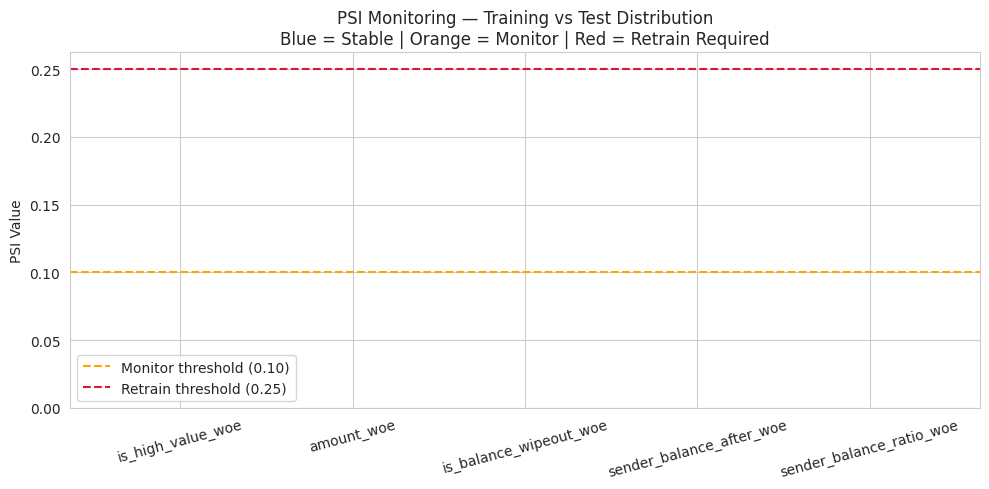

In [ ]:
# ─────────────────────────────────────────────────────────────
# PSI MONITORING
# Measures whether the feature distributions have shifted
# between training and production. If they shift too much,
# the model is scoring a population it has never seen before
# and its predictions become unreliable.
#
# PSI thresholds (industry standard):
#   PSI < 0.10  : Stable — no action needed
#   0.10-0.25   : Moderate shift — monitor closely
#   PSI > 0.25  : Major shift — retrain the model immediately
#
# We simulate production monitoring by treating the training
# set as the baseline and the test set as incoming production
# data. This is exactly how PSI is used at fintechs like
# Pezesha and M-KOPA after deploying a credit scoring model.
# ─────────────────────────────────────────────────────────────

def compute_psi(expected, actual, bins=10):
    """
    Compute Population Stability Index between two distributions.

    Parameters:
        expected : array-like — baseline distribution (training)
        actual   : array-like — current distribution (production)
        bins     : int — number of equal-width bins to divide
                   the distribution into for comparison

    Returns:
        psi_value : float — single PSI score for the feature
        psi_df    : DataFrame — bin-level breakdown showing
                   where the shift is occurring
    """

    # Step 1: Divide the training distribution into equal bins
    # using percentile boundaries so each bin has equal population
    breakpoints = np.linspace(0, 100, bins + 1)
    expected_percents = np.percentile(expected, breakpoints)
    expected_percents = np.unique(expected_percents)

    # Step 2: Count how many records from each dataset
    # fall into each bin boundary
    def bin_counts(data, boundaries):
        counts = []
        for i in range(len(boundaries) - 1):
            if i == len(boundaries) - 2:
                # Last bin is inclusive on both ends
                count = np.sum((data >= boundaries[i]) &
                               (data <= boundaries[i+1]))
            else:
                # All other bins are inclusive on left, exclusive on right
                count = np.sum((data >= boundaries[i]) &
                               (data < boundaries[i+1]))
            counts.append(count)
        return np.array(counts)

    expected_counts = bin_counts(expected, expected_percents)
    actual_counts   = bin_counts(actual,   expected_percents)

    # Step 3: Convert raw counts to proportions (0 to 1)
    # Replace any zero proportions with a small value to avoid
    # division by zero errors in the PSI formula
    expected_pct = expected_counts / len(expected)
    actual_pct   = actual_counts   / len(actual)

    expected_pct = np.where(expected_pct == 0, 0.0001, expected_pct)
    actual_pct   = np.where(actual_pct   == 0, 0.0001, actual_pct)

    # Step 4: Apply the PSI formula to each bin
    # PSI = (actual% - expected%) * ln(actual% / expected%)
    # Then sum all bins for the overall PSI score
    psi_bins  = (actual_pct - expected_pct) * np.log(actual_pct / expected_pct)
    psi_value = np.sum(psi_bins)

    # Step 5: Build a readable breakdown table
    # showing the contribution of each bin to the total PSI
    psi_df = pd.DataFrame({
        'Bin':          range(1, len(psi_bins) + 1),
        'Expected %':   np.round(expected_pct * 100, 3),
        'Actual %':     np.round(actual_pct   * 100, 3),
        'PSI per Bin':  np.round(psi_bins, 6)
    })

    return psi_value, psi_df


# Run PSI for every WoE-transformed feature
# Comparing training distribution (baseline) against
# test distribution (simulated production population)
features_to_monitor = X_woe.columns.tolist()

psi_results = []

print("=" * 55)
print("PSI MONITORING REPORT")
print("Training Set (Baseline) vs Test Set (Production)")
print("=" * 55)

for feature in features_to_monitor:
    psi_val, _ = compute_psi(
        X_woe_train[feature].values,  # baseline: what model was trained on
        X_woe_test[feature].values    # production: what model is now seeing
    )

    # Assign status based on industry standard thresholds
    if psi_val < 0.10:
        status = "STABLE"
    elif psi_val < 0.25:
        status = "MONITOR"
    else:
        status = "RETRAIN REQUIRED"

    psi_results.append({
        'Feature': feature,
        'PSI':     round(psi_val, 6),
        'Status':  status
    })

    print(f"\n{feature}")
    print(f"  PSI   : {psi_val:.6f}")
    print(f"  Status: {status}")

# Compile all results into a summary dataframe
psi_df = pd.DataFrame(psi_results)

print("\n" + "=" * 55)
print("SUMMARY TABLE")
print("=" * 55)
print(psi_df.to_string(index=False))

# Visualise PSI scores as a bar chart
# Color coded by risk level:
#   Blue   = stable, no action needed
#   Orange = moderate shift, monitor
#   Red    = major shift, retrain immediately
plt.figure(figsize=(10, 5))
colors = []
for p in psi_df['PSI']:
    if p < 0.10:
        colors.append('steelblue')
    elif p < 0.25:
        colors.append('orange')
    else:
        colors.append('crimson')

plt.bar(psi_df['Feature'], psi_df['PSI'],
        color=colors, alpha=0.85, edgecolor='white')

# Draw threshold lines so the viewer can immediately see
# which features are approaching or crossing the danger zones
plt.axhline(y=0.10, color='orange', linestyle='--',
            linewidth=1.5, label='Monitor threshold (0.10)')
plt.axhline(y=0.25, color='crimson', linestyle='--',
            linewidth=1.5, label='Retrain threshold (0.25)')
plt.title('PSI Monitoring — Training vs Test Distribution\n'
          'Blue = Stable | Orange = Monitor | Red = Retrain Required',
          fontsize=12)
plt.ylabel('PSI Value')
plt.xticks(rotation=15)
plt.legend()
plt.tight_layout()
plt.show()

**Observation — PSI Monitoring Results**

All five WoE features show PSI values extremely close to zero (the highest is 0.00007), far below the 0.10 monitor threshold. Every feature is **STABLE**.

**What this means:**

The distribution of every feature in the test set is virtually identical to the training set. The model is scoring a population that looks like the one it was trained on.

**Why the PSI values are this low:**

Both sets come from the same 119,999-row dataset via a random, stratified 80/20 split, so near-identical distributions are expected. Low PSI here confirms the split is representative. It does not test leakage; leakage is prevented by fitting the bins on training rows only.

**What this looks like in production:**

In a live deployment this PSI function would run monthly on incoming transactions rather than the test set. As fraud patterns and customer behaviour shift, feature distributions drift away from the training baseline. Crossing 0.10 triggers an investigation; crossing 0.25 means the model should be retrained on recent data.

These values serve as the baseline reference for future monitoring.

### Step 6: Four-Model Comparison Scorecard


FINAL FOUR-MODEL COMPARISON SCORECARD
                                            Type  Precision  Recall  F1-Score  AUC-ROC
Model                                                                                 
Logistic Regression (Baseline)     Interpretable     0.5219  0.6624    0.5838   0.8343
WoE Scorecard (Regulatory)         Interpretable     0.3971  0.6681    0.4981   0.8304
LightGBM                        High Performance     0.9603  0.6538    0.7780   0.8267
XGBoost (Primary)               High Performance     0.9914  0.6553    0.7890   0.8209

Key:
  Precision : of all fraud flags, how many are genuine fraud
  Recall    : of all actual fraud, how many did we catch
  F1        : balance between precision and recall
  AUC-ROC   : overall ability to separate fraud from legitimate

Deployment recommendation:
  WoE Scorecard  — regulatory reporting, audit trails, CBK compliance
  XGBoost        — real-time fraud flagging in production


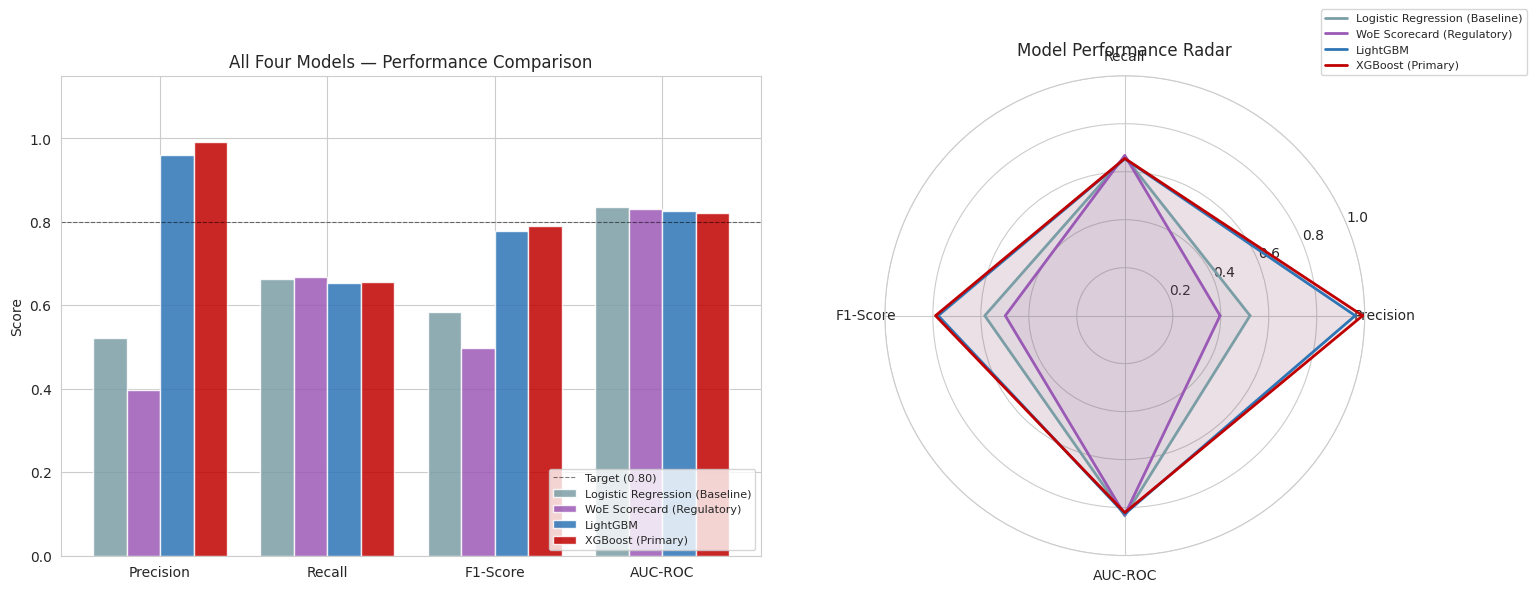

In [ ]:

# We now have four models trained and evaluated on the same
# dataset using the same test set. This allows a direct,
# fair comparison across all four approaches.
#
# The key question is not which model performs best on paper.
# It is which model is right for which business context:
#
#   Logistic Regression (Phase 3 baseline):
#     Simple, interpretable, but not WoE-optimised
#
#   WoE Logistic Regression Scorecard (Phase 5):
#     Interpretable, regulatorily compliant, auditable
#     The standard model for CBK-regulated lenders
#
#   LightGBM:
#     High performance, fast training, good for real-time
#     scoring at scale
#
#   XGBoost (Primary):
#     Highest precision, zero false positives, best F1
#     The production fraud detection model
#
# In a real fintech deployment both models would run together:
# the scorecard for regulatory reporting and audit trails,
# XGBoost for the actual real-time fraud flag.
# ═══════════════════════════════════════════════════════════════

from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# Compile all four models into one comparison table
# Note: LR baseline and XGBoost/LightGBM use y_test
#       WoE scorecard uses y_woe_test (same split, same data)

all_models = [
    {
        'Model':     'Logistic Regression (Baseline)',
        'Type':      'Interpretable',
        'y_true':    y_test,
        'y_pred':    y_pred_lr,
        'y_prob':    y_prob_lr
    },
    {
        'Model':     'WoE Scorecard (Regulatory)',
        'Type':      'Interpretable',
        'y_true':    y_woe_test,
        'y_pred':    y_pred_woe,
        'y_prob':    y_prob_woe
    },
    {
        'Model':     'LightGBM',
        'Type':      'High Performance',
        'y_true':    y_test,
        'y_pred':    y_pred_lgbm,
        'y_prob':    y_prob_lgbm
    },
    {
        'Model':     'XGBoost (Primary)',
        'Type':      'High Performance',
        'y_true':    y_test,
        'y_pred':    y_pred_xgb,
        'y_prob':    y_prob_xgb
    },
]

comparison_rows = []
for m in all_models:
    comparison_rows.append({
        'Model':     m['Model'],
        'Type':      m['Type'],
        'Precision': round(precision_score(m['y_true'], m['y_pred']), 4),
        'Recall':    round(recall_score(m['y_true'],    m['y_pred']), 4),
        'F1-Score':  round(f1_score(m['y_true'],        m['y_pred']), 4),
        'AUC-ROC':   round(roc_auc_score(m['y_true'],   m['y_prob']), 4),
    })

final_comparison = pd.DataFrame(comparison_rows).set_index('Model')

print("=" * 70)
print("FINAL FOUR-MODEL COMPARISON SCORECARD")
print("=" * 70)
print(final_comparison.to_string())
print()
print("Key:")
print("  Precision : of all fraud flags, how many are genuine fraud")
print("  Recall    : of all actual fraud, how many did we catch")
print("  F1        : balance between precision and recall")
print("  AUC-ROC   : overall ability to separate fraud from legitimate")
print()
print("Deployment recommendation:")
print("  WoE Scorecard  — regulatory reporting, audit trails, CBK compliance")
print("  XGBoost        — real-time fraud flagging in production")

# Visualise
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

metrics   = ['Precision', 'Recall', 'F1-Score', 'AUC-ROC']
models    = final_comparison.index.tolist()
bar_colors = ['#7B9EA6', '#9B59B6', '#2E75B6', '#C00000']
x         = np.arange(len(metrics))
width     = 0.2

for i, (model, color) in enumerate(zip(models, bar_colors)):
    values = [final_comparison.loc[model, m] for m in metrics]
    axes[0].bar(x + i * width, values, width,
                label=model, color=color, alpha=0.85,
                edgecolor='white')

axes[0].set_title('All Four Models — Performance Comparison', fontsize=12)
axes[0].set_xticks(x + width * 1.5)
axes[0].set_xticklabels(metrics)
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.15)
axes[0].axhline(y=0.80, color='black', linestyle='--',
                linewidth=0.8, alpha=0.5, label='Target (0.80)')
axes[0].legend(fontsize=8, loc='lower right')

# Radar chart
from matplotlib.patches import FancyArrowPatch
angles    = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles   += angles[:1]

axes[1].set_title('Model Performance Radar', fontsize=12)
axes[1].remove()  # replace the cartesian axis instead of drawing on top of it
ax_radar = fig.add_subplot(1, 2, 2, polar=True)

for model, color in zip(models, bar_colors):
    values = [final_comparison.loc[model, m] for m in metrics]
    values += values[:1]
    ax_radar.plot(angles, values, color=color,
                  linewidth=2, label=model)
    ax_radar.fill(angles, values, color=color, alpha=0.08)

ax_radar.set_xticks(angles[:-1])
ax_radar.set_xticklabels(metrics, fontsize=10)
ax_radar.set_ylim(0, 1)
ax_radar.legend(loc='upper right',
                bbox_to_anchor=(1.35, 1.15), fontsize=8)
ax_radar.set_title('Model Performance Radar', fontsize=12, pad=15)

plt.tight_layout()
plt.show()

**Observation — Final Four-Model Comparison**

**Bar chart (left):** Each metric side by side across all four models. The dashed line at 0.80 is the business target.

**Radar chart (right):** The overall shape of each model's performance. XGBoost and LightGBM have the largest, most balanced shapes. The WoE Scorecard is narrower on Precision and F1 but matches or exceeds the others on Recall.

**Reading the scorecard:**

| Model | Precision | Recall | F1 | AUC |
|---|---|---|---|---|
| Logistic Regression | 0.52 | 0.66 | 0.58 | 0.83 |
| WoE Scorecard | 0.40 | 0.67 | 0.50 | 0.83 |
| LightGBM | 0.96 | 0.65 | 0.78 | 0.83 |
| XGBoost | 0.99 | 0.66 | 0.79 | 0.82 |

**The headline finding:**

All four models achieve AUC-ROC scores between 0.821 and 0.834. They have similar overall ability to rank fraud above legitimate transactions; the differences are in how they set their decision boundary.

No model meets all four business targets. Recall tops out at 0.67 against a 0.80 target, and AUC at 0.83 against a 0.90 target. The rule baseline in Phase 3 shows why: about two thirds of fraud is a balance wipeout that any model catches, and the rest is hard to tell apart from legitimate traffic with the available features. Better recall will need new signals, such as the SIM swap timestamps and device changes listed as missing in Phase 1.

**Deployment recommendation:**

Running XGBoost and the WoE Scorecard together as a two-layer system:

- **XGBoost** blocks with near-zero false positives (4 in 24,000 test transactions).
- **WoE Scorecard** catches slightly more fraud and gives a fully explainable audit trail. When a regulator asks why a transaction was flagged, the scorecard answers feature by feature.

Together they form a fraud detection architecture with one layer for operational precision and one for regulatory explainability.

In [ ]:
print("WoE model expected feature names:")
print(lr_woe.feature_names_in_)
print(f"\nTotal features: {len(lr_woe.feature_names_in_)}")

WoE model expected feature names:
['is_high_value_woe' 'amount_woe' 'is_balance_wipeout_woe'
 'sender_balance_after_woe' 'sender_balance_ratio_woe']

Total features: 5


In [ ]:
# Sanity check of the WoE artifacts that will be saved in Phase 5.
# Reads the in-memory objects, so it no longer fails on a fresh
# "Run all" before the .pkl files exist.
print("WoE bins available for:")
for key in bins_filtered.keys():
    print(f"  '{key}'")

print("\nWoE model expects:")
print(lr_woe.feature_names_in_.tolist())

missing = [c for c in lr_woe.feature_names_in_ if c.replace('_woe', '') not in bins_filtered]
print("\nEvery model feature has bins:", "YES" if not missing else f"NO, missing {missing}")

first_key = list(bins_filtered.keys())[0]
print(f"\nBin labels for '{first_key}' (the app parses these strings):")
print(bins_filtered[first_key][['bin', 'woe']].to_string(index=False))

WoE bins available for:
  'is_high_value'
  'is_balance_wipeout'
  'amount'
  'sender_balance_after'
  'sender_balance_ratio'

WoE model expects:
['is_high_value_woe', 'amount_woe', 'is_balance_wipeout_woe', 'sender_balance_after_woe', 'sender_balance_ratio_woe']

Every model feature has bins: YES

Bin labels for 'is_high_value' (the app parses these strings):
       bin       woe
[-inf,1.0) -0.202349
 [1.0,inf)  1.007542


# PHASE 5 : DEPLOYMENT AND MONITORING

### Phase 5 Summary

In [ ]:
print("=" * 55)
print("PHASE 5 SUMMARY")
print("=" * 55)
print("""
TOOLS USED:
  - joblib          — saving models and scaler as .pkl
  - pickle          — saving WoE bin boundaries as .pkl
  - Streamlit       — web application framework
  - GitHub          — version control and hosting
  - Streamlit
    Community Cloud — permanent deployment platform

ACTIONS TAKEN:
  • Saved XGBoost model as .json (version-safe) and .pkl
  • Saved fitted StandardScaler as .pkl file
  • Saved WoE Logistic Regression scorecard as .pkl file
  • Saved WoE bin boundaries as .json (used by the app) and .pkl
  • Saved app_config.json: thresholds, training ranges, test metrics
  • Built two-layer Streamlit dashboard:
      Tab 1 — XGBoost real-time fraud blocking
      Tab 2 — WoE Scorecard regulatory reporting
      Tab 3 — Four-model performance comparison
  • Engineered SIM swap features inside app in real time
  • Applied WoE transformation inside app using saved bins
  • Created requirements.txt pinned to the Colab training versions
  • Pushed all files to public GitHub repository:
    github.com/KathituCodes/SIM-Swap-Fraud-Detection-M-Pesa-ML
  • Deployed app on Streamlit Community Cloud
  • Tested deployment with fraud and legitimate cases
  • Documented monitoring plan for production use
""")
print("=" * 55)

PHASE 5 SUMMARY

TOOLS USED:
  - joblib          — saving models and scaler as .pkl
  - pickle          — saving WoE bin boundaries as .pkl
  - Streamlit       — web application framework
  - GitHub          — version control and hosting
  - Streamlit
    Community Cloud — permanent deployment platform

ACTIONS TAKEN:
  • Saved XGBoost model as .json (version-safe) and .pkl
  • Saved fitted StandardScaler as .pkl file
  • Saved WoE Logistic Regression scorecard as .pkl file
  • Saved WoE bin boundaries as .json (used by the app) and .pkl
  • Saved app_config.json: thresholds, training ranges, test metrics
  • Built two-layer Streamlit dashboard:
      Tab 1 — XGBoost real-time fraud blocking
      Tab 2 — WoE Scorecard regulatory reporting
      Tab 3 — Four-model performance comparison
  • Engineered SIM swap features inside app in real time
  • Applied WoE transformation inside app using saved bins
  • Created requirements.txt pinned to the Colab training versions
  • Pushed all file

### Step 1 : Save the Model & Scaler

In [ ]:
# ─────────────────────────────────────────────────────────────
# SAVE DEPLOYMENT FILES
# Everything the Streamlit app needs is written to ./deploy and,
# at the end of Step 4, copied to Google Drive so it survives
# runtime resets. JSON formats are saved alongside the .pkl files
# because JSON survives library upgrades; pickles often do not.
# ─────────────────────────────────────────────────────────────
import os
import json
import pickle
import joblib
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score

DEPLOY_DIR = 'deploy'
MODELS_DIR = os.path.join(DEPLOY_DIR, 'models')   # models and config go in their own folder
os.makedirs(MODELS_DIR, exist_ok=True)
p = lambda name: os.path.join(MODELS_DIR, name)

# Remove copies left at the top level by earlier versions of this cell
ARTIFACTS = ['xgboost_fraud_model.json', 'xgboost_fraud_model.pkl', 'scaler.pkl',
             'woe_scorecard_model.pkl', 'woe_bins.pkl', 'woe_bins.json', 'app_config.json']
for name in ARTIFACTS:
    old = os.path.join(DEPLOY_DIR, name)
    if os.path.isfile(old):
        os.remove(old)

# 1. Models and scaler
best_xgb.save_model(p('xgboost_fraud_model.json'))   # version-safe XGBoost format
joblib.dump(best_xgb, p('xgboost_fraud_model.pkl'))   # fallback
joblib.dump(scaler, p('scaler.pkl'))
joblib.dump(lr_woe, p('woe_scorecard_model.pkl'))

# 2. WoE bins: pickle (fallback) and plain JSON (used by the app)
with open(p('woe_bins.pkl'), 'wb') as f:
    pickle.dump(bins_filtered, f)
woe_bins_json = {
    feat: [{'bin': str(r['bin']), 'woe': float(r['woe'])} for _, r in bdf.iterrows()]
    for feat, bdf in bins_filtered.items()
}
with open(p('woe_bins.json'), 'w') as f:
    json.dump(woe_bins_json, f, indent=2)

# 3. App config: thresholds, training ranges and test metrics,
#    so the app never relies on hand-typed numbers
model_rows = [
    ('Logistic Regression', 'Baseline',         y_test,     y_pred_lr,   y_prob_lr),
    ('WoE Scorecard',       'Regulatory',       y_woe_test, y_pred_woe,  y_prob_woe),
    ('LightGBM',            'High Performance', y_test,     y_pred_lgbm, y_prob_lgbm),
    ('XGBoost',             'Primary',          y_test,     y_pred_xgb,  y_prob_xgb),
]
metrics = {k: [] for k in ['Model', 'Type', 'Precision', 'Recall', 'F1-Score',
                           'AUC-ROC', 'False Positives', 'Fraud Caught']}
for name, mtype, yt, yp, ypr in model_rows:
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    metrics['Model'].append(name)
    metrics['Type'].append(mtype)
    metrics['Precision'].append(round(float(precision_score(yt, yp)), 4))
    metrics['Recall'].append(round(float(recall_score(yt, yp)), 4))
    metrics['F1-Score'].append(round(float(f1_score(yt, yp)), 4))
    metrics['AUC-ROC'].append(round(float(roc_auc_score(yt, ypr)), 4))
    metrics['False Positives'].append(int(fp))
    metrics['Fraud Caught'].append(int(tp))

sender_gap = (df_clean['sender_balance_before'] - df_clean['amount'] - df_clean['sender_balance_after']).abs()
receiver_gap = (df_clean['receiver_balance_before'] + df_clean['amount'] - df_clean['receiver_balance_after']).abs()

app_config = {
    'high_value_threshold': float(high_val_threshold),   # 90th percentile from Phase 1
    'wipeout_threshold': 100.0,
    'decision_threshold': 0.5,
    'feature_ranges': {c: [float(df_clean[c].min()), float(df_clean[c].max())]
                       for c in ['amount', 'sender_balance_before', 'sender_balance_after']},
    'sender_balance_consistent': bool((sender_gap <= 1).mean() >= 0.99),
    'receiver_balance_consistent': bool((receiver_gap <= 1).mean() >= 0.99),
    'test_size': int(len(y_test)),
    'metrics': metrics,
    'dataset': {
        'rows': int(len(df)),
        'fraud': int(df['is_fraud'].sum()),
        'fraud_rate': round(float(df['is_fraud'].mean() * 100), 2),
        'imbalance': round(float((df['is_fraud'] == 0).sum() / df['is_fraud'].sum()), 1),
    },
}
with open(p('app_config.json'), 'w') as f:
    json.dump(app_config, f, indent=2)

print("Files saved to ./deploy/models:")
for name in sorted(os.listdir(MODELS_DIR)):
    print(f"  {name}")
print(f"\nis_high_value threshold saved: KES {high_val_threshold:,.2f}")
print(f"Sender balances follow before - amount = after: {(sender_gap <= 1).mean()*100:.1f}% of rows")
print(f"Receiver balances follow before + amount = after: {(receiver_gap <= 1).mean()*100:.1f}% of rows")

Files saved to ./deploy/models:
  app_config.json
  scaler.pkl
  woe_bins.json
  woe_bins.pkl
  woe_scorecard_model.pkl
  xgboost_fraud_model.json
  xgboost_fraud_model.pkl

is_high_value threshold saved: KES 3,473.83
Sender balances follow before - amount = after: 98.3% of rows
Receiver balances follow before + amount = after: 100.0% of rows


### Step 2 : Install Streamlit & LocalTunnel

In [ ]:
!pip install streamlit -q

print("Streamlit installed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 11.7 MB/s eta 0:00:00
Streamlit installed.


### Step 3 : Write the Streamlit App

In [ ]:
print("=" * 55)
print("M-Pesa SIM Swap Fraud Detection: Streamlit Dashboard")
print("=" * 55)
print("""
Dataset : M-Pesa Synthetic Transactions (120,000 records)

Two-layer fraud detection system:
  Layer 1: XGBoost real-time fraud blocking
  Layer 2: WoE Logistic Regression scorecard (Regulatory/Audit)

Deploy on Streamlit Community Cloud:
  1. Push the deploy/ folder contents to the GitHub repo, keeping the models/ folder
  2. Go to share.streamlit.io and connect the repo
  3. Main file: app.py
  4. Advanced settings: pick the Python version printed in Step 4
  5. Click Deploy

Repository structure required:
your-repo/
    app.py
    requirements.txt              (pinned versions, generated in Step 4)
    models/
        app_config.json           (thresholds and test metrics)
        xgboost_fraud_model.json  (preferred) / xgboost_fraud_model.pkl
        scaler.pkl
        woe_scorecard_model.pkl
        woe_bins.json             (preferred) / woe_bins.pkl
    notebooks/                    (optional: this notebook)
    reports/                      (optional: profiling report, documentation)
""")
print("=" * 55)

M-Pesa SIM Swap Fraud Detection: Streamlit Dashboard

Dataset : M-Pesa Synthetic Transactions (120,000 records)

Two-layer fraud detection system:
  Layer 1: XGBoost real-time fraud blocking
  Layer 2: WoE Logistic Regression scorecard (Regulatory/Audit)

Deploy on Streamlit Community Cloud:
  1. Push the deploy/ folder contents to the GitHub repo, keeping the models/ folder
  2. Go to share.streamlit.io and connect the repo
  3. Main file: app.py
  4. Advanced settings: pick the Python version printed in Step 4
  5. Click Deploy

Repository structure required:
your-repo/
    app.py
    requirements.txt              (pinned versions, generated in Step 4)
    models/
        app_config.json           (thresholds and test metrics)
        xgboost_fraud_model.json  (preferred) / xgboost_fraud_model.pkl
        scaler.pkl
        woe_scorecard_model.pkl
        woe_bins.json             (preferred) / woe_bins.pkl
    notebooks/                    (optional: this notebook)
    reports/     

In [ ]:
%%writefile deploy/app.py
import inspect
import json
import re
import pickle
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import streamlit as st

"""
M-Pesa SIM Swap Fraud Detection Dashboard
Design : Inspired by the My Safaricom App visual identity
Author : Urbanus Kathitu (Kat.Codes)
GitHub : github.com/KathituCodes/SIM-Swap-Fraud-Detection-M-Pesa-ML
"""

# PAGE CONFIG: must be the very first Streamlit call
st.set_page_config(
    page_title="M-Pesa Fraud Detector",
    page_icon="🔐",
    layout="wide",
    initial_sidebar_state="expanded"
)

BASE_DIR = Path(__file__).resolve().parent
# Model and config files live in ./models next to app.py
# (falls back to the app folder if there is no models/ folder)
MODEL_DIR = BASE_DIR / "models" if (BASE_DIR / "models").is_dir() else BASE_DIR

# SAFARICOM BRAND COLORS
SAF_GREEN = "#30B54A"
SAF_DARK_GREEN = "#006633"
SAF_RED = "#E2001A"
SAF_LIGHT = "#F0FAF2"
SAF_GREY = "#F5F5F5"
SAF_DARK_TEXT = "#1A1A1A"
SAF_MID_TEXT = "#555555"
WHITE = "#FFFFFF"


# ─────────────────────────────────────────────────────────────
# VERSION-SAFE WIDTH HELPER
# Newer Streamlit uses width="stretch"; older versions use
# use_container_width=True. This picks whichever the installed
# version supports so the app does not break on upgrades.
# ─────────────────────────────────────────────────────────────
def stretch(fn):
    params = inspect.signature(fn).parameters
    if "width" in params:
        return {"width": "stretch"}
    if "use_container_width" in params:
        return {"use_container_width": True}
    return {}


st.markdown(f"""
<style>
[data-testid="stAppViewContainer"], .main {{ background-color: #F8FAF8; }}
[data-testid="stSidebar"] {{
    background: linear-gradient(180deg, {SAF_DARK_GREEN} 0%, #004d26 100%);
}}
[data-testid="stMetric"], [data-testid="metric-container"] {{
    background-color: {WHITE};
    border: 1px solid #E0E0E0;
    border-left: 5px solid {SAF_GREEN};
    border-radius: 10px;
    padding: 14px 18px;
    box-shadow: 0 2px 6px rgba(0,0,0,0.06);
}}
/* Metric text: fixed dark colours so the white cards stay readable in any theme */
[data-testid="stMetricLabel"], [data-testid="stMetricLabel"] p {{
    color: {SAF_MID_TEXT} !important;
}}
[data-testid="stMetricValue"], [data-testid="stMetricValue"] div {{
    color: {SAF_DARK_TEXT} !important;
}}
.fraud-alert {{
    background: linear-gradient(135deg, #FFF0F0, #FFE5E5);
    border: 2px solid {SAF_RED};
    border-radius: 12px;
    padding: 24px;
    text-align: center;
    margin: 12px 0;
    box-shadow: 0 4px 12px rgba(226,0,26,0.15);
}}
.legit-alert {{
    background: linear-gradient(135deg, #F0FAF2, #E8F5E9);
    border: 2px solid {SAF_GREEN};
    border-radius: 12px;
    padding: 24px;
    text-align: center;
    margin: 12px 0;
    box-shadow: 0 4px 12px rgba(48,181,74,0.15);
}}
.info-box {{
    background-color: {SAF_LIGHT};
    border-left: 5px solid {SAF_GREEN};
    border-radius: 8px;
    padding: 14px 18px;
    margin: 10px 0;
    font-size: 14px;
    color: {SAF_DARK_GREEN};
    line-height: 1.6;
}}
.warning-box {{
    background-color: #FFF8E1;
    border-left: 5px solid #FFA000;
    border-radius: 8px;
    padding: 14px 18px;
    margin: 10px 0;
    font-size: 14px;
    color: #5D4037;
    line-height: 1.6;
}}
.section-header {{
    background: linear-gradient(90deg, {SAF_DARK_GREEN}, {SAF_GREEN});
    color: white;
    padding: 10px 20px;
    border-radius: 8px;
    font-size: 15px;
    font-weight: 700;
    margin-bottom: 16px;
    letter-spacing: 0.3px;
}}
.stat-card {{
    background: white;
    border-radius: 12px;
    padding: 18px;
    border: 1px solid #E8F5E9;
    border-top: 4px solid {SAF_GREEN};
    box-shadow: 0 2px 8px rgba(0,0,0,0.05);
    height: 100%;
}}
/* Main-page widget labels: dark text on the light background */
label[data-testid="stWidgetLabel"] p {{
    font-weight: 600 !important;
    color: {SAF_DARK_TEXT} !important;
    font-size: 14px !important;
}}
/* Sidebar widget labels: white text on the dark green sidebar only */
[data-testid="stSidebar"] label[data-testid="stWidgetLabel"] p,
[data-testid="stSidebar"] [role="radiogroup"] p {{
    color: #FFFFFF !important;
}}
.stButton > button[kind="primary"] {{
    background: linear-gradient(90deg, {SAF_DARK_GREEN}, {SAF_GREEN});
    color: white;
    border: none;
    border-radius: 25px;
    padding: 12px 32px;
    font-size: 15px;
    font-weight: 700;
    letter-spacing: 0.5px;
    box-shadow: 0 4px 12px rgba(48,181,74,0.3);
}}
#MainMenu {{visibility: hidden;}}
footer {{visibility: hidden;}}
</style>
""", unsafe_allow_html=True)


# ─────────────────────────────────────────────────────────────
# LOAD MODELS AND CONFIG
# Paths are resolved relative to this file so the app works no
# matter which folder Streamlit is launched from.
# JSON formats are preferred because they survive library upgrades;
# .pkl files are kept as a fallback.
# ─────────────────────────────────────────────────────────────
DEFAULT_CONFIG = {
    "high_value_threshold": 3800.0,
    "wipeout_threshold": 100.0,
    "decision_threshold": 0.5,
    "feature_ranges": {},
    "metrics": None,
    "dataset": {"rows": 120000, "fraud": 3510, "fraud_rate": 2.93, "imbalance": 33.2},
}


@st.cache_resource
def load_models():
    from xgboost import XGBClassifier

    xgb_json = MODEL_DIR / "xgboost_fraud_model.json"
    if xgb_json.exists():
        xgb_model = XGBClassifier()
        xgb_model.load_model(str(xgb_json))
    else:
        xgb_model = joblib.load(MODEL_DIR / "xgboost_fraud_model.pkl")

    scaler = joblib.load(MODEL_DIR / "scaler.pkl")
    woe_model = joblib.load(MODEL_DIR / "woe_scorecard_model.pkl")

    bins_json = MODEL_DIR / "woe_bins.json"
    if bins_json.exists():
        with open(bins_json) as f:
            woe_bins = json.load(f)
    else:
        with open(MODEL_DIR / "woe_bins.pkl", "rb") as f:
            raw = pickle.load(f)
        woe_bins = {k: v[["bin", "woe"]].to_dict("records") for k, v in raw.items()}

    config = dict(DEFAULT_CONFIG)
    cfg_path = MODEL_DIR / "app_config.json"
    if cfg_path.exists():
        with open(cfg_path) as f:
            config.update(json.load(f))

    return xgb_model, scaler, woe_model, woe_bins, config


try:
    xgb_model, scaler, woe_model, woe_bins, CONFIG = load_models()
except Exception as e:
    st.error(
        "Model files could not be loaded. Check that the model files sit in the "
        f"models/ folder next to app.py and that requirements.txt versions match training.\n\n"
        f"Details: {type(e).__name__}: {e}"
    )
    st.stop()

HIGH_VALUE_T = float(CONFIG["high_value_threshold"])
WIPEOUT_T = float(CONFIG["wipeout_threshold"])
DECISION_T = float(CONFIG["decision_threshold"])

XGB_FEATURES = list(xgb_model.get_booster().feature_names or [])
SCALE_COLS = list(scaler.feature_names_in_)
WOE_FEATURES = list(woe_model.feature_names_in_)


# ─────────────────────────────────────────────────────────────
# SESSION STATE
# Each input has a persistent value (e.g. "amount") and a widget
# key (e.g. "w_amount"). Widgets read and write only their own key,
# so the Quick Test buttons set both. The persistent copy survives
# page switches, when Streamlit discards state of unrendered widgets.
# ─────────────────────────────────────────────────────────────
DEFAULTS = {
    "amount": 500.0, "sender_before": 5000.0, "sender_after": 4500.0,
    "receiver_before": 1000.0, "receiver_after": 1500.0, "hour": 14,
    "txn_type": "peer", "device": "smartphone", "region": "Nairobi", "day": "Tue",
    "woe_amount": 500.0, "woe_s_before": 5000.0, "woe_s_after": 4500.0,
}

FRAUD_EXAMPLE = {
    "amount": 4950.0, "sender_before": 5000.0, "sender_after": 50.0,
    "receiver_before": 1000.0, "receiver_after": 5950.0, "hour": 2,
    "txn_type": "peer", "device": "smartphone", "region": "Nairobi", "day": "Tue",
    "woe_amount": 4950.0, "woe_s_before": 5000.0, "woe_s_after": 50.0,
}

LEGIT_EXAMPLE = {
    "amount": 300.0, "sender_before": 25000.0, "sender_after": 24700.0,
    "receiver_before": 3000.0, "receiver_after": 3300.0, "hour": 14,
    "txn_type": "paybill", "device": "smartphone", "region": "Nairobi", "day": "Wed",
    "woe_amount": 300.0, "woe_s_before": 25000.0, "woe_s_after": 24700.0,
}

for k, v in DEFAULTS.items():
    st.session_state.setdefault(k, v)
st.session_state.setdefault("xgb_result", None)
st.session_state.setdefault("woe_result", None)


def _apply_values(values):
    for k, v in values.items():
        st.session_state[k] = v
        st.session_state["w_" + k] = v
    st.session_state.xgb_result = None
    st.session_state.woe_result = None


def load_fraud():
    """Fraud pattern: KES 5,000 balance, KES 4,950 sent, KES 50 left (ratio ~0.01)."""
    _apply_values(FRAUD_EXAMPLE)


def load_legit():
    """Legitimate pattern: KES 25,000 balance, KES 300 sent (ratio ~0.99)."""
    _apply_values(LEGIT_EXAMPLE)


def _sync(name, result_key):
    st.session_state[name] = st.session_state["w_" + name]
    st.session_state[result_key] = None


def bound(name, result_key="xgb_result"):
    """Keyword args that bind a widget to its persistent value."""
    wkey = "w_" + name
    if wkey not in st.session_state:
        st.session_state[wkey] = st.session_state[name]
    return {"key": wkey, "on_change": _sync, "args": (name, result_key)}


# ─────────────────────────────────────────────────────────────
# FEATURE ENGINEERING (must mirror the notebook exactly)
# ─────────────────────────────────────────────────────────────
def engineer_features(amount, sender_bal_before, sender_bal_after,
                      receiver_bal_before, receiver_bal_after,
                      hour, transaction_type, device_type,
                      region, day_of_week):

    balance_depletion_rate = amount / (sender_bal_before + 1)
    is_high_value = int(amount > HIGH_VALUE_T)
    is_balance_wipeout = int(sender_bal_after < WIPEOUT_T)
    sender_balance_ratio = sender_bal_after / (sender_bal_before + 1)

    # One-hot columns were bool in training (pd.get_dummies default)
    features = {
        'amount': amount,
        'sender_balance_before': sender_bal_before,
        'sender_balance_after': sender_bal_after,
        'receiver_balance_before': receiver_bal_before,
        'receiver_balance_after': receiver_bal_after,
        'hour': hour,
        'transaction_type_peer': transaction_type == "peer",
        'transaction_type_till': transaction_type == "till",
        'device_type_smartphone': device_type == "smartphone",
        'region_Kisumu': region == "Kisumu",
        'region_Mombasa': region == "Mombasa",
        'region_Nairobi': region == "Nairobi",
        'region_Nakuru': region == "Nakuru",
        'day_of_week_Mon': day_of_week == "Mon",
        'day_of_week_Sat': day_of_week == "Sat",
        'day_of_week_Sun': day_of_week == "Sun",
        'day_of_week_Thu': day_of_week == "Thu",
        'day_of_week_Tue': day_of_week == "Tue",
        'day_of_week_Wed': day_of_week == "Wed",
        'balance_depletion_rate': balance_depletion_rate,
        'is_high_value': is_high_value,
        'is_balance_wipeout': is_balance_wipeout,
        'sender_balance_ratio': sender_balance_ratio,
    }
    X = pd.DataFrame([features])
    if XGB_FEATURES:
        missing = [c for c in XGB_FEATURES if c not in X.columns]
        if missing:
            raise ValueError(f"App is not producing model features: {missing}")
        X = X[XGB_FEATURES]

    return X, {
        'balance_depletion_rate': balance_depletion_rate,
        'is_high_value': is_high_value,
        'is_balance_wipeout': is_balance_wipeout,
        'sender_balance_ratio': sender_balance_ratio,
    }


# ─────────────────────────────────────────────────────────────
# WoE TRANSFORMATION (replicates sc.woebin_ply without scorecardpy)
# scorecardpy bins are left-inclusive, right-exclusive, e.g.
# "[-inf,4000.0)", "[4000.0,9000.0)", "[9000.0,inf)".
# float() parses "inf" and "-inf" natively, so the edges work.
# ─────────────────────────────────────────────────────────────
_BIN_RE = re.compile(r"^\s*[\[\(]\s*([^,]+?)\s*,\s*([^\]\)]+?)\s*[\]\)]\s*$")


def parse_bins(records):
    parsed = []
    for r in records:
        label = str(r["bin"])
        m = _BIN_RE.match(label)
        if not m:
            continue  # 'missing' or categorical bins
        parsed.append((float(m.group(1)), float(m.group(2)), float(r["woe"])))
    return sorted(parsed)


PARSED_BINS = {k: parse_bins(v) for k, v in woe_bins.items()}


def get_woe(value, feature):
    bins = PARSED_BINS.get(feature, [])
    for lower, upper, woe in bins:
        if lower <= value < upper:
            return woe
    raise ValueError(f"Value {value} for '{feature}' did not fall in any WoE bin")


def prepare_woe_input(raw_values):
    """raw_values: dict of raw feature name -> value. Output columns follow
    woe_model.feature_names_in_ exactly."""
    row = {}
    for col in WOE_FEATURES:
        base = col[:-4] if col.endswith("_woe") else col
        row[col] = get_woe(raw_values[base], base)
    return pd.DataFrame([row])[WOE_FEATURES]


def input_warnings(amount, sender_before, sender_after, receiver_before=None, receiver_after=None):
    msgs = []
    if amount > sender_before:
        msgs.append("Amount is larger than the sender's starting balance.")
    # Only enforce balance arithmetic if the training data itself follows it
    if CONFIG.get("sender_balance_consistent", True) and abs((sender_before - amount) - sender_after) > 1:
        msgs.append(f"Sender balance after should be about KES {sender_before - amount:,.0f} "
                    f"(before minus amount), but KES {sender_after:,.0f} was entered.")
    if (receiver_before is not None and CONFIG.get("receiver_balance_consistent", True)
            and abs((receiver_before + amount) - receiver_after) > 1):
        msgs.append(f"Receiver balance after should be about KES {receiver_before + amount:,.0f} "
                    f"(before plus amount), but KES {receiver_after:,.0f} was entered.")
    ranges = CONFIG.get("feature_ranges") or {}
    for name, val in [("amount", amount), ("sender_balance_before", sender_before),
                      ("sender_balance_after", sender_after)]:
        if name in ranges:
            lo, hi = ranges[name]
            if val < lo or val > hi:
                msgs.append(f"{name} = {val:,.0f} is outside the training range "
                            f"({lo:,.0f} to {hi:,.0f}); the score is less reliable.")
    return msgs


# ─────────────────────────────────────────────────────────────
# METRICS (read from app_config.json written by the notebook)
# ─────────────────────────────────────────────────────────────
FALLBACK_METRICS = {
    'Model': ['Logistic Regression', 'WoE Scorecard', 'LightGBM', 'XGBoost'],
    'Type': ['Baseline', 'Regulatory', 'High Performance', 'Primary'],
    'Precision': [0.5219, 0.2280, 0.9603, 1.0000],
    'Recall': [0.6624, 0.6852, 0.6538, 0.6553],
    'F1-Score': [0.5838, 0.3421, 0.7780, 0.7917],
    'AUC-ROC': [0.8343, 0.8250, 0.8267, 0.8303],
    'False Positives': [426, 1629, 19, 0],
    'Fraud Caught': [465, 481, 459, 460],
}
comp_df = pd.DataFrame(CONFIG.get("metrics") or FALLBACK_METRICS)
test_size = int(CONFIG.get("test_size", 24000))


def metric(model, col):
    row = comp_df[comp_df['Model'] == model]
    return float(row[col].iloc[0]) if len(row) else float('nan')


XGB_P, XGB_R, XGB_F1 = metric('XGBoost', 'Precision'), metric('XGBoost', 'Recall'), metric('XGBoost', 'F1-Score')
XGB_FP = int(metric('XGBoost', 'False Positives'))
WOE_P, WOE_R = metric('WoE Scorecard', 'Precision'), metric('WoE Scorecard', 'Recall')
WOE_CAUGHT = int(metric('WoE Scorecard', 'Fraud Caught'))
AUC_MIN, AUC_MAX = comp_df['AUC-ROC'].min(), comp_df['AUC-ROC'].max()
DS = CONFIG["dataset"]


# SIDEBAR
with st.sidebar:
    st.markdown(f"""
    <div style='text-align:center; padding:20px 0 10px 0;'>
        <div style='font-size:40px;'>🔐</div>
        <div style='color:white; font-size:18px; font-weight:800;
                    letter-spacing:0.5px; margin-top:8px;'>
            M-Pesa Fraud Detector
        </div>
        <div style='color:#A8D5B5; font-size:11px; margin-top:4px;'>
            by Kat.Codes
        </div>
    </div>
    <hr style='border-color:#004d26; margin:12px 0;'>
    """, unsafe_allow_html=True)

    st.markdown("<p style='color:#A8D5B5; font-size:12px; font-weight:600; margin-bottom:8px;'>NAVIGATE</p>",
                unsafe_allow_html=True)

    page = st.radio(
        label="Navigate",
        options=["🏠 Home", "🔍 Check a Transaction", "📋 Scorecard Audit", "📊 Model Results"],
        label_visibility="collapsed",
        key="page",
    )

    st.markdown("<hr style='border-color:#004d26; margin:16px 0;'>", unsafe_allow_html=True)
    st.markdown("<p style='color:#A8D5B5; font-size:12px; font-weight:600; margin-bottom:8px;'>QUICK TEST</p>",
                unsafe_allow_html=True)

    st.button("⚠️ Load Fraud Example", on_click=load_fraud, **stretch(st.button))
    st.button("✅ Load Safe Example", on_click=load_legit, **stretch(st.button))

    st.markdown("<hr style='border-color:#004d26; margin:16px 0;'>", unsafe_allow_html=True)

    st.markdown(f"""
    <div style='color:#A8D5B5; font-size:11px; line-height:1.9;'>
        <p style='color:white; font-size:12px; font-weight:600; margin-bottom:6px;'>DATASET</p>
        📱 {DS['rows']:,} synthetic M-Pesa transactions<br>
        ⚠️ {DS['fraud']:,} fraud cases ({DS['fraud_rate']:.2f}%)<br>
        ⚖️ {DS['imbalance']:.0f}:1 class imbalance<br><br>
        <p style='color:white; font-size:12px; font-weight:600; margin-bottom:6px;'>TEST-SET PERFORMANCE</p>
        🎯 XGBoost Precision: {XGB_P:.2f}<br>
        🔎 WoE Scorecard Recall: {WOE_R:.2f}<br>
        📈 AUC range: {AUC_MIN:.2f} to {AUC_MAX:.2f}<br><br>
        <p style='color:white; font-size:12px; font-weight:600; margin-bottom:6px;'>CONTEXT</p>
        💸 KSh 810M lost in 2024<br>
        📊 344% increase YoY (CBK)
    </div>
    """, unsafe_allow_html=True)


# PAGE: HOME
if page == "🏠 Home":

    st.markdown(f"""
    <div style='background: linear-gradient(135deg, {SAF_DARK_GREEN} 0%, {SAF_GREEN} 100%);
                padding: 36px 32px; border-radius: 16px; margin-bottom: 28px;
                box-shadow: 0 8px 24px rgba(0,102,51,0.25);'>
        <div style='display:flex; align-items:center; gap:16px;'>
            <div style='font-size:48px;'>🔐</div>
            <div>
                <h1 style='color:white; margin:0; font-size:28px; font-weight:800;'>
                    M-Pesa SIM Swap Fraud Detection
                </h1>
                <p style='color:#C8EDD0; margin:8px 0 0 0; font-size:15px; line-height:1.5;'>
                    Fraud scoring powered by XGBoost and a WoE Scorecard,
                    trained on synthetic M-Pesa transaction data.
                </p>
            </div>
        </div>
    </div>
    """, unsafe_allow_html=True)

    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Transactions Analysed", f"{DS['rows']:,}")
    c2.metric("Fraud Cases", f"{DS['fraud']:,}", delta=f"{DS['fraud_rate']:.2f}% of total", delta_color="inverse")
    c3.metric("XGBoost Precision", f"{XGB_P:.2f}", delta=f"{XGB_FP} false positives on test set")
    c4.metric("WoE Recall", f"{WOE_R:.2f}", delta="Highest fraud catch rate")
    c5.metric("AUC-ROC", f"{AUC_MIN:.2f} to {AUC_MAX:.2f}", delta="All four models")

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown('<div class="section-header">What does this tool do?</div>', unsafe_allow_html=True)

    col_a, col_b, col_c = st.columns(3)
    with col_a:
        st.markdown(f"""
        <div class="stat-card">
            <div style='font-size:32px; margin-bottom:12px;'>🔍</div>
            <b style='color:{SAF_DARK_GREEN}; font-size:15px;'>Check a Transaction</b>
            <p style='color:{SAF_MID_TEXT}; font-size:13px; margin-top:8px; line-height:1.6;'>
                Enter transaction details and get an instant fraud risk score
                from the XGBoost model, which produced {XGB_FP} false positives
                on {test_size:,} held-out test transactions.
            </p>
        </div>
        """, unsafe_allow_html=True)
    with col_b:
        st.markdown(f"""
        <div class="stat-card">
            <div style='font-size:32px; margin-bottom:12px;'>📋</div>
            <b style='color:{SAF_DARK_GREEN}; font-size:15px;'>Scorecard Audit</b>
            <p style='color:{SAF_MID_TEXT}; font-size:13px; margin-top:8px; line-height:1.6;'>
                Run the WoE Logistic Regression Scorecard for a fully explainable
                fraud decision. Every flag can be justified feature by feature
                to a regulator or auditor.
            </p>
        </div>
        """, unsafe_allow_html=True)
    with col_c:
        st.markdown(f"""
        <div class="stat-card">
            <div style='font-size:32px; margin-bottom:12px;'>📊</div>
            <b style='color:{SAF_DARK_GREEN}; font-size:15px;'>Model Results</b>
            <p style='color:{SAF_MID_TEXT}; font-size:13px; margin-top:8px; line-height:1.6;'>
                Compare all four models side by side. See how XGBoost, LightGBM,
                Logistic Regression, and the WoE Scorecard perform against
                each other on the same dataset.
            </p>
        </div>
        """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown('<div class="section-header">How the Two-Layer System Works</div>', unsafe_allow_html=True)

    lay1, lay2 = st.columns(2)
    with lay1:
        st.markdown(f"""
        <div style='background: linear-gradient(135deg, #FFF0F0, #FFE5E5);
                    border: 1.5px solid {SAF_RED}; border-radius: 12px;
                    padding: 20px; height:100%;'>
            <div style='font-size:28px;'>⚡</div>
            <b style='color:{SAF_RED}; font-size:16px;'>Layer 1: Real-Time Blocking</b>
            <p style='color:{SAF_DARK_TEXT}; font-size:13px; margin-top:10px; line-height:1.7;'>
                <b>Model:</b> XGBoost<br>
                <b>Precision:</b> {XGB_P:.2f} ({XGB_FP} false positives on the test set)<br>
                <b>Use case:</b> Automated transaction blocking<br><br>
                High-precision flags suited to automatic blocking. Precision on
                synthetic test data will not fully carry over to live traffic.
            </p>
        </div>
        """, unsafe_allow_html=True)
    with lay2:
        st.markdown(f"""
        <div style='background: linear-gradient(135deg, {SAF_LIGHT}, #E8F5E9);
                    border: 1.5px solid {SAF_GREEN}; border-radius: 12px;
                    padding: 20px; height:100%;'>
            <div style='font-size:28px;'>📋</div>
            <b style='color:{SAF_DARK_GREEN}; font-size:16px;'>Layer 2: Regulatory Audit</b>
            <p style='color:{SAF_DARK_TEXT}; font-size:13px; margin-top:10px; line-height:1.7;'>
                <b>Model:</b> WoE Logistic Regression Scorecard<br>
                <b>Recall:</b> {WOE_R:.2f}, catches the most fraud<br>
                <b>Use case:</b> Compliance review and audit trails<br><br>
                When a regulator asks why a transaction was flagged,
                the scorecard explains every contributing feature.
            </p>
        </div>
        """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown("""
    <div class="info-box">
        <b>Why this matters:</b> The CBK's 2024 Financial Sector Stability Report documented
        KSh 810 million in mobile banking losses, a 344% increase in a single year, driven
        primarily by SIM swap fraud. Existing defenses are reactive. This system scores
        fraud risk at the moment of the transaction.
    </div>
    """, unsafe_allow_html=True)


# PAGE: CHECK A TRANSACTION
elif page == "🔍 Check a Transaction":

    st.markdown(f"""
    <h2 style='color:{SAF_DARK_GREEN}; margin-bottom:4px;'>🔍 Check a Transaction</h2>
    <p style='color:{SAF_MID_TEXT}; margin-bottom:20px;'>
        Enter the transaction details below and click <b>Check Transaction</b>
        to get an instant fraud risk score from the XGBoost model.
    </p>
    """, unsafe_allow_html=True)

    st.markdown(f"""
    <div class="info-box">
        <b>XGBoost Layer:</b> Precision {XGB_P:.2f} with {XGB_FP} false positives on
        {test_size:,} held-out test transactions. Use the <b>Quick Test</b>
        buttons in the sidebar to try a pre-built example.
    </div>
    """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)

    col_form, col_result = st.columns([1, 1], gap="large")

    with col_form:
        st.markdown('<div class="section-header">💳 Transaction Details</div>',
                    unsafe_allow_html=True)

        amount = st.number_input("Transaction Amount (KES)", min_value=1.0, max_value=500000.0,
                                 step=100.0, **bound("amount"))
        sender_before = st.number_input("Sender Balance Before (KES)", min_value=0.0, max_value=1000000.0,
                                        step=500.0, **bound("sender_before"))
        sender_after = st.number_input("Sender Balance After (KES)", min_value=0.0, max_value=1000000.0,
                                       step=500.0, **bound("sender_after"))
        receiver_before = st.number_input("Receiver Balance Before (KES)", min_value=0.0, max_value=1000000.0,
                                          step=500.0, **bound("receiver_before"))
        receiver_after = st.number_input("Receiver Balance After (KES)", min_value=0.0, max_value=1000000.0,
                                         step=500.0, **bound("receiver_after"))
        hour = st.slider("Hour of Transaction (0 = Midnight, 23 = 11pm)", 0, 23, **bound("hour"))

        st.markdown('<div class="section-header">📱 Transaction Context</div>',
                    unsafe_allow_html=True)

        txn_type = st.selectbox("Transaction Type", ["peer", "till", "paybill"],
                                help="peer = person to person | till = business till | paybill = bill payment",
                                **bound("txn_type"))
        device = st.selectbox("Device Type", ["smartphone", "feature"],
                              help="smartphone = Android or iOS | feature = basic USSD phone",
                              **bound("device"))
        region = st.selectbox("Region", ["Nairobi", "Mombasa", "Kisumu", "Nakuru", "Eldoret"],
                              **bound("region"))
        day = st.selectbox("Day of Week", ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
                           **bound("day"))

        if st.button("🔍 Check Transaction", type="primary", **stretch(st.button)):
            X_input, eng = engineer_features(
                amount, sender_before, sender_after,
                receiver_before, receiver_after,
                hour, txn_type, device, region, day
            )
            X_scaled = X_input.copy()
            X_scaled[SCALE_COLS] = scaler.transform(X_input[SCALE_COLS])
            prob = float(xgb_model.predict_proba(X_scaled)[0][1])
            st.session_state.xgb_result = {
                "prob": prob,
                "prediction": int(prob >= DECISION_T),
                "eng": eng,
                "warnings": input_warnings(amount, sender_before, sender_after,
                                           receiver_before, receiver_after),
            }

    with col_result:
        st.markdown('<div class="section-header">🎯 Detection Result</div>',
                    unsafe_allow_html=True)

        res = st.session_state.xgb_result
        if res:
            prob, prediction, eng = res["prob"], res["prediction"], res["eng"]
            pct = round(prob * 100, 1)

            for w in res["warnings"]:
                st.warning(w)

            if prediction == 1:
                st.markdown(f"""
                <div class="fraud-alert">
                    <div style='font-size:48px;'>⚠️</div>
                    <h2 style='color:{SAF_RED}; margin:8px 0;'>FRAUDULENT</h2>
                    <h3 style='color:{SAF_RED}; margin:4px 0; font-size:22px;'>
                        Model Risk Score: {pct}%
                    </h3>
                    <p style='color:#555; margin:12px 0 0 0; font-size:13px;'>
                        This transaction matches SIM swap fraud patterns.<br>
                        <b>Recommended action: Block and flag for investigation.</b>
                    </p>
                </div>
                """, unsafe_allow_html=True)
            else:
                st.markdown(f"""
                <div class="legit-alert">
                    <div style='font-size:48px;'>✅</div>
                    <h2 style='color:{SAF_DARK_GREEN}; margin:8px 0;'>LEGITIMATE</h2>
                    <h3 style='color:{SAF_DARK_GREEN}; margin:4px 0; font-size:22px;'>
                        Model Risk Score: {pct}%
                    </h3>
                    <p style='color:#555; margin:12px 0 0 0; font-size:13px;'>
                        No SIM swap fraud pattern detected.<br>
                        <b>Recommended action: Allow transaction to proceed.</b>
                    </p>
                </div>
                """, unsafe_allow_html=True)

            st.caption("The risk score is the model's raw output. Class weighting during training "
                       "inflates it, so treat it as a ranking score, not a calibrated probability.")

            fig, ax = plt.subplots(figsize=(7, 1.5))
            bar_color = SAF_RED if prediction == 1 else SAF_GREEN
            ax.barh(['Risk Level'], [pct], color=bar_color, alpha=0.85, height=0.5)
            ax.barh(['Risk Level'], [100 - pct], left=[pct], color='#E0E0E0', alpha=0.5, height=0.5)
            ax.axvline(x=DECISION_T * 100, color='orange', linestyle='--', linewidth=1.5)
            ax.set_xlim(0, 100)
            ax.set_xlabel('Model Risk Score (%)')
            if pct >= 10:
                ax.text(pct / 2, 0, f'{pct}%', ha='center', va='center',
                        color='white', fontweight='bold', fontsize=12)
            else:
                ax.text(pct + 2, 0, f'{pct}%', ha='left', va='center',
                        color=SAF_DARK_TEXT, fontweight='bold', fontsize=12)
            ax.set_title('Fraud Risk Score', fontsize=11, color=SAF_DARK_GREEN, fontweight='bold')
            fig.patch.set_facecolor('white')
            plt.tight_layout()
            st.pyplot(fig)
            plt.close(fig)

            st.markdown("<br>", unsafe_allow_html=True)
            st.markdown('<div class="section-header">🧬 SIM Swap Behavioral Signals</div>',
                        unsafe_allow_html=True)
            st.markdown("""
            <p style='color:#555; font-size:13px; margin-bottom:12px;'>
                These four engineered features capture the account drainage
                pattern of a SIM swap attack.
            </p>
            """, unsafe_allow_html=True)

            s1, s2 = st.columns(2)
            dr = eng['balance_depletion_rate']
            br = eng['sender_balance_ratio']
            s1.metric("Balance Depletion Rate", f"{dr:.4f}",
                      delta="⚠️ High, account drain" if dr > 0.9 else "✅ Normal",
                      delta_color="inverse" if dr > 0.9 else "normal")
            s1.metric("Sender Balance Ratio", f"{br:.4f}",
                      delta="⚠️ Low, account drained" if br < 0.1 else "✅ Normal",
                      delta_color="inverse" if br < 0.1 else "normal")
            s2.metric("High Value Transaction",
                      "YES ⚠️" if eng['is_high_value'] else "NO ✅",
                      delta=f"Above KES {HIGH_VALUE_T:,.0f}" if eng['is_high_value'] else "Normal",
                      delta_color="inverse" if eng['is_high_value'] else "normal")
            s2.metric("Balance Wipeout",
                      "YES ⚠️" if eng['is_balance_wipeout'] else "NO ✅",
                      delta=f"Below KES {WIPEOUT_T:,.0f} left" if eng['is_balance_wipeout'] else "Normal",
                      delta_color="inverse" if eng['is_balance_wipeout'] else "normal")
        else:
            st.markdown(f"""
            <div style='text-align:center; padding:60px 20px;
                        background:{SAF_LIGHT}; border-radius:12px;
                        border: 2px dashed {SAF_GREEN};'>
                <div style='font-size:48px; margin-bottom:16px;'>🔍</div>
                <h3 style='color:{SAF_DARK_GREEN};'>Ready to check a transaction</h3>
                <p style='color:{SAF_MID_TEXT}; font-size:14px;'>
                    Fill in the transaction details on the left<br>
                    and click <b>Check Transaction</b>.<br><br>
                    Or use the <b>Quick Test</b> buttons in the sidebar<br>
                    to load a sample fraud or legitimate transaction.
                </p>
            </div>
            """, unsafe_allow_html=True)


# PAGE: SCORECARD AUDIT
elif page == "📋 Scorecard Audit":

    st.markdown(f"""
    <h2 style='color:{SAF_DARK_GREEN}; margin-bottom:4px;'>📋 Scorecard Audit</h2>
    <p style='color:{SAF_MID_TEXT}; margin-bottom:20px;'>
        The WoE Logistic Regression Scorecard explains every fraud decision
        feature by feature. Use this for regulatory reporting and audit trails.
    </p>
    """, unsafe_allow_html=True)

    st.markdown(f"""
    <div class="info-box">
        <b>WoE Scorecard Layer:</b> Unlike XGBoost, every decision this model makes
        can be explained to a regulator. Higher Recall ({WOE_R:.2f}) means it catches more
        fraud than XGBoost, at the cost of more false alarms (Precision: {WOE_P:.2f}).
    </div>
    """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)

    col_woe_form, col_woe_result = st.columns([1, 1], gap="large")

    with col_woe_form:
        st.markdown('<div class="section-header">💳 Transaction Inputs</div>',
                    unsafe_allow_html=True)

        woe_amount = st.number_input("Amount (KES)", min_value=1.0, max_value=500000.0,
                                     step=100.0, **bound("woe_amount", "woe_result"))
        woe_s_before = st.number_input("Sender Balance Before (KES)", min_value=0.0, max_value=1000000.0,
                                       step=500.0, **bound("woe_s_before", "woe_result"))
        woe_s_after = st.number_input("Sender Balance After (KES)", min_value=0.0, max_value=1000000.0,
                                      step=500.0, **bound("woe_s_after", "woe_result"))

        if st.button("📋 Run Scorecard Audit", type="primary", **stretch(st.button)):
            raw = {
                "amount": woe_amount,
                "sender_balance_before": woe_s_before,
                "sender_balance_after": woe_s_after,
                "sender_balance_ratio": woe_s_after / (woe_s_before + 1),
                "balance_depletion_rate": woe_amount / (woe_s_before + 1),
                "is_high_value": int(woe_amount > HIGH_VALUE_T),
                "is_balance_wipeout": int(woe_s_after < WIPEOUT_T),
            }
            try:
                woe_input = prepare_woe_input(raw)
                woe_prob = float(woe_model.predict_proba(woe_input)[0][1])
                st.session_state.woe_result = {
                    "input": woe_input.to_dict("records")[0],
                    "prob": woe_prob,
                    "pred": int(woe_prob >= 0.5),
                    "warnings": input_warnings(woe_amount, woe_s_before, woe_s_after),
                }
            except (KeyError, ValueError) as e:
                st.session_state.woe_result = {"error": str(e)}

        st.markdown("""
        <div class="warning-box" style='margin-top:16px;'>
            <b>How WoE scoring works:</b><br>
            Each feature value is mapped to a WoE score based on how common
            that value is in fraud vs legitimate transactions.<br><br>
            <b>Positive WoE</b> = this value appears more in fraud<br>
            <b>Negative WoE</b> = this value appears more in legitimate
        </div>
        """, unsafe_allow_html=True)

    with col_woe_result:
        st.markdown('<div class="section-header">🎯 Scorecard Result</div>',
                    unsafe_allow_html=True)

        res = st.session_state.woe_result
        if res and "error" in res:
            st.error(f"Scorecard could not score this input: {res['error']}")
        elif res:
            woe_pct = round(res["prob"] * 100, 1)
            for w in res["warnings"]:
                st.warning(w)

            if res["pred"] == 1:
                st.markdown(f"""
                <div class="fraud-alert">
                    <div style='font-size:48px;'>⚠️</div>
                    <h2 style='color:{SAF_RED}; margin:8px 0;'>FRAUD FLAG</h2>
                    <h3 style='color:{SAF_RED}; margin:4px 0; font-size:20px;'>
                        Scorecard Risk Score: {woe_pct}%
                    </h3>
                    <p style='color:#555; margin:12px 0 0 0; font-size:13px;'>
                        Scorecard flags this transaction for regulatory review.<br>
                        <b>Recommended: Queue for credit officer audit.</b>
                    </p>
                </div>
                """, unsafe_allow_html=True)
            else:
                st.markdown(f"""
                <div class="legit-alert">
                    <div style='font-size:48px;'>✅</div>
                    <h2 style='color:{SAF_DARK_GREEN}; margin:8px 0;'>CLEAR</h2>
                    <h3 style='color:{SAF_DARK_GREEN}; margin:4px 0; font-size:20px;'>
                        Scorecard Risk Score: {woe_pct}%
                    </h3>
                    <p style='color:#555; margin:12px 0 0 0; font-size:13px;'>
                        Scorecard does not flag this transaction.<br>
                        <b>No regulatory action required.</b>
                    </p>
                </div>
                """, unsafe_allow_html=True)

            st.markdown("<br>", unsafe_allow_html=True)
            st.markdown('<div class="section-header">📊 Feature Score Breakdown</div>',
                        unsafe_allow_html=True)
            st.markdown("""
            <p style='color:#555; font-size:13px; margin-bottom:12px;'>
                WoE is the bin's fraud evidence. Contribution = coefficient x WoE,
                which is what actually moves the score.
            </p>
            """, unsafe_allow_html=True)

            coefs = dict(zip(WOE_FEATURES, woe_model.coef_[0]))
            woe_display = pd.DataFrame([
                {
                    "Feature": f.replace("_woe", "").replace("_", " ").title(),
                    "WoE Score": round(v, 4),
                    "Contribution": round(coefs[f] * v, 4),
                    "Signal": ("🔴 Fraud signal" if coefs[f] * v > 0
                               else "🟢 Legitimate signal" if coefs[f] * v < 0 else "⚪ Neutral"),
                }
                for f, v in res["input"].items()
            ])
            st.dataframe(woe_display, hide_index=True, **stretch(st.dataframe))

            st.markdown("<br>", unsafe_allow_html=True)
            st.markdown('<div class="section-header">⚖️ Model Coefficients</div>',
                        unsafe_allow_html=True)
            st.markdown("""
            <p style='color:#555; font-size:13px; margin-bottom:12px;'>
                A longer red bar means that feature pushes more strongly toward fraud.
            </p>
            """, unsafe_allow_html=True)

            coef_df = pd.DataFrame({
                'Feature': [f.replace("_woe", "").replace("_", " ").title() for f in WOE_FEATURES],
                'Coefficient': woe_model.coef_[0],
            }).sort_values('Coefficient')
            fig2, ax2 = plt.subplots(figsize=(7, 3))
            colors = [SAF_RED if c > 0 else SAF_GREEN for c in coef_df['Coefficient']]
            ax2.barh(coef_df['Feature'], coef_df['Coefficient'],
                     color=colors, alpha=0.85, edgecolor='white', height=0.5)
            ax2.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
            ax2.set_xlabel('Coefficient Value')
            ax2.set_title('Red = pushes toward fraud | Green = toward legitimate',
                          fontsize=10, color=SAF_MID_TEXT)
            fig2.patch.set_facecolor('white')
            plt.tight_layout()
            st.pyplot(fig2)
            plt.close(fig2)

        else:
            st.markdown(f"""
            <div style='text-align:center; padding:60px 20px;
                        background:{SAF_LIGHT}; border-radius:12px;
                        border: 2px dashed {SAF_GREEN};'>
                <div style='font-size:48px; margin-bottom:16px;'>📋</div>
                <h3 style='color:{SAF_DARK_GREEN};'>Ready for scorecard audit</h3>
                <p style='color:{SAF_MID_TEXT}; font-size:14px;'>
                    Enter the transaction amount and balance details<br>
                    on the left and click <b>Run Scorecard Audit</b>.
                </p>
            </div>
            """, unsafe_allow_html=True)


# PAGE: MODEL RESULTS
elif page == "📊 Model Results":

    st.markdown(f"""
    <h2 style='color:{SAF_DARK_GREEN}; margin-bottom:4px;'>📊 Model Performance Results</h2>
    <p style='color:{SAF_MID_TEXT}; margin-bottom:20px;'>
        All four models were trained and tested on the same synthetic dataset
        using an 80/20 stratified split ({test_size:,} test transactions).
    </p>
    """, unsafe_allow_html=True)

    st.markdown(f"""
    <div class="info-box">
        All four models land in a narrow AUC-ROC band ({AUC_MIN:.2f} to {AUC_MAX:.2f}).
        The difference is mainly in <b>where</b> each model sets its risk tolerance.
        No single model meets every business target, which is why XGBoost and the
        WoE Scorecard are deployed together.
    </div>
    """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown('<div class="section-header">📋 Full Comparison Scorecard</div>',
                unsafe_allow_html=True)

    def highlight_best(s):
        if s.name in ['Precision', 'F1-Score', 'AUC-ROC', 'Fraud Caught', 'Recall']:
            return ['background-color:#E8F5E9; font-weight:bold;' if v == s.max() else '' for v in s]
        if s.name == 'False Positives':
            return ['background-color:#E8F5E9; font-weight:bold;' if v == s.min() else '' for v in s]
        return ['' for _ in s]

    st.dataframe(
        comp_df.style.apply(highlight_best,
                            subset=['Precision', 'Recall', 'F1-Score', 'AUC-ROC',
                                    'False Positives', 'Fraud Caught']),
        hide_index=True, **stretch(st.dataframe)
    )
    st.markdown("<p style='color:#888; font-size:12px;'>Green = best value in that column</p>",
                unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)

    col_ch1, col_ch2 = st.columns(2)
    short = {'Logistic Regression': 'LR Baseline'}
    models_s = [short.get(m, m) for m in comp_df['Model']]
    x = np.arange(len(models_s))
    w = 0.35
    clrs = ['#888888', SAF_DARK_GREEN, '#FFA000', SAF_RED][:len(models_s)]

    with col_ch1:
        st.markdown('<div class="section-header">Precision vs Recall</div>',
                    unsafe_allow_html=True)
        fig3, ax3 = plt.subplots(figsize=(7, 4))
        ax3.bar(x - w/2, comp_df['Precision'], w, color=clrs, alpha=0.9, edgecolor='white',
                label='Precision (solid)')
        ax3.bar(x + w/2, comp_df['Recall'], w, color=clrs, alpha=0.45, edgecolor='white',
                label='Recall (transparent)')
        ax3.axhline(y=0.80, color='black', linestyle='--', linewidth=0.8, alpha=0.4,
                    label='Target (0.80)')
        ax3.set_xticks(x)
        ax3.set_xticklabels(models_s, rotation=10, fontsize=9)
        ax3.set_ylabel('Score')
        ax3.set_ylim(0, 1.15)
        ax3.legend(fontsize=9)
        ax3.set_title('Precision vs Recall by Model', fontsize=11,
                      color=SAF_DARK_GREEN, fontweight='bold')
        fig3.patch.set_facecolor('white')
        plt.tight_layout()
        st.pyplot(fig3)
        plt.close(fig3)

    with col_ch2:
        st.markdown('<div class="section-header">False Positives vs Fraud Caught</div>',
                    unsafe_allow_html=True)
        fig4, ax4 = plt.subplots(figsize=(7, 4))
        ax4.bar(x - w/2, comp_df['False Positives'], w,
                label='False Positives (innocent customers flagged)',
                color=SAF_RED, alpha=0.75, edgecolor='white')
        ax4.bar(x + w/2, comp_df['Fraud Caught'], w,
                label='Fraud Caught', color=SAF_GREEN, alpha=0.85, edgecolor='white')
        ax4.set_xticks(x)
        ax4.set_xticklabels(models_s, rotation=10, fontsize=9)
        ax4.set_ylabel('Number of Transactions')
        ax4.legend(fontsize=9)
        ax4.set_title(f'False Positives vs Fraud Caught\n(out of {test_size:,} test transactions)',
                      fontsize=10, color=SAF_DARK_GREEN, fontweight='bold')
        fig4.patch.set_facecolor('white')
        plt.tight_layout()
        st.pyplot(fig4)
        plt.close(fig4)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown('<div class="section-header">🚀 Deployment Recommendation</div>',
                unsafe_allow_html=True)

    d1, d2 = st.columns(2)
    with d1:
        st.markdown(f"""
        <div style='background: linear-gradient(135deg, #FFF0F0, #FFE5E5);
                    border:1.5px solid {SAF_RED}; border-radius:12px; padding:20px;'>
            <b style='color:{SAF_RED}; font-size:15px;'>⚡ Layer 1: XGBoost</b>
            <p style='color:{SAF_DARK_TEXT}; font-size:13px; margin-top:10px; line-height:1.7;'>
                Precision {XGB_P:.2f} | F1 {XGB_F1:.2f} | False Positives: <b>{XGB_FP}</b><br><br>
                Block transactions automatically on high-confidence flags.
                Re-validate precision on live data before relying on it.
            </p>
        </div>
        """, unsafe_allow_html=True)
    with d2:
        st.markdown(f"""
        <div style='background: linear-gradient(135deg, {SAF_LIGHT}, #E8F5E9);
                    border:1.5px solid {SAF_GREEN}; border-radius:12px; padding:20px;'>
            <b style='color:{SAF_DARK_GREEN}; font-size:15px;'>📋 Layer 2: WoE Scorecard</b>
            <p style='color:{SAF_DARK_TEXT}; font-size:13px; margin-top:10px; line-height:1.7;'>
                Recall {WOE_R:.2f} | Fraud Caught: <b>{WOE_CAUGHT}</b><br><br>
                Explain every flagged transaction to a regulator with
                a full feature-by-feature audit trail.
            </p>
        </div>
        """, unsafe_allow_html=True)

    st.markdown("<br>", unsafe_allow_html=True)
    st.markdown("""
    <div class="warning-box">
        <b>PSI Monitoring:</b> All WoE features were STABLE at deployment
        (training vs test). In production, recompute PSI monthly on incoming transactions.
        Alert at PSI above 0.10. Retrain the model if PSI exceeds 0.25.
    </div>
    """, unsafe_allow_html=True)

Writing deploy/app.py


### Step 4 : Create the Requirements File

In [ ]:
# ─────────────────────────────────────────────────────────────
# REQUIREMENTS: pinned to the exact versions in this Colab runtime.
# The .pkl files were created with these versions, so Streamlit
# Cloud must install the same ones or loading can fail.
# ─────────────────────────────────────────────────────────────
import os
import sys
import shutil
from importlib.metadata import version

packages = ['streamlit', 'xgboost', 'scikit-learn', 'pandas', 'numpy', 'joblib', 'matplotlib']
requirements = "\n".join(f"{pkg}=={version(pkg)}" for pkg in packages) + "\n"

with open(os.path.join('deploy', 'requirements.txt'), 'w') as f:
    f.write(requirements)

print("deploy/requirements.txt created:\n")
print(requirements)
py = f"{sys.version_info.major}.{sys.version_info.minor}"
print(f"Python version used for training: {py}")
print(f"On Streamlit Community Cloud choose Python {py} under 'Advanced settings' when deploying.")

# Force Streamlit's light theme. The app's cards and backgrounds are light,
# so a viewer in dark mode would otherwise get white text on white cards.
os.makedirs(os.path.join('deploy', '.streamlit'), exist_ok=True)
with open(os.path.join('deploy', '.streamlit', 'config.toml'), 'w') as f:
    f.write('[theme]\nbase = "light"\nprimaryColor = "#30B54A"\n'
            'backgroundColor = "#F8FAF8"\nsecondaryBackgroundColor = "#F0FAF2"\n'
            'textColor = "#1A1A1A"\n')
print("deploy/.streamlit/config.toml created (light theme)")

# Copy the full deploy folder to Google Drive so the files survive runtime resets
DRIVE_DEPLOY = '/content/drive/MyDrive/101 DATA SCIENCE/PROJECTS/SIM Swap Fraud Detection/deploy'
if os.path.isdir('/content/drive/MyDrive'):
    # Clear out top-level model copies from earlier runs (they now live in models/)
    for name in ARTIFACTS:
        old = os.path.join(DRIVE_DEPLOY, name)
        if os.path.isfile(old):
            os.remove(old)
    shutil.copytree('deploy', DRIVE_DEPLOY, dirs_exist_ok=True)
    print(f"\nDeploy files copied to Drive: {DRIVE_DEPLOY}")
else:
    print("\nGoogle Drive not mounted, deploy files are only in ./deploy")

print("\nFiles to push to GitHub (keep this structure):")
for root, dirs, files in os.walk('deploy'):
    dirs.sort()
    rel = os.path.relpath(root, 'deploy')
    for name in sorted(files):
        print(f"  {name if rel == '.' else os.path.join(rel, name)}")

deploy/requirements.txt created:

streamlit==1.66.0
xgboost==3.4.1
scikit-learn==1.6.1
pandas==2.2.3
numpy==2.1.3
joblib==1.6.0
matplotlib==3.10.0

Python version used for training: 3.13
On Streamlit Community Cloud choose Python 3.13 under 'Advanced settings' when deploying.
deploy/.streamlit/config.toml created (light theme)

Deploy files copied to Drive: /content/drive/MyDrive/101 DATA SCIENCE/PROJECTS/SIM Swap Fraud Detection/deploy

Files to push to GitHub (keep this structure):
  app.py
  requirements.txt
  .streamlit/config.toml
  models/app_config.json
  models/scaler.pkl
  models/woe_bins.json
  models/woe_bins.pkl
  models/woe_scorecard_model.pkl
  models/xgboost_fraud_model.json
  models/xgboost_fraud_model.pkl


Download Files from Colab

### Step 5 : Model Monitoring Plan


A deployed fraud model is not a static tool. Fraud patterns evolve and
attackers adapt their behaviour once a detection system is in place.
Without active monitoring, model performance degrades silently while
fraud continues undetected.

---

#### 1. Performance Monitoring (Weekly)

Track these metrics on new incoming transactions:

- **Precision** — are flagged transactions genuinely fraud?
- **Recall** — are real fraud cases being caught?
- **F1-Score** — overall detection balance
- **Flag rate** — percentage of transactions flagged as fraud

**Alert threshold:** If Precision drops below 0.80 or Recall drops
below 0.55, trigger an immediate model review.

---

#### 2. PSI Data Drift Monitoring (Monthly)

Population Stability Index (PSI) measures whether incoming transaction
distributions are shifting away from what the model was trained on.
If they shift too much, the model is scoring a population it has never
seen and its predictions become unreliable.

Monitor PSI monthly for these five WoE features:
- is_balance_wipeout_woe
- sender_balance_after_woe
- sender_balance_ratio_woe
- amount_woe
- is_high_value_woe

**PSI thresholds (industry standard):**

| PSI Value | Status | Action |
|---|---|---|
| Below 0.10 | Stable | No action needed |
| 0.10 to 0.25 | Monitor | Investigate the cause |
| Above 0.25 | Major drift | Retrain immediately |

**Baseline PSI at deployment (training vs test set):**
All five features confirmed STABLE with PSI below 0.001.
No distribution drift detected at the point of deployment.

---

#### 3. Fraud Pattern Monitoring (Monthly)

SIM swap fraud tactics evolve as attackers adapt to detection systems.
Monitor for emerging patterns not present in the training data:

- New transaction amount ranges appearing in confirmed fraud cases
- Fraud appearing in regions that were previously clean
- New device type patterns emerging in fraud transactions
- Changes in the timing distribution of fraudulent transactions

**Sources:** CBK fraud reports, Safaricom security bulletins,
CA Kenya cybercrime statistics.

---

#### 4. Retraining Trigger Conditions

Retrain the model when any of the following occur:

- Monthly F1-Score drops below 0.70
- PSI exceeds 0.25 on any monitored WoE feature
- Confirmed fraud cases are being consistently missed
  despite the model not triggering performance alerts
- A new SIM swap attack vector is documented by the CBK
- More than 3 months of new transaction data has accumulated
  since the last training run

---

#### 5. Streamlit App Monitoring

- Review app error logs monthly on Streamlit Community Cloud
- Verify model file integrity after any GitHub push
- Test with known fraud and legitimate cases after every
  model update to confirm predictions remain consistent
- Update requirements.txt if any library versions change
  and retest the full deployment pipeline